In [1]:
import xarray as xr
import pandas as pd
import numpy as np
import os, glob, re, string, io, warnings
import seaborn as sns
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
from osgeo import gdal
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.dates import YearLocator, DateFormatter
from matplotlib.patches import Rectangle, ConnectionPatch
import matplotlib.colors as mcolors
from matplotlib.gridspec import GridSpec
import matplotlib.patches as mpatches
from scipy.stats import pearsonr, linregress, norm
from scipy.optimize import curve_fit


MACHDIR = os.path.expanduser("~")
os.environ["HDF5_USE_FILE_LOCKING"] = "FALSE"
sns.set(rc={"ytick.left": True, "xtick.bottom": True}, style="white", font_scale=2)
filepath = "/Users/sworden/Documents"

def _ensure_latlon(da):
    if not isinstance(da, xr.DataArray):
        return da
    rename = {}
    if "latitude" in da.dims:
        rename["latitude"] = "lat"
    if "longitude" in da.dims:
        rename["longitude"] = "lon"
    return da.rename(rename) if rename else da

def _drop_time_if_present(da):
    return da.isel(time=0, drop=True) if isinstance(da, xr.DataArray) and "time" in da.dims else da

def mean_std_n(arr):
    arr = np.asarray(arr, float)
    m = np.isfinite(arr)
    return (float(np.nanmean(arr[m])), float(np.nanstd(arr[m])), int(m.sum())) if m.any() else (np.nan, np.nan, 0)

def sel_range(da, dim, a, b):
    c = da[dim]
    return da.sel({dim: slice(a, b) if c[0] < c[-1] else slice(b, a)})

def gdal_latlon(ds):
    gt = ds.GetGeoTransform()
    nx, ny = ds.RasterXSize, ds.RasterYSize
    lons = np.linspace(gt[0], gt[0] + nx * gt[1], nx)
    lats = np.linspace(gt[3], gt[3] + ny * gt[5], ny)
    return lats, lons


## Load Data

In [2]:
file='/Users/sworden/Documents/YanWBET/ET_3mean_corrected_v3d_10km_2002_2018.tif'

tif=gdal.Open(file)
lats, lons = gdal_latlon(tif)

WBET=np.load('/Users/sworden/Documents/TRVISlopes/WBET20022018Global.npy')
time=pd.date_range('2002-01-01','2018-12-01',freq='MS')
WBET=xr.DataArray(WBET,coords=[time,lats,lons],dims=['time','lat','lon'])
WBET=WBET.sel(lat=slice(15,-20),lon=slice(0,50),time=slice('2003','2017'))[:,::-1,:] 


In [3]:
#SIF
directory_path = '/Users/sworden/Documents/SIFCombined/'
files = os.listdir(directory_path)
def extract_year(filename):
    return int(filename.split('.')[2])
#sort file paths by time
sorted_file_paths = sorted([os.path.join(directory_path, file) for file in files],
                           key=extract_year)
#open datasets individually and concatenate (done to make sure files are ordered properly)
datasets = [xr.open_dataset(file_path).sel(latitude=slice(15,-20),longitude=slice(0,50)) for file_path in sorted_file_paths]
concatenated_data = xr.concat(datasets, dim='time')  # replace 'time' with the actual dimension
SIF=concatenated_data.LT_SIFc
SIF['time']= pd.date_range('1995-07-01','2018-12-01',freq='MS')
SIF = SIF.where(SIF>0)
SIFNew = SIF.rename({'latitude':'lat','longitude':'lon'})
SIFNew = SIFNew.transpose('time','lat','lon')
SIFNew = SIFNew[:,::-1,:]
SIFNew = SIFNew.sel(time=slice('2002','2018'))
#interpolate SIF so it matches the water balance ET lat and lon
SIFFin=SIFNew.interp(lat=WBET.lat,lon=WBET.lon,method='nearest')

In [4]:
# Load ET + GPP once on the largest domain used in the notebook
MASTER_LAT = (-25, 15)
MASTER_LON = (-10, 50)
YEARS = range(1982, 2023)

AETMaster = xr.open_mfdataset(
    filepath + '/v3.8a/monthly/E/*', concat_dim='time', combine='nested'
).E
AETMaster = sel_range(sel_range(AETMaster, 'lat', *MASTER_LAT), 'lon', *MASTER_LON)
AETMaster = AETMaster.sel(time=slice('1982', '2022')).sortby('lat')

# GPP files contain 12 monthly layers per year; give them a real monthly time axis
_gpp_years = []
for year in YEARS:
    with xr.open_dataset(f'{filepath}/GPPGIMS4/GPP_MERRA2_FPAR4g_Monthly_{year}.nc') as ds:
        gpp = _ensure_latlon(ds.GPP)
        gpp = sel_range(sel_range(gpp, 'lat', *MASTER_LAT), 'lon', *MASTER_LON)
        non_spatial = [d for d in gpp.dims if d not in ('lat', 'lon')]
        if len(non_spatial) != 1:
            raise ValueError(f'Expected one monthly GPP dimension, found {non_spatial}')
        month_dim = non_spatial[0]
        gpp = gpp.transpose(month_dim, 'lat', 'lon').load()
        if gpp.sizes[month_dim] != 12:
            raise ValueError(f'{year} GPP file has {gpp.sizes[month_dim]} months, expected 12')
        if month_dim != 'time':
            gpp = gpp.rename({month_dim: 'time'})
        gpp = gpp.assign_coords(time=pd.date_range(f'{year}-01-01', periods=12, freq='MS'))
        _gpp_years.append(gpp)

GPPMasterRaw = xr.concat(_gpp_years, dim='time').sortby('lat')
del _gpp_years

if GPPMasterRaw.sizes['time'] != AETMaster.sizes['time']:
    raise ValueError(
        f"GPP has {GPPMasterRaw.sizes['time']} months but ET has {AETMaster.sizes['time']} months."
    )

# Put GPP on the ET grid once
GPPMaster = GPPMasterRaw.interp(lat=AETMaster.lat, lon=AETMaster.lon, method='nearest')
GPPMaster = GPPMaster.assign_coords(time=AETMaster.time)

# Main Congo domain used by most figures
AET = sel_range(sel_range(AETMaster, 'lat', -20, 15), 'lon', 0, 50)
GPPNew = sel_range(sel_range(GPPMaster, 'lat', -20, 15), 'lon', 0, 50)
GPPFinArr = sel_range(sel_range(GPPMasterRaw, 'lat', -20, 15), 'lon', 0, 50)

# Correlation map needed at both the Congo and flux-tower domains
TestCorrMaster = xr.corr(GPPMaster, AETMaster, dim='time').compute()
TestCorr = sel_range(sel_range(TestCorrMaster, 'lat', -20, 15), 'lon', 0, 50)


C:\Users\sworden\AppData\Local\anaconda3\envs\ProcessData\Lib\site-packages\dask\array\numpy_compat.py:53: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
C:\Users\sworden\AppData\Local\anaconda3\envs\ProcessData\Lib\site-packages\dask\core.py:127: RuntimeWarning: invalid value encountered in divide
  return func(*(_execute_task(a, cache) for a in args))


In [5]:
#Calculate ERA5 VPD
##open 2m temperature
ds=xr.open_dataset('/Users/sworden/Downloads/data_0.nc')

#Load dewpoint temperature
TdArr=ds.d2m.sel(latitude=slice(15,-20),longitude=slice(0,50))[:,:,:]-273.15 ##select lat bounds and convert to celsius
#Load actual temperature
TArr=ds.t2m.sel(latitude=slice(15,-20),longitude=slice(0,50))[:,:,:]-273.15 ##select lat bounds and convert to celsius
# Calculate saturation vapor pressure
es = 6.11 * np.exp((17.27 * TArr) / (TArr + 237.3))

# Calculate actual vapor pressure
ea = 6.11 * np.exp((17.27 * TdArr) / (TdArr + 237.3))

# Calculate vapor pressure deficit
VPD = np.array(es) -ea
#Rename coordinates
VPDArr=VPD.rename({'latitude':'lat','longitude':'lon','date': 'time'})
VPDArr['time']=pd.date_range('1982-01-01','2024-09-01',freq='MS')
VPDArr = VPDArr.sel(time=slice('1982','2022'))
VPDArr = VPDArr.interp(lat=AET.lat, lon=AET.lon,method='linear')
TArr=TArr.rename({'latitude':'lat','longitude':'lon','date': 'time'})
TArr['time']=pd.date_range('1982-01-01','2024-09-01',freq='MS')
TArr = TArr.sel(time=slice('1982','2022'))
TArr = TArr.interp(lat=AET.lat, lon=AET.lon,method='linear')

In [6]:
##Calculate AIRS VPD
ds=xr.open_mfdataset(filepath+'/AIRSVPDData/*',concat_dim='time', combine='nested') 
SurfTemp=(ds.SurfAirTemp_A+ds.SurfAirTemp_D)/2
SurfRH = (ds.RelHumSurf_A+ds.RelHumSurf_D)/2
SurfTemp = SurfTemp-273.15 #convert to celsius


SurfTempAlt=(ds.SurfAirTemp_TqJ_A+ds.SurfAirTemp_TqJ_D)/2
SurfRHAlt = (ds.RelHumSurf_TqJ_A+ds.RelHumSurf_TqJ_D)/2
SurfTempAlt = SurfTempAlt-273.15 #convert to celsius
#from Barkhordian et al. (2019)
a1=243.04
a2=17.625
TdUpper=a1*(np.log(SurfRHAlt/100)+(a2*SurfTempAlt/(a1+SurfTempAlt)))
TdLower=a2-(np.log(SurfRHAlt/100)+(a2*SurfTempAlt/(a1+SurfTempAlt)))
Td=TdUpper/TdLower

# Calculate saturation vapor pressure
es = 6.11 * np.exp((17.27 * SurfTempAlt) / (SurfTempAlt + 237.3))

# Calculate actual vapor pressure
ea = 6.11 * np.exp((17.27 * Td) / (Td + 237.3))

# Calculate vapor pressure deficit
VPD = np.array(es) -ea
VPD = VPD.sel(Latitude=slice(15,-20),Longitude=slice(0,50))
VPD=VPD.rename({'Latitude':'lat','Longitude':'lon'})
VPD['time']=pd.date_range('2002-09-01','2022-12-01',freq='MS')
VPDAIRS=np.array(VPD)
VPDArrAIRS=xr.DataArray(VPDAIRS,coords=[VPD.time,VPD.lat,VPD.lon],dims=['time','lat','lon'])

## Figure 1

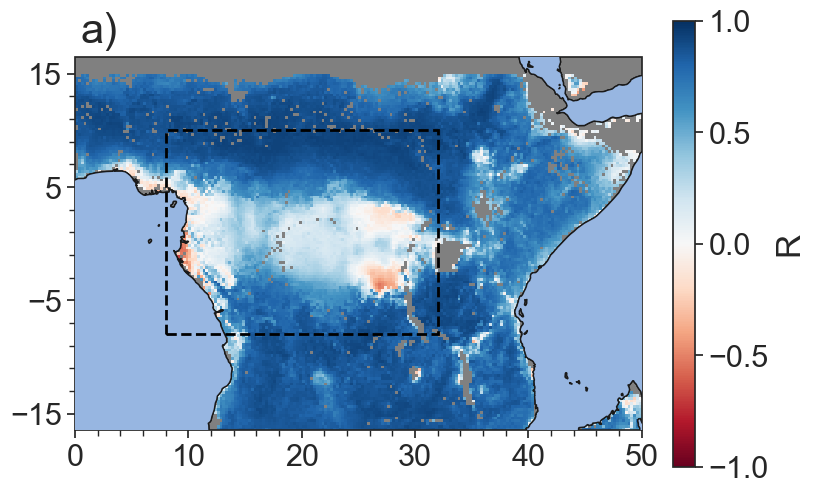

In [7]:
def plot_corr_map(data, panel, outfile):
    rect = Rectangle((8, -8), 24, 18, lw=2, edgecolor="black", facecolor="none",
                     ls="--", transform=ccrs.PlateCarree(), zorder=200)
    fig, ax = plt.subplots(figsize=(8, 6), subplot_kw={"projection": ccrs.PlateCarree()})
    im = ax.pcolormesh(data.lon, data.lat, data, transform=ccrs.PlateCarree(),
                       vmin=-1, vmax=1, cmap="RdBu")
    ax.set_facecolor("grey")
    ax.coastlines()
    ax.add_patch(rect)
    ax.add_feature(cfeature.OCEAN, zorder=100, edgecolor="k")
    ax.set_extent([0, 50, -15, 15])
    ax.set_xticks([0, 10, 20, 30, 40, 50], crs=ccrs.PlateCarree())
    ax.set_yticks([-15, -5, 5, 15], crs=ccrs.PlateCarree())
    ax.text(.01, 1.04, panel, fontsize=30, transform=ax.transAxes)
    cbar = fig.colorbar(im, ax=ax, fraction=0.036, pad=0.05)
    cbar.set_label("R")
    ax.minorticks_on()
    fig.savefig(outfile, bbox_inches="tight")
    plt.show()

plot_corr_map(
    TestCorr, "a)",
    "/Users/sworden/Documents/EqAfricaGPPETResults/Figure1b9.9.png"
)


In [8]:
corr = xr.corr(SIFFin,WBET,dim='time')

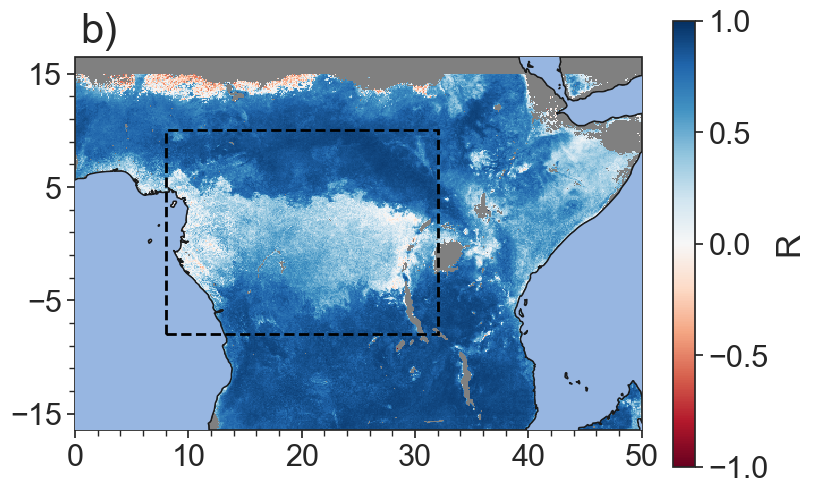

In [9]:
plot_corr_map(
    corr, "b)",
    "/Users/sworden/Documents/EqAfricaGPPETResults/WBETJPLSIFCorrelations12.5.png"
)


  Site      Years        Lat        Lon                  Vegetation  \
0  Mon  2008–2009 -15.437000  23.252000             Miombo woodland   
1  Tch  2006–2009  -4.289200  11.656400                     Savanna   
2  Ank  2011–2014   5.268500  -2.694200  Evergreen broadleaf forest   
3  Bfg  2008–2017   9.791000   1.718000  Deciduous broadleaf forest   
4  Db1  2022–2024   6.607338   2.543043                   Croplands   
5  Mkt  2019–2024  -3.425859  38.140663                   Croplands   
6  Chk  2022–2024  -3.666300  38.350185               Woody savanna   

        MAP_mm         R             p   n  
0   582.242300  0.965698  8.654138e-11  18  
1  1650.896250  0.866207  1.273746e-13  42  
2  1904.684750  0.400896  1.538888e-02  36  
3  1342.177600  0.372863  2.325065e-04  93  
4  1263.109000  0.541322  1.141461e-03  33  
5   284.975167  0.754192  1.935293e-11  56  
6   391.620333  0.767747  7.475168e-06  25  


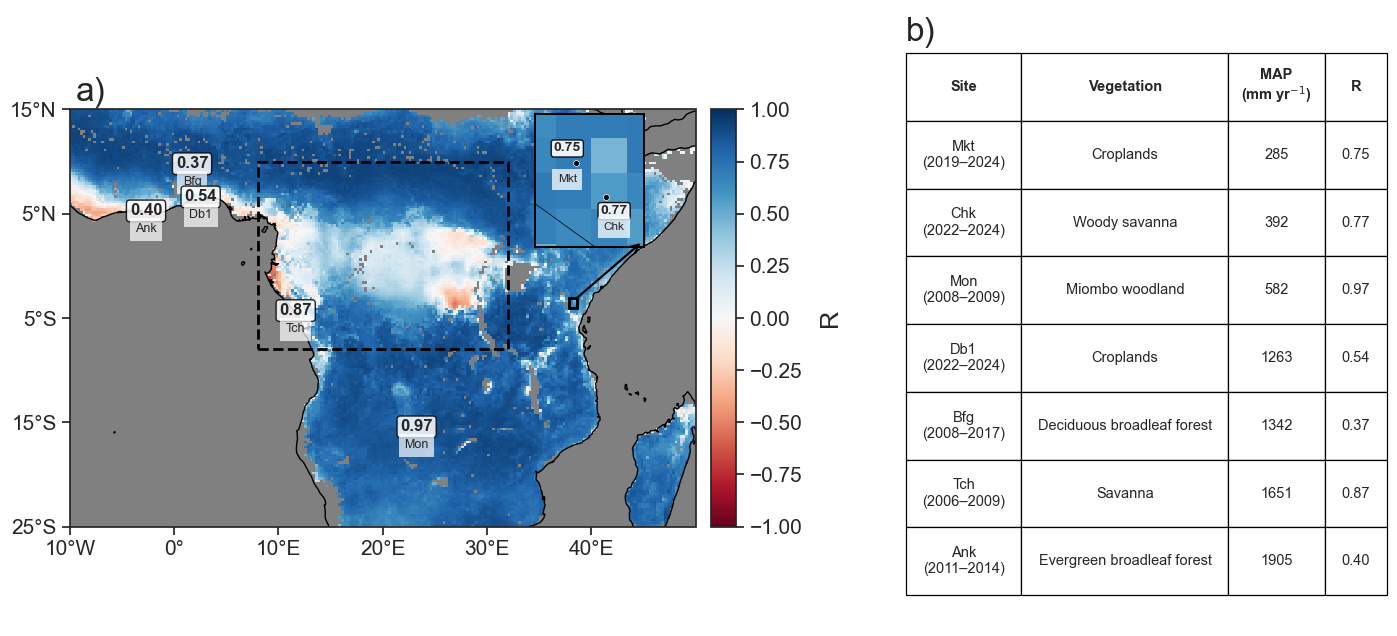

In [10]:
# FLUXNET helpers
def read_fluxnet(file):
    df = pd.read_csv(file, low_memory=False).replace(-9999, np.nan)

    if 'TIMESTAMP_START' in df.columns:
        df['time'] = pd.to_datetime(
            df['TIMESTAMP_START'].astype(str),
            format='%Y%m%d%H%M'
        )
        resolution = 'subdaily'

    elif 'TIMESTAMP' in df.columns:
        df['time'] = pd.to_datetime(
            df['TIMESTAMP'].astype(str),
            format='%Y%m'
        )
        resolution = 'monthly'

    else:
        raise ValueError("Need TIMESTAMP_START or TIMESTAMP.")

    return df.sort_values('time').set_index('time'), resolution

def year_range(df):
    if df.empty:
        return 'NA'

    y0 = df.index.min().year
    y1 = df.index.max().year
    return str(y0) if y0 == y1 else f'{y0}–{y1}'

def calc_site_stats(site):
    df, resolution = read_fluxnet(site['file'])

    # GPP-ET correlation
    corr_df = df.loc[site['start_date']:] if site.get('start_date') else df
    corr_df = corr_df[['GPP_DT_VUT_REF', 'LE_F_MDS']].apply(
        pd.to_numeric, errors='coerce'
    )

    if resolution == 'subdaily':
        corr_df = corr_df.resample('MS').mean()

    corr_df = corr_df.dropna()

    if len(corr_df) >= 3:
        # LE -> ET conversion is unnecessary for Pearson R:
        # multiplying LE by a positive constant does not change correlation
        R, p = pearsonr(corr_df['GPP_DT_VUT_REF'], corr_df['LE_F_MDS'])
    else:
        R, p = np.nan, np.nan

    # Mean annual precipitation from full tower record
    if 'P_F' not in df.columns:
        raise ValueError("P_F not found.")

    precip = pd.to_numeric(df['P_F'], errors='coerce')
    precip = precip.where(precip >= 0)

    if resolution == 'subdaily':
        monthly_p = precip.resample('MS').sum(min_count=1)
    else:
        monthly_p = precip * precip.index.days_in_month

    annual_p = monthly_p.resample('YS').sum(min_count=1)

    # Keep only complete calendar years
    complete = monthly_p.notna().resample('YS').sum() == 12
    annual_p = annual_p[complete].dropna()

    MAP = annual_p.mean() if len(annual_p) else np.nan

    return R, p, len(corr_df), year_range(corr_df), MAP

# Sites
sites = [
    dict(
        name='Mon',
        file='/Users/sworden/Downloads/FLX_ZM-Mon_FLUXNET2015_FULLSET_MM_2000-2009_2-4.csv',
        lat=-15.437, lon=23.252, veg='Miombo woodland',
        start_date='2008-07-01'
    ),
    dict(
        name='Tch',
        file='/Users/sworden/Downloads/EUF_CG-Tch_FLUXNET_FLUXMET_HH_2006-2009_v1.3_r1.csv',
        lat=-4.2892, lon=11.6564, veg='Savanna',
        start_date=None
    ),
    dict(
        name='Ank',
        file='/Users/sworden/Downloads/EUF_GH-Ank_FLUXNET_FLUXMET_HH_2011-2014_v1.3_r1.csv',
        lat=5.2685, lon=-2.6942, veg='Evergreen broadleaf forest',
        start_date=None
    ),
    dict(
        name='Bfg',
        file='/Users/sworden/Downloads/FLX_BJ-Bfg_FLUXNET_FLUXMET_HH_2008-2017_v1.3_r1.csv',
        lat=9.791, lon=1.718, veg='Deciduous broadleaf forest',
        start_date=None
    ),
    dict(
        name='Db1',
        file='/Users/sworden/Downloads/FLX_BJ-Db1_FLUXNET_FLUXMET_HH_2022-2024_v1.3_r1.csv',
        lat=6.607338, lon=2.543043, veg='Croplands',
        start_date=None
    ),
    dict(
        name='Mkt',
        file='/Users/sworden/Downloads/FLX_KE-Mkt_FLUXNET_FLUXMET_HH_2019-2024_v1.3_r1.csv',
        lat=-3.425859, lon=38.140663, veg='Croplands',
        start_date=None
    ),
    dict(
        name='Chk',
        file='/Users/sworden/Downloads/FLX_KE-Chk_FLUXNET_FLUXMET_HH_2022-2024_v1.3_r1.csv',
        lat=-3.666300, lon=38.350185, veg='Woody savanna',
        start_date=None
    ),
]

# Calculate tower statistics
rows = []

for site in sites:
    try:
        R, p, n, years, MAP = calc_site_stats(site)

    except Exception as e:
        print(f"Problem with {site['name']}: {e}")
        R, p, n, years, MAP = np.nan, np.nan, 0, 'NA', np.nan

    rows.append({
        'Site': site['name'],
        'Years': years,
        'Lat': site['lat'],
        'Lon': site['lon'],
        'Vegetation': site['veg'],
        'MAP_mm': MAP,
        'R': R,
        'p': p,
        'n': n
    })

site_df = pd.DataFrame(rows)
print(site_df)

# Figure
fig = plt.figure(figsize=(17, 8))
gs = fig.add_gridspec(1, 2, width_ratios=[1.30, 1], wspace=0.38)

ax = fig.add_subplot(gs[0, 0], projection=ccrs.PlateCarree())
ax_table = fig.add_subplot(gs[0, 1])

# a) Correlation map
cmap = plt.get_cmap('RdBu').copy()
cmap.set_bad('gray')

im = ax.pcolormesh(
    GPPMaster.lon, GPPMaster.lat, TestCorrMaster,
    vmin=-1, vmax=1, cmap=cmap,
    transform=ccrs.PlateCarree()
)

ax.set_facecolor('grey')
ax.coastlines()
ax.add_feature(cfeature.OCEAN, edgecolor='k')

ax.add_patch(Rectangle(
    (8, -8), 24, 18,
    fill=False, edgecolor='black', lw=2, ls='--',
    transform=ccrs.PlateCarree(), zorder=200
))

cax = inset_axes(
    ax, width='4%', height='100%', loc='lower left',
    bbox_to_anchor=(1.025, 0, 1, 1),
    bbox_transform=ax.transAxes, borderpad=0
)

cbar = fig.colorbar(im, cax=cax)
cbar.set_label('R', fontsize=18, labelpad=12)
cbar.ax.tick_params(labelsize=15)

ax.text(0.01, 1.02, 'a)', fontsize=24, transform=ax.transAxes)

ax.set_xticks([-10, 0, 10, 20, 30, 40], crs=ccrs.PlateCarree())
ax.set_yticks([-25, -15, -5, 5, 15], crs=ccrs.PlateCarree())
ax.xaxis.set_major_formatter(LongitudeFormatter())
ax.yaxis.set_major_formatter(LatitudeFormatter())
ax.tick_params(axis='both', labelsize=15)

# Tower labels, excluding Kenya pair
zoom_sites = {'Mkt', 'Chk'}

for _, row in site_df.iterrows():
    if not np.isfinite(row['R']) or row['Site'] in zoom_sites:
        continue

    ax.text(
        row['Lon'], row['Lat'], f"{row['R']:.2f}",
        transform=ccrs.PlateCarree(),
        fontsize=12, fontweight='bold',
        ha='center', va='center', zorder=300,
        bbox=dict(
            facecolor='white', edgecolor='black',
            boxstyle='round,pad=0.2', alpha=0.85
        )
    )

    ax.text(
        row['Lon'], row['Lat'] - 1.2, row['Site'],
        transform=ccrs.PlateCarree(),
        fontsize=9, ha='center', va='top', zorder=300,
        bbox=dict(facecolor='white', edgecolor='none', alpha=0.7)
    )

# Kenya zoom
zoom_lon = (37.85, 38.62)
zoom_lat = (-4.02, -3.08)

ax.add_patch(Rectangle(
    (zoom_lon[0], zoom_lat[0]),
    zoom_lon[1] - zoom_lon[0],
    zoom_lat[1] - zoom_lat[0],
    fill=False, edgecolor='black', lw=2,
    transform=ccrs.PlateCarree(), zorder=350
))

axins = ax.inset_axes(
    [0.67, 0.67, 0.32, 0.32],
    projection=ccrs.PlateCarree()
)

axins.set_extent(
    [zoom_lon[0], zoom_lon[1], zoom_lat[0], zoom_lat[1]],
    crs=ccrs.PlateCarree()
)

# FIX: use same map as main panel
axins.pcolormesh(
    GPPMaster.lon, GPPMaster.lat, TestCorrMaster,
    vmin=-1, vmax=1, cmap=cmap,
    transform=ccrs.PlateCarree()
)

axins.set_facecolor('grey')
axins.coastlines(linewidth=0.5)
axins.add_feature(cfeature.BORDERS, linewidth=0.5)
axins.set_xticks([])
axins.set_yticks([])

for spine in axins.spines.values():
    spine.set_linewidth(1.4)
    spine.set_edgecolor('black')

kenya_offsets = {
    'Mkt': (-0.06,  0.10, -0.06, -0.08),
    'Chk': ( 0.06, -0.10,  0.06, -0.18),
}

for _, row in site_df[site_df['Site'].isin(zoom_sites)].iterrows():
    if not np.isfinite(row['R']):
        continue

    dx_R, dy_R, dx_site, dy_site = kenya_offsets[row['Site']]

    axins.scatter(
        row['Lon'], row['Lat'],
        s=18, color='black', edgecolor='white', linewidth=0.5,
        transform=ccrs.PlateCarree(), zorder=450
    )

    axins.text(
        row['Lon'] + dx_R, row['Lat'] + dy_R, f"{row['R']:.2f}",
        transform=ccrs.PlateCarree(),
        fontsize=10, fontweight='bold',
        ha='center', va='center', zorder=500,
        bbox=dict(
            facecolor='white', edgecolor='black',
            boxstyle='round,pad=0.18', alpha=0.9
        )
    )

    axins.text(
        row['Lon'] + dx_site, row['Lat'] + dy_site, row['Site'],
        transform=ccrs.PlateCarree(),
        fontsize=8.5, ha='center', va='top', zorder=500,
        bbox=dict(facecolor='white', edgecolor='none', alpha=0.75)
    )

fig.add_artist(ConnectionPatch(
    xyA=(zoom_lon[1], zoom_lat[1]),
    coordsA=ax.transData,
    xyB=(0.97, 0.03),
    coordsB=axins.transAxes,
    arrowstyle='->',
    lw=1.6, color='black',
    mutation_scale=14,
    clip_on=False, zorder=600
))

# b) Flux tower table
ax_table.axis('off')
ax_table.text(0, 0.95, 'b)', fontsize=24, transform=ax_table.transAxes)

table_df = (
    site_df[['Site', 'Years', 'Vegetation', 'MAP_mm', 'R']]
    .sort_values('MAP_mm')
    .reset_index(drop=True)
)

table_df['Site'] = table_df['Site'] + '\n(' + table_df['Years'] + ')'
table_df['MAP_mm'] = table_df['MAP_mm'].map(
    lambda x: f'{x:.0f}' if np.isfinite(x) else 'nan'
)
table_df['R'] = table_df['R'].map(
    lambda x: f'{x:.2f}' if np.isfinite(x) else 'nan'
)

table_df = table_df[['Site', 'Vegetation', 'MAP_mm', 'R']]
table_df.columns = ['Site', 'Vegetation', 'MAP\n(mm yr$^{-1}$)', 'R']

table = ax_table.table(
    cellText=table_df.values,
    colLabels=table_df.columns,
    cellLoc='center', colLoc='center',
    bbox=[0, 0.05, 1, 0.88]
)

table.auto_set_font_size(False)
table.set_fontsize(10.5)

col_widths = [0.24, 0.43, 0.20, 0.13]

for (r, c), cell in table.get_celld().items():
    cell.set_width(col_widths[c])
    cell.set_edgecolor('black')
    cell.set_linewidth(0.9)
    cell.set_facecolor('white')
    cell.set_text_props(
        weight='bold' if r == 0 else 'normal',
        ha='center', va='center'
    )

table.scale(1, 1.12)

# Save
plt.savefig(
    '/Users/sworden/Documents/EqAfricaGPPETResults/SupplementaryFigure3.png',
    dpi=300, bbox_inches='tight'
)

plt.show()


## Figure 2

In [11]:
# Inputs
ds = xr.open_dataset('/Users/sworden/Documents/MODISLandCover/2022LCMODISAfrica.nc')
LC = ds.LC_Prop1.isel(time=0)
forest_codes = {11, 12, 13, 14, 15, 16}#, 21 22}
nodata_code  = 255

lat_target = xr.DataArray(np.arange(-19.875, 14.875 + 1e-12, 0.25), dims=("lat",))
lon_target = xr.DataArray(np.arange(0.125, 49.875 + 1e-12, 0.25), dims=("lon",))

# Forest boolean (mask nodata)
is_forest = xr.zeros_like(LC, dtype=bool)
for c in forest_codes:
    is_forest = is_forest | (LC == c)
is_forest = is_forest.where(LC != nodata_code)

#Build edges from centers ± 0.125°, pad with a tiny epsilon
step, half, eps = 0.25, 0.125, 1e-9
lat_edges = np.arange(float(lat_target.min()) - half - eps,
                      float(lat_target.max()) + half + eps, step)
lon_edges = np.arange(float(lon_target.min()) - half - eps,
                      float(lon_target.max()) + half + eps, step)

# Digitize LC coordinates to coarse bins
lat_idx = np.digitize(LC.lat.values, lat_edges)  # 1..(n_bins+1) possible at the far right
lon_idx = np.digitize(LC.lon.values, lon_edges)

# Clamp indices to valid bin range (1..n_bins)
nlat_bins = len(lat_edges) - 1
nlon_bins = len(lon_edges) - 1
lat_idx = np.clip(lat_idx, 1, nlat_bins)
lon_idx = np.clip(lon_idx, 1, nlon_bins)

# Flat table per pixel
nlat, nlon = LC.shape
df = pd.DataFrame({
    "lat_bin": np.repeat(lat_idx, nlon),
    "lon_bin": np.tile(lon_idx, nlat),
    "forest":  is_forest.values.ravel().astype(float)
})
df = df[np.isfinite(df["forest"])]

# Aggregate (pixel-count mean = forest fraction)
frac = (df.groupby(["lat_bin", "lon_bin"])["forest"]
          .mean()
          .rename("forest_frac")
          .reset_index())

lat_centers = lat_target.values[frac["lat_bin"].to_numpy() - 1]
lon_centers = lon_target.values[frac["lon_bin"].to_numpy() - 1]

# Assemble to 2D DA on exact target grid
da_points = xr.DataArray(
    frac["forest_frac"].to_numpy(),
    dims=("points",),
    coords={"points": np.arange(len(frac)),
            "lat": ("points", lat_centers),
            "lon": ("points", lon_centers)},
    name="forest_frac"
)
forest_frac_025 = (da_points
                   .set_index(points=["lat", "lon"])
                   .unstack("points")
                   .reindex(lat=lat_target, lon=lon_target))

# Forest mask (≥ 80%)
forest_mask_025 = (forest_frac_025 >= 0.80)

#### Supplementary Figure 2

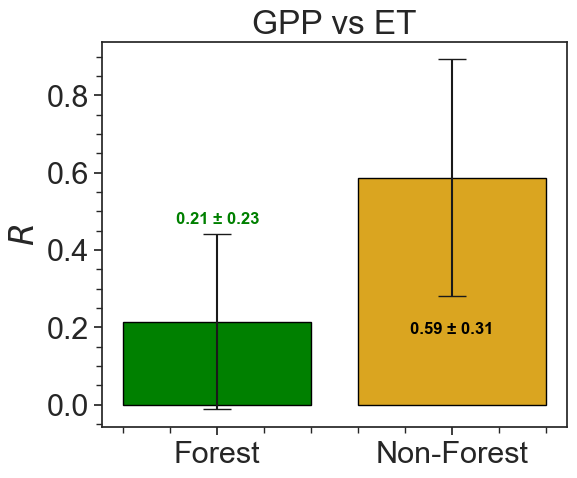

In [12]:
TestCorrFin=TestCorr.sel(lat=slice(-5,8),lon=slice(8,30))
mask=forest_mask_025.sel(lat=slice(-5,8),lon=slice(8,30))
TestCorrFor = TestCorrFin.where(forest_mask_025 == True)
TestCorrNoFor = TestCorrFin.where(forest_mask_025 == False)

Corrs = np.array([np.nanmean(TestCorrFor), np.nanmean(TestCorrNoFor)])
CorrsStd = np.array([np.nanstd(TestCorrFor), np.nanstd(TestCorrNoFor)])

labels = ['Forest', 'Non-Forest']

#Bar plot with error bars
fig, ax = plt.subplots(figsize=(6, 5))
bars = ax.bar(labels, Corrs, yerr=CorrsStd, capsize=10,
              color=['green', 'goldenrod'], edgecolor='black')

ax.set_ylabel('$R$')
ax.set_title('GPP vs ET')
plt.minorticks_on()

#Annotate each bar
for bar, mean, std, label in zip(bars, Corrs, CorrsStd, labels):
    height = bar.get_height()
    xpos = bar.get_x() + bar.get_width() / 2

    if label == "Forest":
        # Text above bar
        ax.text(xpos, height + std + 0.02,
                f"{mean:.2f} ± {std:.2f}",
                ha="center", va="bottom",
                fontsize=12, fontweight='bold',
                color="green")
    else:
        # Text inside the bar, near the top
        ax.text(xpos, height - (0.7 * height),  # 5% below top
                f"{mean:.2f} ± {std:.2f}",
                ha="center", va="bottom",
                fontsize=12, fontweight='bold',
                color="black")

plt.savefig('/Users/sworden/Documents/EqAfricaGPPETResults/SupplementaryFigure2.png',
            format='png', bbox_inches='tight')
plt.show()


In [13]:
VPDFin = VPDArr.sel(lat=slice(-8, 8), lon=slice(8, 30)).mean(dim='time')


In [14]:
with xr.open_dataset("/Users/sworden/Documents/AfricaAnnualChangeJRC/JRC_to_AET_4class_v1.nc") as ds:
    JRC_static = ds.bucket4.load()
bucket4 = JRC_static


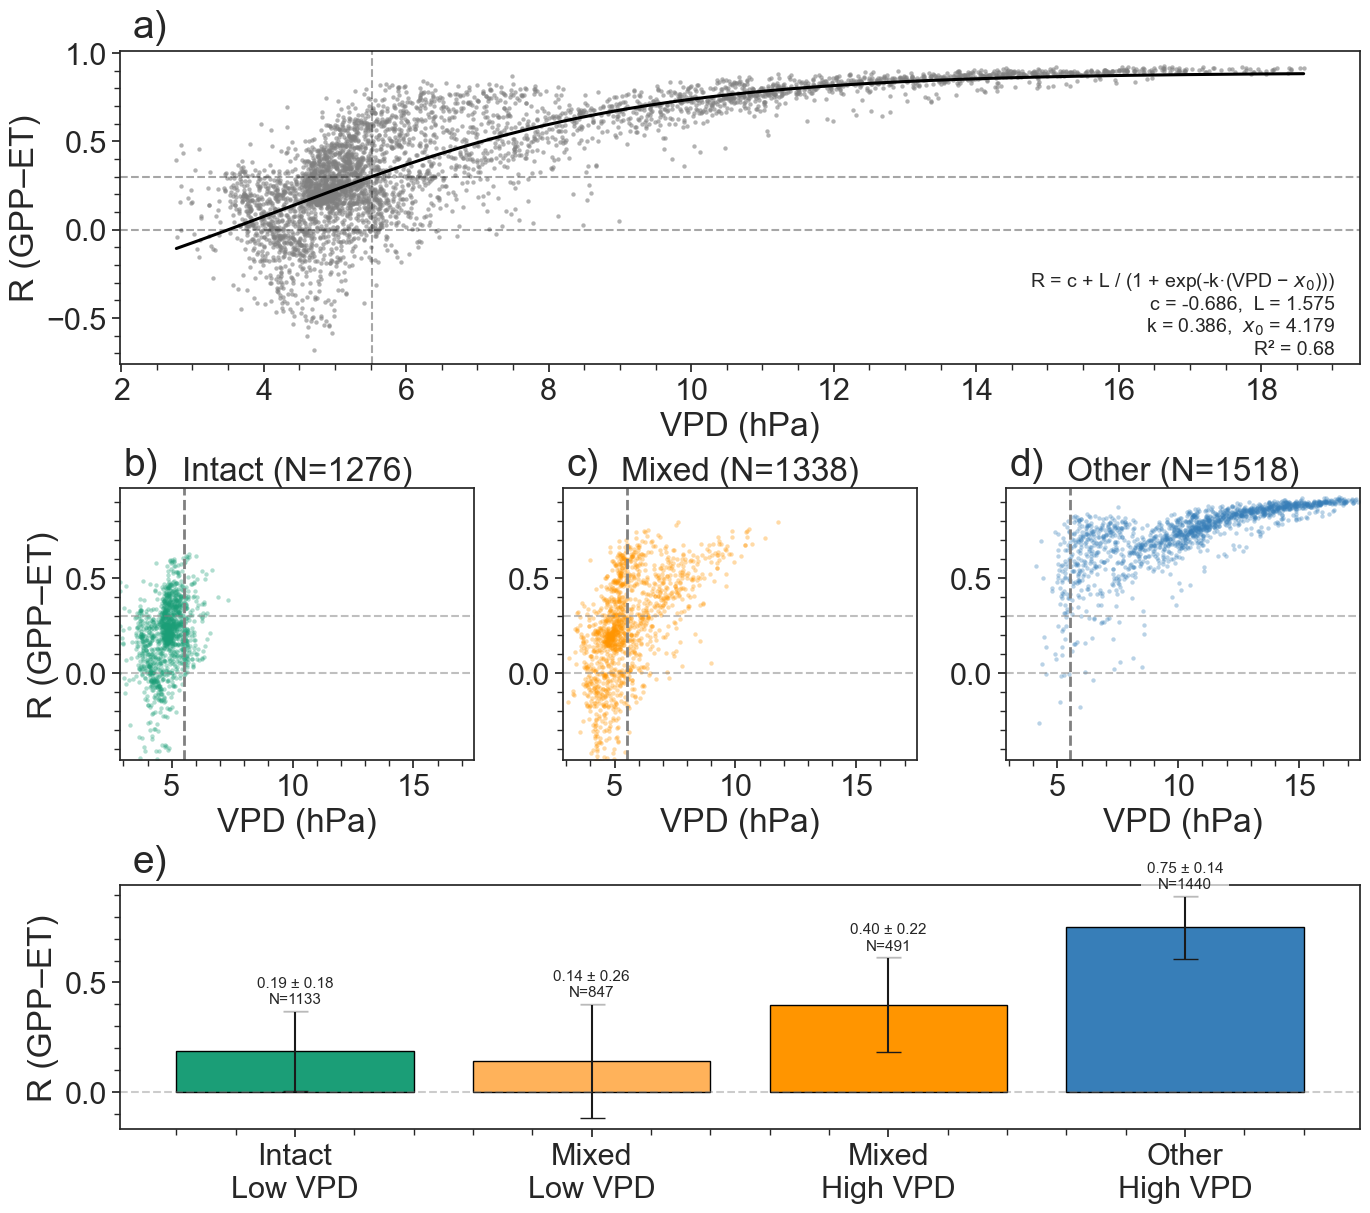

In [15]:
# SETTINGS
R_thr   = 0.3
VPD_THR_LINE = 5.51  # vertical line for panels b–d (VPD threshold)
OUTPNG  = "/Users/sworden/Documents/EqAfricaGPPETResults/EquatorialAfrica_R_vs_VPD_5panel.png"

# INPUTS
VPD_da = VPDFin
R_da   = TestCorr.sel(lat=slice(-5, 8), lon=slice(8, 30))
B_da   = JRC_static  # 0 Intact, 1 Disturbed, 2 Other, 3 Mixed

# HELPERS

def r2_score(y_true, y_hat):
    y_true = np.asarray(y_true, float)
    y_hat  = np.asarray(y_hat, float)
    ss_res = np.sum((y_true - y_hat)**2)
    ss_tot = np.sum((y_true - np.mean(y_true))**2)
    return 1 - ss_res/ss_tot if ss_tot > 0 else np.nan

def logistic(x, L, k, x0, c):
    return c + L / (1 + np.exp(-k * (x - x0)))

# STANDARDIZE + ALIGN (once)
VPD_da = _drop_time_if_present(_ensure_latlon(VPD_da))
R_da   = _drop_time_if_present(_ensure_latlon(R_da))
B_da   = _drop_time_if_present(_ensure_latlon(B_da))

VPD2, R2, B2 = xr.align(VPD_da, R_da, B_da, join="inner")

# PANEL A: logistic fit on all pixels
x_all = VPD2.values.ravel().astype(float)
y_all = R2.values.ravel().astype(float)

m = np.isfinite(x_all) & np.isfinite(y_all) & (x_all > 0)
x_fit = x_all[m]
y_fit = y_all[m]

idx = np.argsort(x_fit)
xs, ys = x_fit[idx], y_fit[idx]

# data-driven guesses + bounds
c0   = np.nanpercentile(y_fit, 5)
L0   = np.nanpercentile(y_fit, 95) - c0
x0_0 = np.nanmedian(x_fit)
k0   = 1.5

p0 = [L0, k0, x0_0, c0]
bounds = ([-np.inf, 0.01, 0.0, -np.inf],
          [ np.inf, 50.0, 10.0,  np.inf])

popt, _ = curve_fit(logistic, x_fit, y_fit, p0=p0, bounds=bounds, maxfev=200000)
L, k, x0, c = popt

yhat = logistic(x_fit, *popt)
r2   = r2_score(y_fit, yhat)

# Solve VPD* where R = R_thr
VPD_star = np.nan
q = (R_thr - c) / L if np.isfinite(L) and (L != 0) else np.nan
if np.isfinite(q) and (0 < q < 1) and np.isfinite(k) and (k != 0):
    VPD_star = x0 - (1.0 / k) * np.log((1.0 / q) - 1.0)

xg = np.linspace(np.nanmin(xs), np.nanmax(xs), 600)
yg = logistic(xg, *popt)

eq_text = (
    "R = c + L / (1 + exp(-k·(VPD − $x_0$)))\n"
    f"c = {c:.3f},  L = {L:.3f}\n"
    f"k = {k:.3f},  $x_0$ = {x0:.3f}\n"
    f"R² = {r2:.2f}"
)

# PANELS B–D: scatter by class (exclude disturbed)
xv = VPD2.values.ravel().astype(float)
yv = R2.values.ravel().astype(float)
cv = B2.values.ravel()

m = np.isfinite(xv) & np.isfinite(yv) & np.isfinite(cv)
xv = xv[m]
yv = yv[m]
cv = cv[m].astype(int)

labels4 = {0: "Intact", 1: "Disturbed", 2: "Other", 3: "Mixed"}
panel_colors = {
    0: "#1b9e77",  # intact
    3: "#ff9500",  # mixed
    2: "#377eb8",  # other
}

keep3 = (cv == 0) | (cv == 2) | (cv == 3)
xv3, yv3, cv3 = xv[keep3], yv[keep3], cv[keep3]

# robust shared limits for B–D
if xv3.size:
    x_lo, x_hi = np.nanpercentile(xv3, [1, 99])
else:
    x_lo, x_hi = 0, 1
if yv3.size:
    y_lo, y_hi = np.nanpercentile(yv3, [1, 99])
else:
    y_lo, y_hi = -1, 1

x_pad = 0.05 * (x_hi - x_lo) if (x_hi > x_lo) else 0.1
y_pad = 0.05 * (y_hi - y_lo) if (y_hi > y_lo) else 0.1
xlim_bd = (x_lo - x_pad, x_hi + x_pad)
ylim_bd = (y_lo - y_pad, y_hi + y_pad)

# PANEL E: bar plot (4 groups) using VPD_star as threshold
VPD_THR_BAR = VPD_star if np.isfinite(VPD_star) else VPD_THR_LINE

is_intact = (cv == 0)
is_mixed  = (cv == 3)
is_other  = (cv == 2)

lowV  = xv < VPD_THR_BAR
highV = xv >= VPD_THR_BAR

groups = [
    ("Intact\nLow VPD", is_intact & lowV),
    ("Mixed\nLow VPD",  is_mixed  & lowV),
    ("Mixed\nHigh VPD", is_mixed  & highV),
    ("Other\nHigh VPD", is_other  & highV),
]

means, stds, Ns = [], [], []
for _, mask in groups:
    m0, s0, n0 = mean_std_n(yv[mask])
    means.append(m0); stds.append(s0); Ns.append(n0)

means = np.array(means)
stds  = np.array(stds)
Ns    = np.array(Ns)
bar_labels = [g[0] for g in groups]

C_INTACT = "#1b9e77"
C_MIX_L  = "#ffb25a"
C_MIX_H  = "#ff9500"
C_OTHER  = "#377eb8"
bar_colors = [C_INTACT, C_MIX_L, C_MIX_H, C_OTHER]

# FIGURE LAYOUT:
#   row 0: a) spans all columns
#   row 1: b) c) d)
#   row 2: e) spans all columns
fig = plt.figure(figsize=(16, 14))
gs  = GridSpec(3, 3, figure=fig, height_ratios=[1.15, 1.0, 0.9], hspace=0.45, wspace=0.25)

axA = fig.add_subplot(gs[0, :])
axB = fig.add_subplot(gs[1, 0])
axC = fig.add_subplot(gs[1, 1])
axD = fig.add_subplot(gs[1, 2])
axE = fig.add_subplot(gs[2, :])

#(a) logistic
axA.scatter(xs, ys, s=10, color="grey", alpha=0.6, linewidths=0)
axA.plot(xg, yg, color="black", linewidth=2.2)
axA.axhline(R_thr, linestyle="--", alpha=0.35, color="black")
axA.axhline(0,    linestyle="--", alpha=0.35, color="black")
if np.isfinite(VPD_star):
    axA.axvline(VPD_star, linestyle="--", alpha=0.35, color="black", zorder=5)

axA.set_xlabel("VPD (hPa)")
axA.set_ylabel("R (GPP–ET)")
axA.minorticks_on()

axA.text(
    0.98, 0.02, eq_text,
    transform=axA.transAxes,
    ha="right", va="bottom",
    fontsize=14,
    bbox=dict(facecolor="white", alpha=0.75, edgecolor="none")
)

#(b–d) class scatters
def plot_class(ax, class_id):
    mk = (cv3 == class_id)
    xk = xv3[mk]
    yk = yv3[mk]

    ax.scatter(xk, yk, s=10, alpha=0.35, c=panel_colors[class_id], linewidths=0)
    ax.axhline(0.0, color="grey", linestyle="--", alpha=0.5)
    ax.axhline(R_thr, color="grey", linestyle="--", alpha=0.5)
    if VPD_THR_LINE is not None:
        ax.axvline(VPD_THR_LINE, color="grey", linestyle="--", linewidth=2)

    ax.set_title(f"{labels4[class_id]} (N={xk.size})")
    ax.set_xlim(*xlim_bd)
    ax.set_ylim(*ylim_bd)
    ax.set_xlabel("VPD (hPa)")
    ax.minorticks_on()

plot_class(axB, 0)  # Intact
plot_class(axC, 3)  # Mixed
plot_class(axD, 2)  # Other

axB.set_ylabel("R (GPP–ET)")
axC.set_ylabel("")
axD.set_ylabel("")

#(e) bar plot
bars = axE.bar(bar_labels, means, yerr=stds, capsize=9,
               color=bar_colors, edgecolor="black")
axE.set_ylabel("R (GPP–ET)")
axE.minorticks_on()
axE.axhline(0.0, color="grey", linestyle="--", alpha=0.4)

# annotate
for bar, mean, std, n in zip(bars, means, stds, Ns):
    xpos = bar.get_x() + bar.get_width() / 2
    height = bar.get_height()
    bump = (std if np.isfinite(std) else 0.0) + 0.02
    axE.text(
        xpos, height + bump,
        f"{mean:.2f} ± {std:.2f}\nN={n}",
        ha="center", va="bottom",
        fontsize=11,
        bbox=dict(facecolor="white", alpha=0.7, edgecolor="none")
    )

#panel labels a–e
panel_fs = 28
axA.text(0.01, 1.02, "a)", transform=axA.transAxes, fontsize=panel_fs, va="bottom", ha="left")
axB.text(0.01, 1.02, "b)", transform=axB.transAxes, fontsize=panel_fs, va="bottom", ha="left")
axC.text(0.01, 1.02, "c)", transform=axC.transAxes, fontsize=panel_fs, va="bottom", ha="left")
axD.text(0.01, 1.02, "d)", transform=axD.transAxes, fontsize=panel_fs, va="bottom", ha="left")
axE.text(0.01, 1.02, "e)", transform=axE.transAxes, fontsize=panel_fs, va="bottom", ha="left")

fig.savefig(OUTPNG, dpi=300, bbox_inches="tight")
plt.show()


## Figure 3

In [16]:
TrendArr=np.load('/Users/sworden/Documents/CongoGPPETArrays/TrendArr.npy')
TrendArrlon=np.load('/Users/sworden/Documents/CongoGPPETArrays/TrendArrlon.npy')
TrendArrlat=np.load('/Users/sworden/Documents/CongoGPPETArrays/TrendArrlat.npy')
TrendArr=xr.DataArray(TrendArr,coords=[TrendArrlat, TrendArrlon], dims=['lat','lon'])

In [17]:
#   R1: 3.5–7N,   8–30E
#   R2: 8S–0,    15–30E
#   R3: 5S–5N,    8–30E
TrendArrAIRS=TrendArr[::-1,:].interp(lat=VPDArrAIRS.lat,lon=VPDArrAIRS.lon,method='linear')
GPPR1=GPPNew.sel(lat=slice(3.5,7),lon=slice(8, 30)).where(TrendArr>0)
ETR1=AET.sel(lat=slice(3.5,7),lon=slice(8, 30)).where(TrendArr>0)
VPDER1=VPDArr.sel(lat=slice(3.5,7),lon=slice(8, 30)).where(TrendArr>0)
VPDAR1=VPDArrAIRS[:,::-1,:].sel(lat=slice(3.5,7),lon=slice(8, 30)).where(TrendArrAIRS>0)

GPPR2=GPPNew.sel(lat=slice(-8,0),lon=slice(15,30)).where(TrendArr>0)
ETR2=AET.sel(lat=slice(-8,0),lon=slice(15,30)).where(TrendArr>0)
VPDER2=VPDArr.sel(lat=slice(-8,0),lon=slice(15,30)).where(TrendArr>0)
VPDAR2=VPDArrAIRS[:,::-1,:].sel(lat=slice(-8,0),lon=slice(15,30)).where(TrendArrAIRS>0)

GPPR3=GPPNew.sel(lat=slice(-5,5),lon=slice(8,30)).where(TrendArr<=0)
ETR3=AET.sel(lat=slice(-5,5),lon=slice(8,30)).where(TrendArr<=0)
VPDER3=VPDArr.sel(lat=slice(-5,5),lon=slice(8,30)).where(TrendArr<=0)
VPDAR3=VPDArrAIRS[:,::-1,:].sel(lat=slice(-5,5),lon=slice(8,30)).where(TrendArrAIRS<=0)

In [18]:
WIN = 36  # 36-month window

# helpers
def to_1d_time(da: xr.DataArray) -> xr.DataArray:
    if 'time' not in da.dims:
        raise ValueError("DataArray must have a 'time' dimension.")
    spatial_dims = [d for d in da.dims if d != 'time']
    return da.mean(dim=spatial_dims, skipna=True) if spatial_dims else da


def as_month_start(da: xr.DataArray) -> xr.DataArray:
    """Coerce time coords to month-start timestamps so different sources match exactly."""
    ts = pd.to_datetime(da['time'].values).to_period('M').to_timestamp(how='start')
    da2 = da.assign_coords(time=ts).sortby('time')

    if da2.indexes.get('time') is not None and da2.indexes['time'].duplicated().any():
        da2 = da2.groupby('time').mean('time')

    return da2


def rolling_r(x: xr.DataArray, y: xr.DataArray, win: int = 36):
    # align y to x
    y = y.reindex(time=x.time)

    xv = x.values.astype(float)
    yv = y.values.astype(float)

    n = xv.size

    if n < win:
        raise ValueError(f"Series length {n} is shorter than window {win}.")

    r = np.full(n - win + 1, np.nan)

    for i in range(n - win + 1):
        xi = xv[i:i+win]
        yi = yv[i:i+win]

        m = np.isfinite(xi) & np.isfinite(yi)

        if (
            m.sum() >= 3
            and np.nanstd(xi[m]) > 0
            and np.nanstd(yi[m]) > 0
        ):
            r[i] = np.corrcoef(xi[m], yi[m])[0, 1]

    # right-aligned time axis
    t = x.time[win-1:].values

    return t, r


def rolling_mean(ser: xr.DataArray, win=36):
    return ser.rolling(time=win, min_periods=win).mean()


def align_exact_to(t_axis, ser_1d: xr.DataArray):
    """Exact reindex to given t_axis."""
    return ser_1d.reindex(
        time=pd.DatetimeIndex(t_axis)
    ).values


def pair_metrics(x, y):
    """Return N, Pearson r, R², slope/intercept, and p-value."""

    x = np.asarray(x, float)
    y = np.asarray(y, float)

    m = np.isfinite(x) & np.isfinite(y)
    N = int(m.sum())

    if N < 3:
        return {
            "N": 0,
            "r": np.nan,
            "R2": np.nan,
            "slope": np.nan,
            "intercept": np.nan,
            "p_slope": np.nan
        }

    r, p_r = pearsonr(x[m], y[m])
    slope, intercept, r_val, p_slope, _ = linregress(x[m], y[m])

    return {
        "N": N,
        "r": r,
        "R2": r**2,
        "slope": slope,
        "intercept": intercept,
        "p_slope": p_slope
    }

regs = [
    {
        'title': 'R1',
        'gpp': GPPR1,
        'et': ETR1,
        'vpdE': VPDER1
    },
    {
        'title': 'R2',
        'gpp': GPPR2,
        'et': ETR2,
        'vpdE': VPDER2
    },
    {
        'title': 'R3',
        'gpp': GPPR3,
        'et': ETR3,
        'vpdE': VPDER3
    },
]

summary_rows = []

for reg in regs:

    title = reg['title']

    # 1. Spatial mean and make all timestamps month-start
    gpp = as_month_start(to_1d_time(reg['gpp']))
    et = as_month_start(to_1d_time(reg['et']))
    vpdE = as_month_start(to_1d_time(reg['vpdE']))

    # 2. 36-month rolling GPP-ET correlation
    t_r_raw, r36_raw = rolling_r(
        gpp,
        et,
        win=WIN
    )

    # 3. 36-month rolling mean VPD
    vpdE36 = rolling_mean(
        vpdE,
        win=WIN
    )

    # 4. Put VPD36 onto exactly the same time axis as r36
    vpdE_on_r_raw = align_exact_to(
        t_r_raw,
        vpdE36
    )

    # 5. Relationship between rolling GPP-ET correlation and rolling VPD
    m1 = pair_metrics(
        r36_raw,
        vpdE_on_r_raw
    )

    print(f"\n=== {title} ===")
    print(
        f"RAW r36 vs VPD36 -> "
        f"N={m1['N']}, "
        f"r={m1['r']:.3f}, "
        f"R²={m1['R2']:.3f}, "
        f"slope={m1['slope']:.4f}, "
        f"p(slope)={m1['p_slope']:.3g}"
    )

    summary_rows.append({
        "Region": title,
        "N raw~VPD": m1["N"],
        "r raw~VPD": m1["r"],
        "R2 raw~VPD": m1["R2"],
        "slope raw~VPD": m1["slope"],
        "p(slope) raw~VPD": m1["p_slope"],
    })


summary = pd.DataFrame(summary_rows)

print("\n--- Summary (R²) ---")
print(summary)


=== R1 ===
RAW r36 vs VPD36 -> N=457, r=0.556, R²=0.309, slope=5.0887, p(slope)=2.09e-38

=== R2 ===
RAW r36 vs VPD36 -> N=457, r=0.619, R²=0.384, slope=1.8299, p(slope)=8.97e-50

=== R3 ===
RAW r36 vs VPD36 -> N=457, r=-0.435, R²=0.190, slope=-1.2451, p(slope)=1.45e-22

--- Summary (R²) ---
  Region  N raw~VPD  r raw~VPD  R2 raw~VPD  slope raw~VPD  p(slope) raw~VPD
0     R1        457   0.555798    0.308912       5.088663      2.087303e-38
1     R2        457   0.619456    0.383726       1.829893      8.969618e-50
2     R3        457  -0.435409    0.189581      -1.245135      1.449529e-22


In [19]:
with xr.open_dataset(
    "/Users/sworden/Documents/AnnualChange/JRC_TMF_AnnualChange_bucket4_on_AETgrid_8_30E_-8_10N_ALLYEARS.nc"
) as ds:
    JRC_annual = ds.bucket4.load()


#### Supplementary Figure 3


Region 1 (North)  (start=1990-01-01, end=2022-01-01):
  Intact    : start=  0.101   end=  0.047   Δ= -0.054
  Disturbed : start=  0.000   end=  0.003   Δ= +0.003
  Other     : start=  0.694   end=  0.664   Δ= -0.030
  Mixed     : start=  0.205   end=  0.287   Δ= +0.082

Region 2 (South)  (start=1990-01-01, end=2022-01-01):
  Intact    : start=  0.388   end=  0.250   Δ= -0.137
  Disturbed : start=  0.000   end=  0.033   Δ= +0.033
  Other     : start=  0.353   end=  0.332   Δ= -0.021
  Mixed     : start=  0.260   end=  0.385   Δ= +0.125

Region 3 (Central)  (start=1990-01-01, end=2022-01-01):
  Intact    : start=  0.777   end=  0.542   Δ= -0.235
  Disturbed : start=  0.000   end=  0.016   Δ= +0.016
  Other     : start=  0.122   end=  0.121   Δ= -0.001
  Mixed     : start=  0.102   end=  0.321   Δ= +0.219


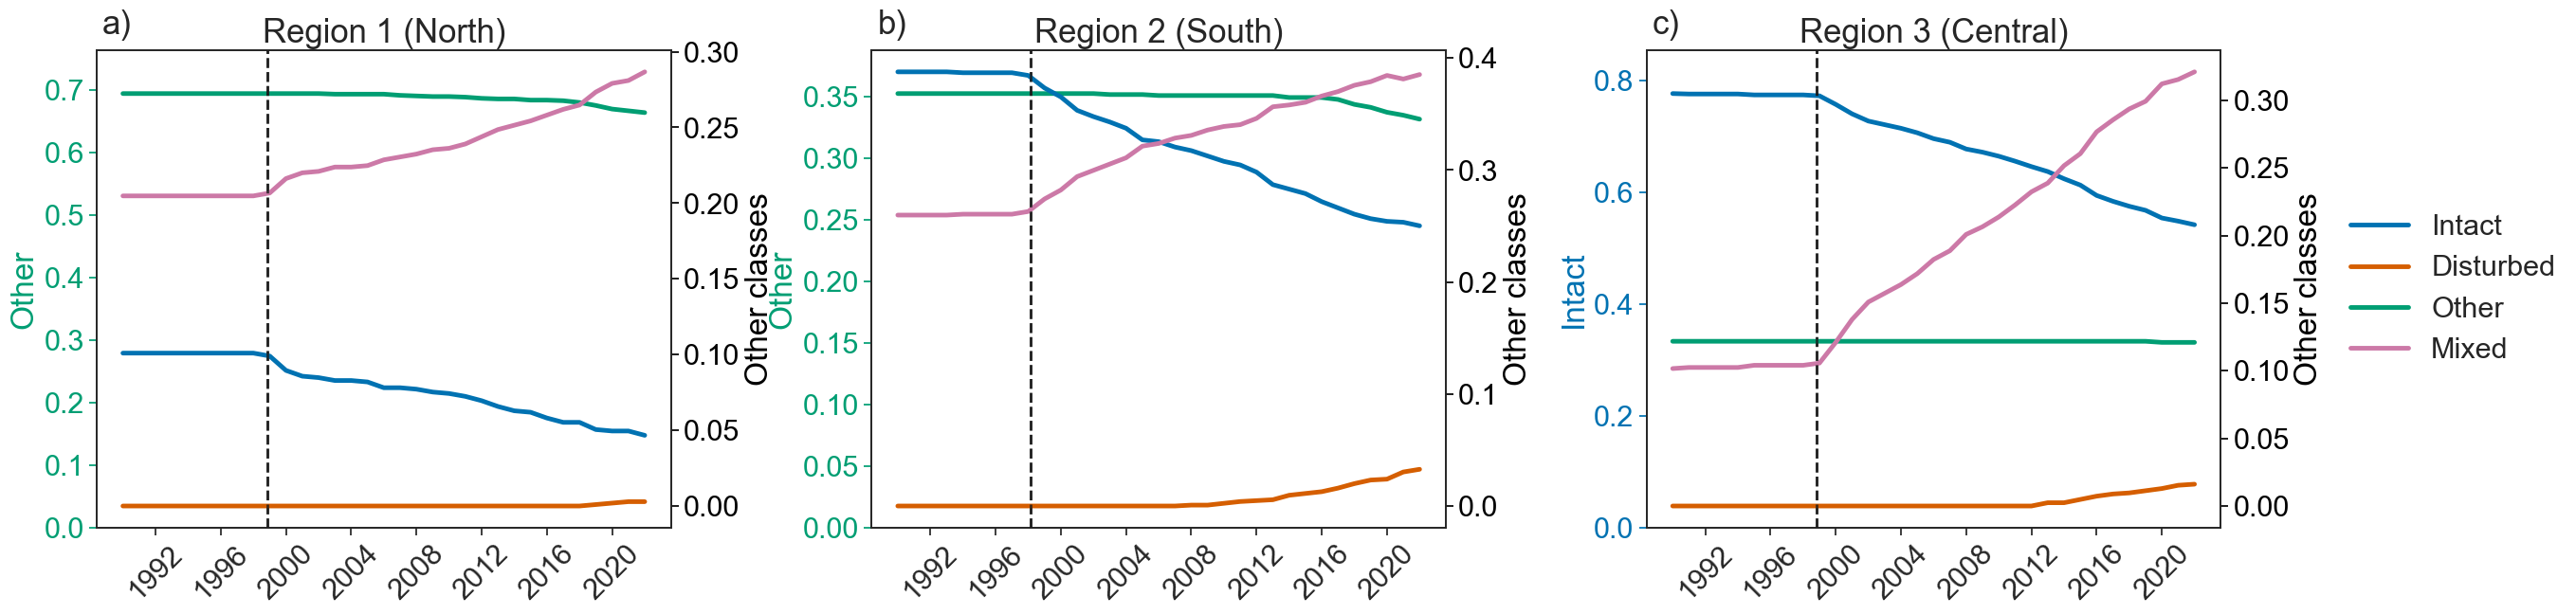

In [20]:
# Inputs
JRC   = JRC_annual   # (time, lat, lon)
TREND = TrendArr # (lat, lon) on same grid as JRC

labels = {0: "Intact", 1: "Disturbed", 2: "Other", 3: "Mixed"}
colors = {0: "#0072B2", 1: "#D55E00", 2: "#009E73", 3: "#CC79A7"}

# Helpers (lat/lon can be increasing or decreasing)

def jrc_region(JRC, TREND, lat1, lat2, lon1, lon2, trend_keep):
    j = sel_range(sel_range(JRC, "lat", lat1, lat2), "lon", lon1, lon2)
    t = sel_range(sel_range(TREND, "lat", lat1, lat2), "lon", lon1, lon2)
    return j.where(trend_keep(t))  # broadcast TREND across time

def frac_time_series(JRC_reg):
    valid = (JRC_reg >= 0)
    den   = valid.sum(dim=("lat", "lon"))

    frac = {}
    for k in [0, 1, 2, 3]:
        num = ((JRC_reg == k) & valid).sum(dim=("lat", "lon"))
        frac[k] = (num / den).where(den > 0).astype("float32")
    return frac

def print_begin_end_fracs(frac, region_name):
    """
    Print beginning, ending, and (end-start) fractions for each class.
    Uses the first and last time indices where any class fraction is finite.
    """
    any_valid = None
    for k in [0, 1, 2, 3]:
        v = np.isfinite(frac[k].values)
        any_valid = v if any_valid is None else (any_valid | v)

    if any_valid is None or not np.any(any_valid):
        print(f"\n{region_name}: no valid fractions to report.")
        return

    i0 = int(np.argmax(any_valid))  # first valid
    i1 = int(len(any_valid) - 1 - np.argmax(any_valid[::-1]))  # last valid

    t0 = frac[0]["time"].values[i0]
    t1 = frac[0]["time"].values[i1]

    print(
        f"\n{region_name}  (start={np.datetime_as_string(t0, unit='D')}, "
        f"end={np.datetime_as_string(t1, unit='D')}):"
    )

    for k in [0, 1, 2, 3]:
        v0 = float(frac[k].values[i0]) if np.isfinite(frac[k].values[i0]) else np.nan
        v1 = float(frac[k].values[i1]) if np.isfinite(frac[k].values[i1]) else np.nan
        dv = v1 - v0 if (np.isfinite(v0) and np.isfinite(v1)) else np.nan

        print(f"  {labels[k]:<10s}: start={v0:7.3f}   end={v1:7.3f}   Δ={dv:+7.3f}")

# Plot into provided axes (1x3)
def plot_jrc_dynamic_axes(ax1, JRC_reg, title, panel_label, vdate="1998-09-01",
                          legend_out=False, legend_anchor=(1.02, 0.5), lw=3.5):
    frac = frac_time_series(JRC_reg)

    # PRINT beginning + ending fractions for this region
    print_begin_end_fracs(frac, title)

    # choose "dominant" class by time-mean fraction
    means = {k: float(frac[k].mean("time", skipna=True)) for k in [0, 1, 2, 3]}
    left_k = min(means, key=lambda k: (-np.nan_to_num(means[k], nan=-1e9), k))
    right_ks = [k for k in [0, 1, 2, 3] if k != left_k]

    # left axis: dominant class
    l_left, = ax1.plot(JRC_reg["time"], frac[left_k], color=colors[left_k],
                       label=labels[left_k], linewidth=lw)
    ax1.set_ylabel(labels[left_k], color=colors[left_k])
    ax1.tick_params(axis="y", colors=colors[left_k])

    ymax_left = float(frac[left_k].max(skipna=True))
    ax1.set_ylim(0, 1.1 * ymax_left if np.isfinite(ymax_left) and ymax_left > 0 else 1)

    # right axis: remaining 3 classes
    ax2 = ax1.twinx()
    lines = [l_left]
    for k in right_ks:
        l, = ax2.plot(JRC_reg["time"], frac[k], color=colors[k],
                      label=labels[k], linewidth=lw)
        lines.append(l)
    ax2.set_ylabel("Other classes", color="black")
    ax2.tick_params(axis="y", colors="black")

    # vertical marker
    if vdate is not None:
        vd = np.datetime64(vdate)
        ax1.axvline(vd, color="k", linewidth=2, linestyle="--", alpha=0.8, zorder=10)
        ax2.axvline(vd, color="k", linewidth=2, linestyle="--", alpha=0.8, zorder=10)

    # titles + panel label
    ax1.set_title(title, fontsize=25)
    ax1.text(0.01, 1.02, panel_label, transform=ax1.transAxes,
             fontsize=25, ha="left", va="bottom")

    # legend
    if legend_out:
        ax1.legend(lines, [ln.get_label() for ln in lines],
                   frameon=False, loc="center left", bbox_to_anchor=legend_anchor)

    return ax2, lines

# Build 3 regions
JRC_N = jrc_region(JRC, TREND,  3.5,  7.0,  8.0, 30.0, trend_keep=lambda t: t > 0)   # Trend > 0
JRC_S = jrc_region(JRC, TREND, -8.0,  0.0, 15.0, 30.0, trend_keep=lambda t: t > 0)   # Trend > 0
JRC_C = jrc_region(JRC, TREND, -5.0,  5.0,  8.0, 30.0, trend_keep=lambda t: t <= 0)  # Trend <= 0

out_png = "/Users/sworden/Documents/EqAfricaGPPETResults/JRCAnnualChange_3Regions_1x3.png"

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(28, 7), sharex=True)
fig.subplots_adjust(left=0.06, right=0.86, top=0.90, bottom=0.18, wspace=0.35)

ax2_a, lines_a = plot_jrc_dynamic_axes(
    axes[0], JRC_N, "Region 1 (North)", "a)", vdate="1998-11-01",
    legend_out=False
)

ax2_b, lines_b = plot_jrc_dynamic_axes(
    axes[1], JRC_S, "Region 2 (South)", "b)", vdate="1998-03-01",
    legend_out=False
)

ax2_c, lines_c = plot_jrc_dynamic_axes(
    axes[2], JRC_C, "Region 3 (Central)", "c)", vdate="1998-11-01",
    legend_out=True, legend_anchor=(1.18, 0.5)
)

# x-axis formatting
for ax in axes:
    ax.set_xlabel("")  # remove "Time"
    ax.tick_params(axis="x", labelrotation=45)

plt.savefig(out_png, dpi=300, format="png", bbox_inches="tight")
plt.show()


### Figure 3

Figure 3 breakpoint years: {'Reg1': 1999, 'Reg2': 1998, 'Reg3': 1999}


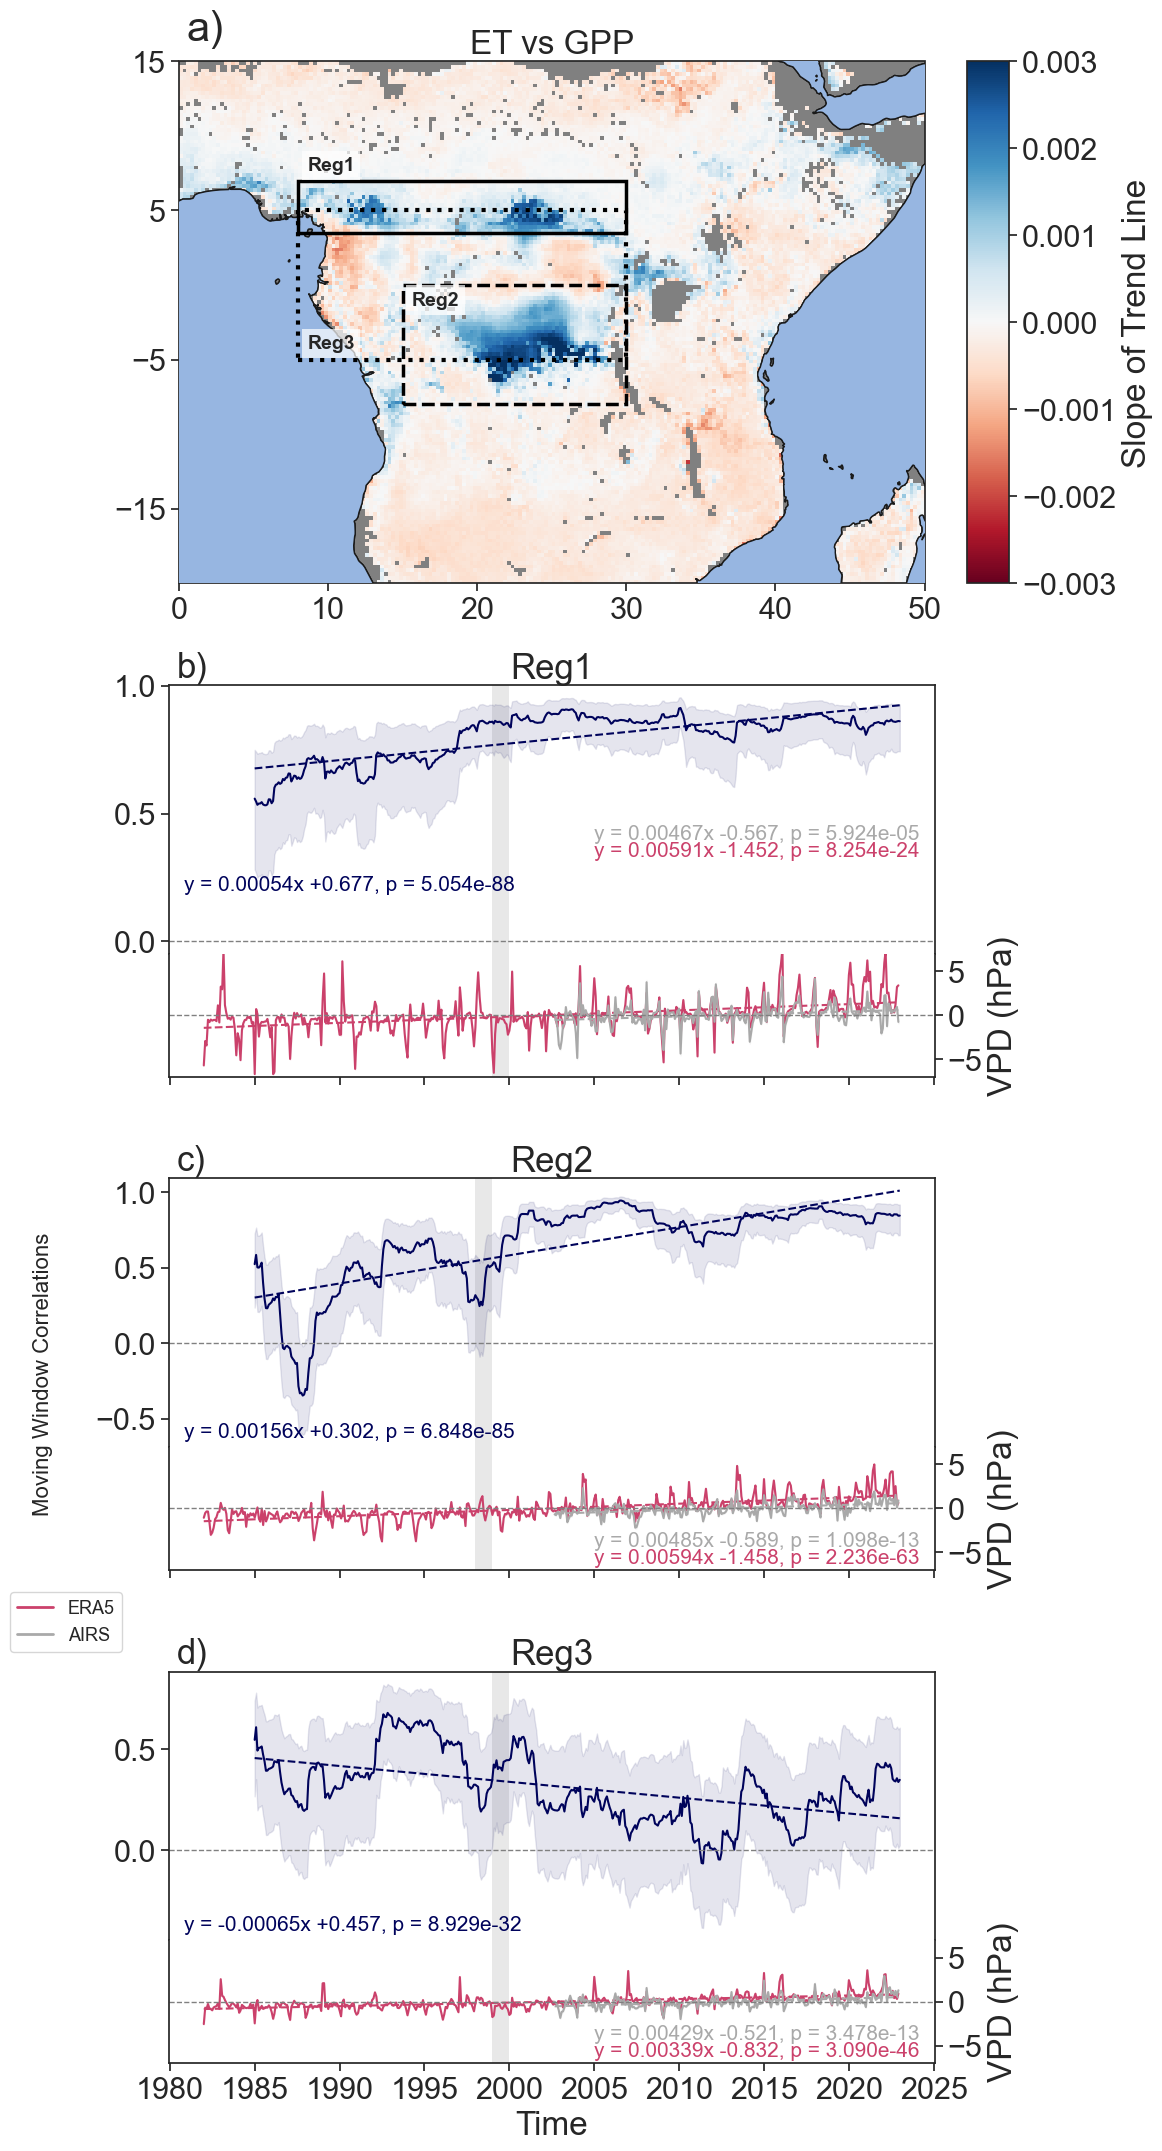

In [64]:
# Rolling correlation + trend
def CalcTrendLine(GPP_da, ET_da, window_size=36):
    gpp = to_1d_time(GPP_da)
    et = to_1d_time(ET_da)

    if gpp.sizes["time"] != et.sizes["time"]:
        raise ValueError("GPP and ET have different time lengths; they must be aligned already.")
    if not np.array_equal(gpp["time"].values, et["time"].values):
        raise ValueError("GPP and ET time coordinates differ; they must be aligned already.")

    x = gpp.values.astype(float)
    y = et.values.astype(float)
    N = x.shape[0]
    win = int(window_size)

    if N < win or win < 3:
        raise ValueError(f"window_size={win} invalid for series length N={N} (need N>=win and win>=3).")

    corr = np.full(N - win + 1, np.nan)
    rlow = np.full_like(corr, np.nan, dtype=float)
    rhigh = np.full_like(corr, np.nan, dtype=float)
    zcrit = norm.ppf(0.975)

    for i in range(N - win + 1):
        xi = x[i:i + win]
        yi = y[i:i + win]
        m = np.isfinite(xi) & np.isfinite(yi)
        n = int(m.sum())

        if n < 3:
            continue

        r = np.corrcoef(xi[m], yi[m])[0, 1]
        corr[i] = r

        if np.isfinite(r) and abs(r) < 1 and n > 3:
            z = np.arctanh(r)
            se = 1.0 / np.sqrt(n - 3)
            rlow[i] = np.tanh(z - zcrit * se)
            rhigh[i] = np.tanh(z + zcrit * se)

    valid = np.isfinite(corr)
    if valid.sum() >= 3:
        tnum = np.arange(corr.size)[valid]
        slope, intercept, _, p_val, _ = linregress(tnum, corr[valid])
    else:
        slope, intercept, p_val = np.nan, np.nan, np.nan

    return win, corr, rlow, rhigh, slope, intercept, p_val


# Deseasonalized VPD anomalies + SEM
def anomalies_with_sem(da: xr.DataArray):
    if "time" not in da.dims:
        raise ValueError("Input DataArray must have a 'time' dimension.")

    clim = da.groupby("time.month").mean("time", skipna=True)
    anom = da.groupby("time.month") - clim
    spatial_dims = [d for d in anom.dims if d != "time"]

    if spatial_dims:
        mean_anom = anom.mean(dim=spatial_dims, skipna=True)
        std = anom.std(dim=spatial_dims, skipna=True, ddof=1)
        n = anom.notnull().sum(dim=spatial_dims)
        sem = (std / np.sqrt(n.where(n > 0))).fillna(0)
    else:
        mean_anom = anom
        sem = xr.zeros_like(mean_anom)

    return mean_anom["time"].values, mean_anom.values, sem.values


# Shade full breakpoint year identified from annual JRC analysis
def add_breakpoint_span(ax, break_year):
    if break_year is None:
        return

    start = np.datetime64(f"{int(break_year)}-01-01")
    end = np.datetime64(f"{int(break_year) + 1}-01-01")
    ax.axvspan(start, end, color="grey", alpha=0.18, linewidth=0, zorder=0)


# Individual correlation + VPD panel
def plot_panel(ax_corr, ax_vpd, title,
               GPP_da, ET_da, VPD_E, VPD_A,
               corr_color="#00035b", era5_color="#cb416b", airs_color="darkgrey",
               window_size=36,
               draw_zero_corr=True, draw_zero_vpd=True,
               corr_text_y=0.02, vpd_ylim=(-7, 7),
               era_text_axis="vpd", era_text_mode="bottom",
               era_text_base_y=0.02, era_text_delta=0.14,
               above0_offset=0.25,
               break_year=None):

    win, corr, rlow, rhigh, slope, b, p = CalcTrendLine(
        GPP_da, ET_da, window_size=window_size
    )

    t_axis = GPP_da["time"].values[win - 1:]
    L = min(len(t_axis), len(corr))
    t_axis, corr, rlow, rhigh = t_axis[:L], corr[:L], rlow[:L], rhigh[:L]

    ax_corr.plot(t_axis, corr, color=corr_color, lw=1.5)
    ax_corr.fill_between(t_axis, rlow, rhigh, color=corr_color, alpha=0.10)

    tnum = np.arange(len(corr))
    ax_corr.plot(t_axis, slope * tnum + b, color=corr_color, linestyle="--")
    ax_corr.set_title(title, fontsize=25, pad=2)

    if draw_zero_corr:
        ax_corr.axhline(0, color="grey", linestyle="--", linewidth=1)

    add_breakpoint_span(ax_corr, break_year)

    ax_corr.spines["bottom"].set_visible(False)
    ax_corr.tick_params(axis="x", bottom=False, labelbottom=False)

    ax_corr.text(
        0.02, corr_text_y,
        f"y = {slope:.5f}x {b:+.3f}, p = {p:.3e}",
        transform=ax_corr.transAxes, fontsize=15, color=corr_color,
        ha="left", va="bottom"
    )

    # ERA5 VPD anomalies
    tE, meanE, seE = anomalies_with_sem(VPD_E)
    ax_vpd.plot(tE, meanE, color=era5_color, label="ERA5")
    ax_vpd.fill_between(tE, meanE - seE, meanE + seE, color=era5_color, alpha=0.10)

    tnE = np.arange(len(tE))
    sE, bE, _, pE, _ = linregress(tnE, meanE)
    ax_vpd.plot(tE, sE * tnE + bE, color=era5_color, linestyle="--")

    # AIRS VPD anomalies
    tA, meanA, seA = anomalies_with_sem(VPD_A)
    ax_vpd.plot(tA, meanA, color=airs_color, label="AIRS")
    ax_vpd.fill_between(tA, meanA - seA, meanA + seA, color=airs_color, alpha=0.10)

    tnA = np.arange(len(tA))
    sA, bA, _, pA, _ = linregress(tnA, meanA)
    ax_vpd.plot(tA, sA * tnA + bA, color=airs_color, linestyle="--")

    if draw_zero_vpd:
        ax_vpd.axhline(0, color="grey", linestyle="--", linewidth=1)

    add_breakpoint_span(ax_vpd, break_year)

    ax_vpd.set_ylabel("VPD (hPa)")
    ax_vpd.yaxis.set_label_position("right")
    ax_vpd.yaxis.tick_right()
    ax_vpd.spines["top"].set_visible(False)
    ax_vpd.set_ylim(vpd_ylim)

    # ERA5/AIRS trend text
    text_ax = ax_corr if era_text_axis == "corr" else ax_vpd

    if era_text_mode == "above0":
        y0, y1 = text_ax.get_ylim()
        y0_ax = (0 - y0) / (y1 - y0)
        yE = min(max(y0_ax + above0_offset, 0.05), 0.95)
        yA = min(max(yE + era_text_delta, 0.05), 0.95)
    else:
        yE = era_text_base_y
        yA = era_text_base_y + era_text_delta

    text_ax.text(
        0.98, yE,
        f"y = {sE:.5f}x {bE:+.3f}, p = {pE:.3e}",
        transform=text_ax.transAxes, fontsize=15, color=era5_color,
        ha="right", va="bottom"
    )

    text_ax.text(
        0.98, yA,
        f"y = {sA:.5f}x {bA:+.3f}, p = {pA:.3e}",
        transform=text_ax.transAxes, fontsize=15, color=airs_color,
        ha="right", va="bottom"
    )


# Combined figure
def make_4panel_one_column_aligned(
    out_png_path="/Users/sworden/Documents/EqAfricaGPPETResults/Map_RVPD_OneColumn_Aligned.png",
    era5_color="#cb416b", airs_color="darkgrey"):

    ERA_BASE_Y = 0.02
    ERA_DELTA_CD = 0.14

    fig = plt.figure(figsize=(12, 22))
    fig.subplots_adjust(left=0.22, right=0.92, top=0.97, bottom=0.06)

    outer = GridSpec(
        4, 2, figure=fig,
        width_ratios=[1.0, 0.055],
        height_ratios=[2.6, 1.95, 1.95, 1.95],
        hspace=0.24, wspace=0.08
    )

    # a) map
    ax_map = fig.add_subplot(outer[0, 0], projection=ccrs.PlateCarree())
    cax = fig.add_subplot(outer[0, 1])

    im = ax_map.pcolormesh(
        TrendArr.lon, TrendArr.lat, TrendArr,
        transform=ccrs.PlateCarree(),
        vmin=-0.003, vmax=0.003, cmap="RdBu"
    )

    ax_map.set_facecolor("grey")
    ax_map.coastlines()
    ax_map.set_xticks([0, 10, 20, 30, 40, 50], crs=ccrs.PlateCarree())
    ax_map.set_yticks([-15, -5, 5, 15], crs=ccrs.PlateCarree())
    ax_map.add_feature(cfeature.OCEAN, zorder=100, edgecolor="k")

    cb = fig.colorbar(im, cax=cax)
    cb.set_label("Slope of Trend Line")

    ax_map.text(.01, 1.04, "a)", fontsize=30, transform=ax_map.transAxes)
    ax_map.set_title("ET vs GPP")

    # Region boxes
    regions = {
        "Reg1": dict(lon0=8, lon1=30, lat0=3.5, lat1=7, ls="-", lw=2.5),
        "Reg2": dict(lon0=15, lon1=30, lat0=-8, lat1=0, ls="--", lw=2.5),
        "Reg3": dict(lon0=8, lon1=30, lat0=-5, lat1=5, ls=":", lw=3.0),
    }

    for name, r in regions.items():
        lon0, lon1 = r["lon0"], r["lon1"]
        lat0, lat1 = r["lat0"], r["lat1"]

        ax_map.add_patch(Rectangle(
            (lon0, lat0), lon1 - lon0, lat1 - lat0,
            fill=False, edgecolor="black",
            linewidth=r["lw"], linestyle=r["ls"],
            transform=ccrs.PlateCarree(), zorder=200
        ))

        if name == "Reg3":
            xlab, ylab, ha, va = lon0 + 0.6, lat0 + 0.45, "left", "bottom"
        elif name == "Reg1":
            xlab, ylab, ha, va = lon0 + 0.6, lat1 + 0.4, "left", "bottom"
        else:
            xlab, ylab, ha, va = lon0 + 0.6, lat1 - 0.4, "left", "top"

        ax_map.text(
            xlab, ylab, name,
            transform=ccrs.PlateCarree(),
            fontsize=14, fontweight="bold",
            ha=ha, va=va,
            bbox=dict(facecolor="white", alpha=0.7, edgecolor="none"),
            zorder=210
        )

    # b-d regional panels
    panel_info = [
        dict(
            title="Reg1", GPP=GPPR1, ET=ETR1, VPD_E=VPDER1, VPD_A=VPDAR1, lab="b)",
            draw_zero_corr=True, draw_zero_vpd=True,
            corr_text_y=0.22, era_text_axis="corr", era_text_mode="above0",
            above0_offset=0.30, break_year=BREAKPOINT_YEARS["Reg1"]
        ),
        dict(
            title="Reg2", GPP=GPPR2, ET=ETR2, VPD_E=VPDER2, VPD_A=VPDAR2, lab="c)",
            draw_zero_corr=True, draw_zero_vpd=True,
            corr_text_y=0.02, era_text_axis="vpd", era_text_mode="bottom",
            break_year=BREAKPOINT_YEARS["Reg2"]
        ),
        dict(
            title="Reg3", GPP=GPPR3, ET=ETR3, VPD_E=VPDER3, VPD_A=VPDAR3, lab="d)",
            draw_zero_corr=True, draw_zero_vpd=True,
            corr_text_y=0.02, era_text_axis="vpd", era_text_mode="bottom",
            break_year=BREAKPOINT_YEARS["Reg3"]
        ),
    ]

    first_corr = None
    bottom_axes_corr = []
    bottom_axes_vpd = []

    for row, info in enumerate(panel_info, start=1):
        sub = outer[row, 0].subgridspec(
            2, 1, height_ratios=[2.4, 1.1], hspace=0.0
        )

        ax_corr = fig.add_subplot(
            sub[0], sharex=first_corr if first_corr is not None else None
        )

        if first_corr is None:
            first_corr = ax_corr

        ax_vpd = fig.add_subplot(sub[1], sharex=first_corr)

        corr_h = ax_corr.get_position().height
        vpd_h = ax_vpd.get_position().height
        delta_b = ERA_DELTA_CD * (vpd_h / corr_h)

        if info.get("era_text_axis", "vpd") == "corr":
            era_delta_use = delta_b
        else:
            era_delta_use = ERA_DELTA_CD

        plot_panel(
            ax_corr, ax_vpd, info["title"],
            info["GPP"], info["ET"], info["VPD_E"], info["VPD_A"],
            window_size=36,
            draw_zero_corr=info.get("draw_zero_corr", True),
            draw_zero_vpd=info.get("draw_zero_vpd", True),
            corr_text_y=info.get("corr_text_y", 0.02),
            era_text_axis=info.get("era_text_axis", "vpd"),
            era_text_mode=info.get("era_text_mode", "bottom"),
            era_text_base_y=ERA_BASE_Y,
            era_text_delta=era_delta_use,
            above0_offset=info.get("above0_offset", 0.25),
            era5_color=era5_color,
            airs_color=airs_color,
            break_year=info.get("break_year", None)
        )

        ax_corr.set_ylabel("")

        leg = ax_vpd.get_legend()
        if leg is not None:
            leg.remove()

        ax_corr.text(.01, 1.03, info["lab"], fontsize=25, transform=ax_corr.transAxes)

        bottom_axes_corr.append(ax_corr)
        bottom_axes_vpd.append(ax_vpd)

        if row < 3:
            ax_vpd.set_xlabel("")
            ax_vpd.tick_params(axis="x", labelbottom=False)
        else:
            ax_vpd.set_xlabel("Time")

        ax_blank = fig.add_subplot(outer[row, 1])
        ax_blank.axis("off")

    # Shared ylabel + legend
    fig.canvas.draw()

    left = min(ax.get_position().x0 for ax in bottom_axes_corr + bottom_axes_vpd)
    top = max(ax.get_position().y1 for ax in bottom_axes_corr)
    bottom = min(ax.get_position().y0 for ax in bottom_axes_vpd)
    center_y = 0.5 * (top + bottom)
    height = top - bottom
    ylab_x = left - 0.105

    fig.text(
        ylab_x, center_y, "Moving Window Correlations",
        rotation=90, ha="center", va="center", fontsize=16
    )

    handles = [
        Line2D([0], [0], color=era5_color, lw=2),
        Line2D([0], [0], color=airs_color, lw=2),
    ]
    labels = ["ERA5", "AIRS"]

    leg_x = ylab_x - 0.035
    leg_y = center_y - 0.18 * height

    fig.legend(
        handles, labels,
        loc="center left",
        bbox_to_anchor=(leg_x, leg_y),
        frameon=True, fontsize=13
    )

    plt.savefig(out_png_path, dpi=300, bbox_inches="tight")
    plt.show()


# Run
print("Figure 3 breakpoint years:", BREAKPOINT_YEARS)

make_4panel_one_column_aligned(
    "/Users/sworden/Documents/EqAfricaGPPETResults/Figure3_9.9.png"
)

## Figures 4-6

Breakpoints used in Figures 4–6: {'Reg1': 1999, 'Reg2': 1998, 'Reg3': 1999}


C:\Users\sworden\AppData\Local\Temp\ipykernel_51048\3400520890.py:172: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0,0,0.90,1])


Saved region 4-class triptych → /Users/sworden/Documents/EqAfricaGPPETResults\region_triptych_Reg1Reg2Reg3_bucket4.png


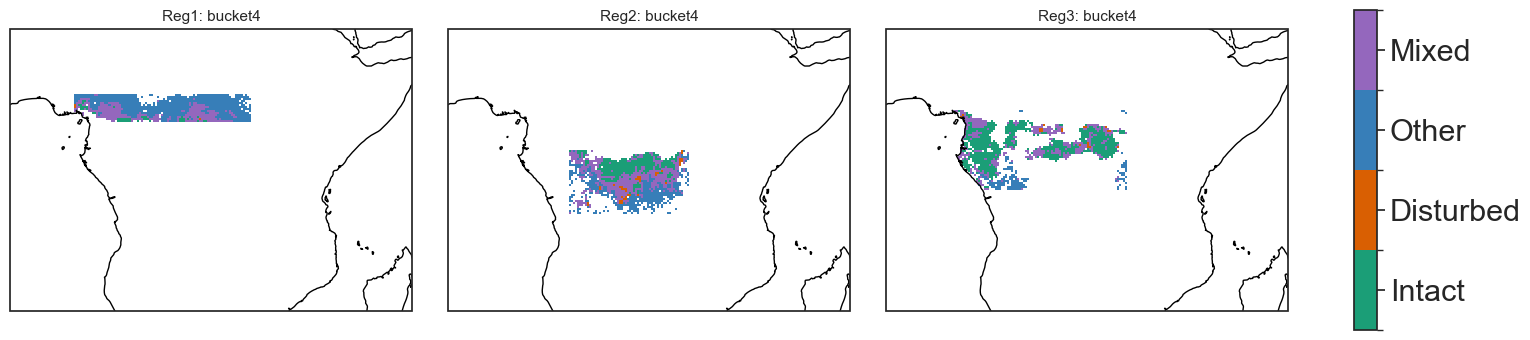

[Reg1]    Intact pixels =      49 (skipped, N<50)
[Reg1] Disturbed pixels =       3 (skipped, N<50)
[Reg1]     Other pixels =     697 
[Reg1]     Mixed pixels =     301 

Reg1 Other GPP | slope=0.00078123 per month | intercept=6.630648 | p=0.19756847 | r=0.058189 | R2=0.003386 | SE=0.00060549 | N=492
Reg1 Other ET | slope=-0.00792400 per month | intercept=94.647330 | p=0.17333358 | r=-0.061483 | R2=0.003780 | SE=0.00581128 | N=492
Reg1 Other r(GPP,ET) | slope=0.00030042 per month | intercept=0.775301 | p=2.0347037e-69 | r=0.703253 | R2=0.494565 | SE=0.00001424 | N=457
Reg1 Other VPD | slope=0.00609509 per month | intercept=-1.496346 | p=4.0149609e-23 | r=0.426110 | R2=0.181570 | SE=0.00058459 | N=492
Reg1 Mixed GPP | slope=0.00022589 per month | intercept=7.818285 | p=0.41286258 | r=0.036999 | R2=0.001369 | SE=0.00027563 | N=492
Reg1 Mixed ET | slope=-0.01027724 per month | intercept=110.337390 | p=0.009244314 | r=-0.117240 | R2=0.013745 | SE=0.00393275 | N=492
Reg1 Mixed r(GPP,ET) | s

C:\Users\sworden\AppData\Local\Temp\ipykernel_51048\3400520890.py:343: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved dashboard → /Users/sworden/Documents/EqAfricaGPPETResults\dashboard_Reg1_Nmin50_Figure3TrendMethod.png


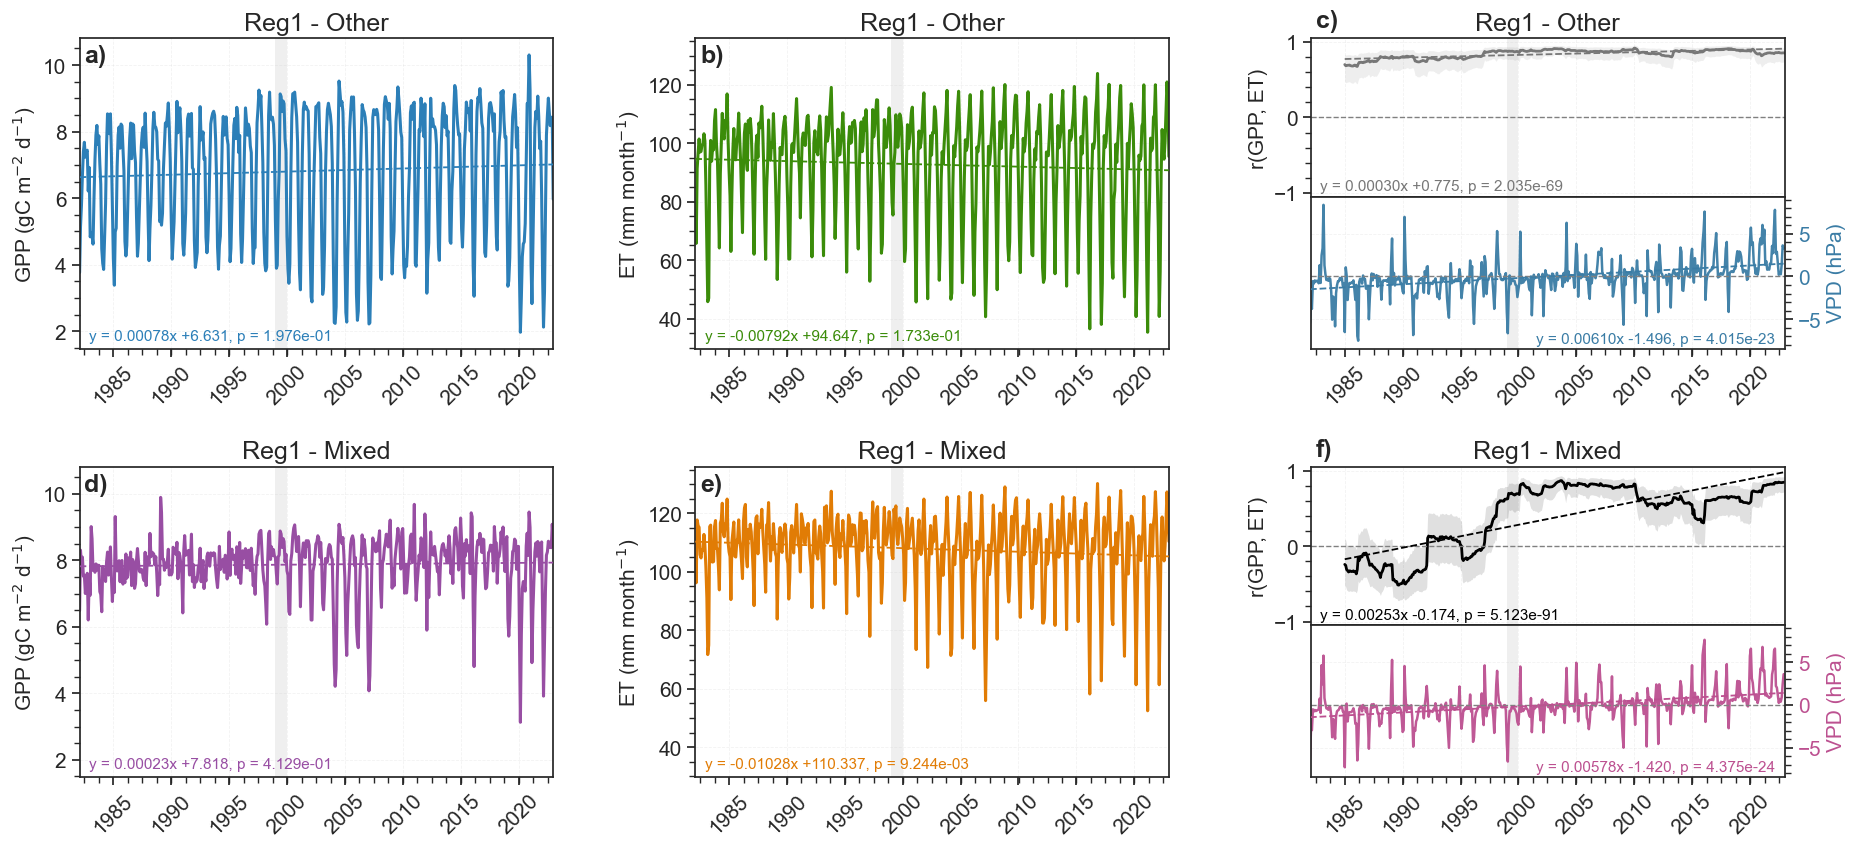

[Reg1]    Intact — skipped (N=49 < 50)
[Reg1] Disturbed — skipped (N=3 < 50)


C:\Users\sworden\AppData\Local\anaconda3\envs\ProcessData\Lib\site-packages\dask\array\numpy_compat.py:53: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
C:\Users\sworden\AppData\Local\anaconda3\envs\ProcessData\Lib\site-packages\dask\core.py:127: RuntimeWarning: invalid value encountered in divide
  return func(*(_execute_task(a, cache) for a in args))


[Reg1]     Other | pixels=    697 | r_grid mean±std=0.737 ± 0.101


C:\Users\sworden\AppData\Local\anaconda3\envs\ProcessData\Lib\site-packages\dask\array\numpy_compat.py:53: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
C:\Users\sworden\AppData\Local\anaconda3\envs\ProcessData\Lib\site-packages\dask\core.py:127: RuntimeWarning: invalid value encountered in divide
  return func(*(_execute_task(a, cache) for a in args))


[Reg1]     Mixed | pixels=    301 | r_grid mean±std=0.403 ± 0.203

[Reg2]    Intact pixels =     313 
[Reg2] Disturbed pixels =      41 (skipped, N<50)
[Reg2]     Other pixels =     415 
[Reg2]     Mixed pixels =     482 

Reg2 Intact GPP | slope=-0.00094320 per month | intercept=8.344564 | p=1.412449e-06 | r=-0.215438 | R2=0.046413 | SE=0.00019314 | N=492
Reg2 Intact ET | slope=-0.00491884 per month | intercept=120.786663 | p=0.12816154 | r=-0.068683 | R2=0.004717 | SE=0.00322765 | N=492
Reg2 Intact r(GPP,ET) | slope=0.00179231 per month | intercept=-0.104358 | p=8.6940403e-75 | r=0.721973 | R2=0.521244 | SE=0.00008053 | N=457
Reg2 Intact VPD | slope=0.00573121 per month | intercept=-1.407012 | p=2.5641875e-64 | r=0.665809 | R2=0.443302 | SE=0.00029014 | N=492
Reg2 Other GPP | slope=-0.00176233 per month | intercept=6.764333 | p=1.3473501e-06 | r=-0.215848 | R2=0.046590 | SE=0.00036015 | N=492
Reg2 Other ET | slope=-0.01017391 per month | intercept=96.093397 | p=0.0643981 | r=-0.08344

C:\Users\sworden\AppData\Local\Temp\ipykernel_51048\3400520890.py:343: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved dashboard → /Users/sworden/Documents/EqAfricaGPPETResults\dashboard_Reg2_Nmin50_Figure3TrendMethod.png


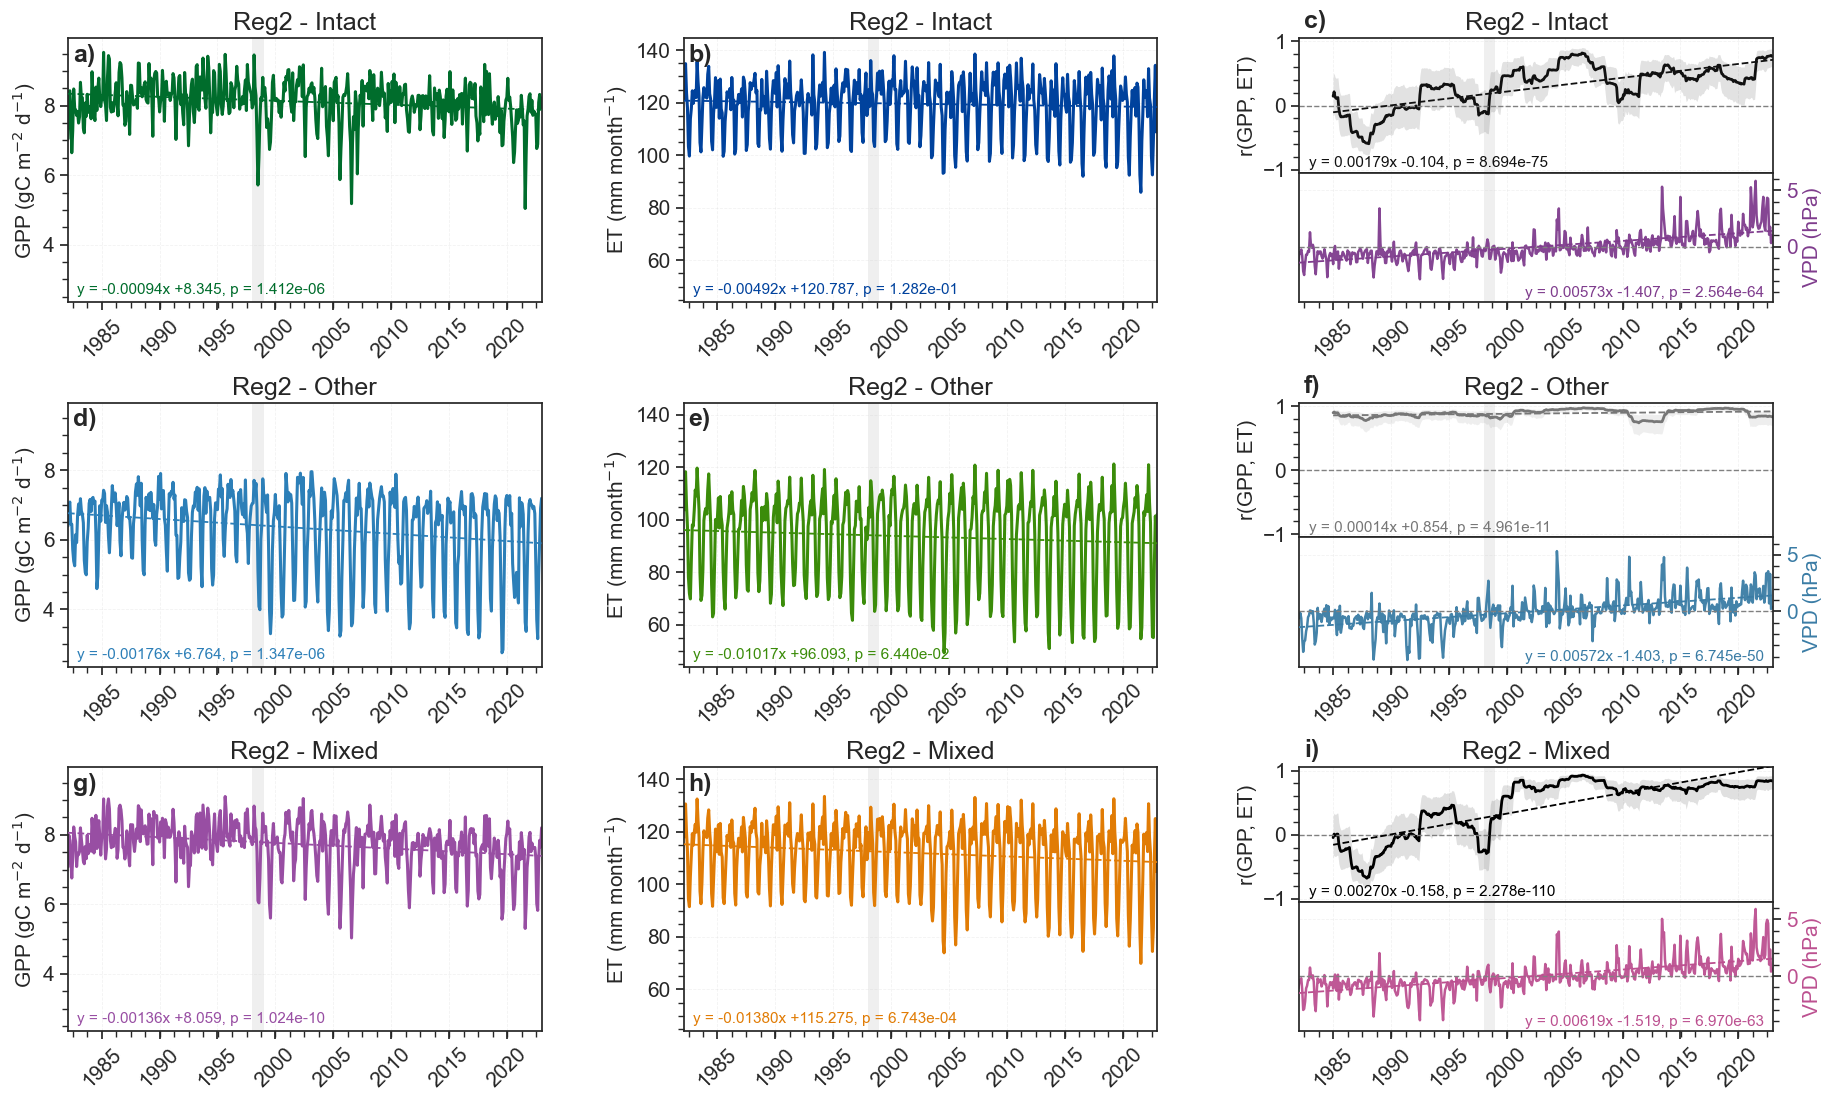

C:\Users\sworden\AppData\Local\anaconda3\envs\ProcessData\Lib\site-packages\dask\array\numpy_compat.py:53: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
C:\Users\sworden\AppData\Local\anaconda3\envs\ProcessData\Lib\site-packages\dask\core.py:127: RuntimeWarning: invalid value encountered in divide
  return func(*(_execute_task(a, cache) for a in args))


[Reg2]    Intact | pixels=    313 | r_grid mean±std=0.251 ± 0.216
[Reg2] Disturbed — skipped (N=41 < 50)


C:\Users\sworden\AppData\Local\anaconda3\envs\ProcessData\Lib\site-packages\dask\array\numpy_compat.py:53: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
C:\Users\sworden\AppData\Local\anaconda3\envs\ProcessData\Lib\site-packages\dask\core.py:127: RuntimeWarning: invalid value encountered in divide
  return func(*(_execute_task(a, cache) for a in args))


[Reg2]     Other | pixels=    415 | r_grid mean±std=0.690 ± 0.181


C:\Users\sworden\AppData\Local\anaconda3\envs\ProcessData\Lib\site-packages\dask\array\numpy_compat.py:53: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
C:\Users\sworden\AppData\Local\anaconda3\envs\ProcessData\Lib\site-packages\dask\core.py:127: RuntimeWarning: invalid value encountered in divide
  return func(*(_execute_task(a, cache) for a in args))


[Reg2]     Mixed | pixels=    482 | r_grid mean±std=0.350 ± 0.334

[Reg3]    Intact pixels =     672 
[Reg3] Disturbed pixels =      20 (skipped, N<50)
[Reg3]     Other pixels =     150 
[Reg3]     Mixed pixels =     398 

Reg3 Intact GPP | slope=-0.00036100 per month | intercept=7.879670 | p=0.016906736 | r=-0.107653 | R2=0.011589 | SE=0.00015061 | N=492
Reg3 Intact ET | slope=0.00122814 per month | intercept=119.308380 | p=0.70354159 | r=0.017199 | R2=0.000296 | SE=0.00322545 | N=492
Reg3 Intact r(GPP,ET) | slope=-0.00050910 per month | intercept=0.293355 | p=9.054719e-15 | r=-0.351917 | R2=0.123846 | SE=0.00006348 | N=457
Reg3 Intact VPD | slope=0.00341072 per month | intercept=-0.837331 | p=4.2440161e-42 | r=0.560803 | R2=0.314500 | SE=0.00022748 | N=492
Reg3 Other GPP | slope=-0.00060835 per month | intercept=6.127316 | p=0.04473861 | r=-0.090532 | R2=0.008196 | SE=0.00030232 | N=492
Reg3 Other ET | slope=0.00158353 per month | intercept=91.871597 | p=0.73704997 | r=0.015175 | R2=

C:\Users\sworden\AppData\Local\Temp\ipykernel_51048\3400520890.py:343: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved dashboard → /Users/sworden/Documents/EqAfricaGPPETResults\dashboard_Reg3_Nmin50_Figure3TrendMethod.png


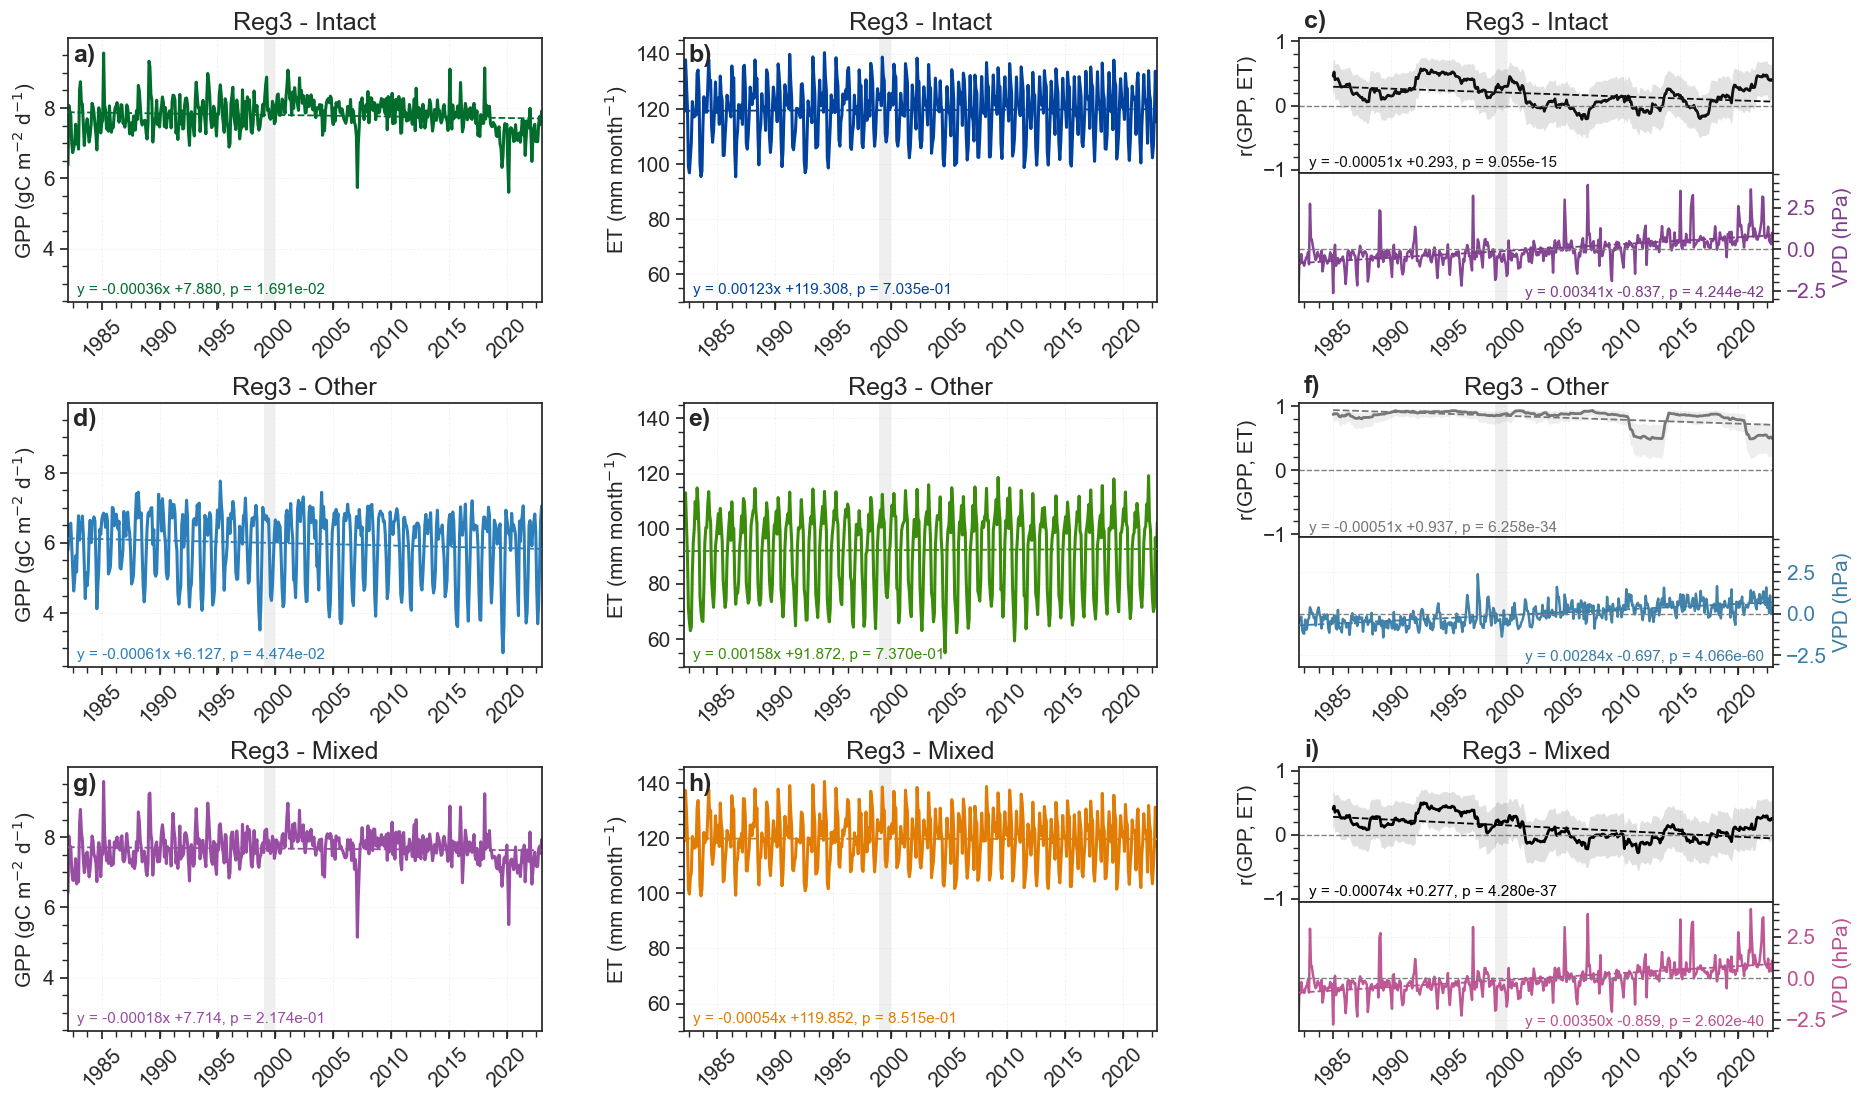

C:\Users\sworden\AppData\Local\anaconda3\envs\ProcessData\Lib\site-packages\dask\array\numpy_compat.py:53: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
C:\Users\sworden\AppData\Local\anaconda3\envs\ProcessData\Lib\site-packages\dask\core.py:127: RuntimeWarning: invalid value encountered in divide
  return func(*(_execute_task(a, cache) for a in args))


[Reg3]    Intact | pixels=    672 | r_grid mean±std=0.140 ± 0.158
[Reg3] Disturbed — skipped (N=20 < 50)


C:\Users\sworden\AppData\Local\anaconda3\envs\ProcessData\Lib\site-packages\dask\array\numpy_compat.py:53: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
C:\Users\sworden\AppData\Local\anaconda3\envs\ProcessData\Lib\site-packages\dask\core.py:127: RuntimeWarning: invalid value encountered in divide
  return func(*(_execute_task(a, cache) for a in args))


[Reg3]     Other | pixels=    150 | r_grid mean±std=0.639 ± 0.207
[Reg3]     Mixed | pixels=    398 | r_grid mean±std=0.096 ± 0.222

Saved summary log → /Users/sworden/Documents/EqAfricaGPPETResults\summary_pixel_stats_Reg1Reg2Reg3_Nmin50_Figure3TrendMethod.txt


C:\Users\sworden\AppData\Local\anaconda3\envs\ProcessData\Lib\site-packages\dask\array\numpy_compat.py:53: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
C:\Users\sworden\AppData\Local\anaconda3\envs\ProcessData\Lib\site-packages\dask\core.py:127: RuntimeWarning: invalid value encountered in divide
  return func(*(_execute_task(a, cache) for a in args))


In [69]:
import os, re, io, string
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

from scipy.stats import linregress
from matplotlib.gridspec import GridSpec
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.dates import YearLocator, DateFormatter

# SETTINGS
gpp_c = {"Intact":"#006d2c", "Disturbed":"#1b9e77", "Other":"#2c7fb8", "Mixed":"#984ea3"}
et_c = {"Intact":"#00429d", "Disturbed":"#73a2ff", "Other":"#3b8c0a", "Mixed":"#e17c05"}
vpd_c = {"Intact":"#7f3c8d", "Disturbed":"#e76f51", "Other":"#3a7ca5", "Mixed":"#bc5090"}
r_c = {"Intact":"#111111", "Disturbed":"#444444", "Other":"#777777", "Mixed":"#000000"}

OUTPUT_DIR = "/Users/sworden/Documents/EqAfricaGPPETResults"
DPI = 300
PIXEL_MIN = 50
os.makedirs(OUTPUT_DIR, exist_ok=True)

if "BREAKPOINT_YEARS" not in globals():
    raise RuntimeError("Run the JRC CUSUM breakpoint-analysis cell first.")

# Force identical x-axis limits on every panel
COMMON_XLIM = (GPPNew["time"].values[0], GPPNew["time"].values[-1])

def add_breakpoint_span(ax, region_name, color="0.7", alpha=0.20):
    year = BREAKPOINT_YEARS.get(region_name)
    if year is None: return
    ax.axvspan(np.datetime64(f"{int(year)}-01-01"), np.datetime64(f"{int(year)+1}-01-01"),
               color=color, alpha=alpha, linewidth=0, zorder=0)

def rolling_corr(x, y, window=36):
    xv, yv = np.asarray(x.values,float), np.asarray(y.values,float)
    n = xv.size
    if n < window:
        t = x["time"][0:0]
        z = np.array([])
        return t, z, z, z

    r = np.full(n-window+1, np.nan)
    t = x["time"][window-1:]

    for i in range(window, n+1):
        xs, ys = xv[i-window:i], yv[i-window:i]
        m = np.isfinite(xs) & np.isfinite(ys)
        if m.sum() >= max(3,window//2) and xs[m].std() > 0 and ys[m].std() > 0:
            r[i-window] = np.corrcoef(xs[m],ys[m])[0,1]

    lo, hi = np.full_like(r,np.nan), np.full_like(r,np.nan)
    finite = np.isfinite(r)

    if finite.any():
        z = np.arctanh(np.clip(r[finite],-0.999999,0.999999))
        se = 1.0/np.sqrt(max(window-3,1))
        lo[finite] = np.tanh(z-1.96*se)
        hi[finite] = np.tanh(z+1.96*se)

    return t, r, lo, hi

def _shared_ylim(series_list):
    vals = []
    for s in series_list:
        v = np.asarray(s.values,float)
        v = v[np.isfinite(v)]
        if v.size: vals.append(v)

    if not vals: return None

    vv = np.concatenate(vals)
    lo, hi = float(np.nanmin(vv)), float(np.nanmax(vv))
    pad = 0.06*(hi-lo if hi > lo else (abs(hi) if hi != 0 else 1.0))
    return lo-pad, hi+pad

def _safe(name):
    return re.sub(r"[^A-Za-z0-9._-]+","_",name)

def area_mean_ts(da, mask2d):
    return da.where(mask2d).mean(dim=("lat","lon"))

def add_fig3_trend(ax, time, values, color, text_xy=(0.02,0.02),
                   ha="left", va="bottom", fontsize=11, log_prefix=None):
    values = np.asarray(values,float)
    tvals = np.asarray(time.values)
    finite = np.isfinite(values)

    if finite.sum() < 3: return None

    x = np.arange(values.size,dtype=float)[finite]
    y, t = values[finite], tvals[finite]

    lr = linregress(x,y)
    trend = lr.slope*x + lr.intercept

    ax.plot(t,trend,ls="--",lw=1.3,color=color,zorder=5)

    txt = f"y = {lr.slope:.5f}x {lr.intercept:+.3f}, p = {lr.pvalue:.3e}"
    ax.text(text_xy[0],text_xy[1],txt,transform=ax.transAxes,
            fontsize=fontsize,color=color,ha=ha,va=va)

    if log_prefix is not None:
        line = (f"{log_prefix} | slope={lr.slope:.8f} per month | "
                f"intercept={lr.intercept:.6f} | p={lr.pvalue:.8g} | "
                f"r={lr.rvalue:.6f} | R2={lr.rvalue**2:.6f} | "
                f"SE={lr.stderr:.8f} | N={finite.sum()}")
        print(line)
        logbuf.write(line+"\n")

    return lr

# STATIC FIELDS / VEGETATION MASKS
AET2d = AET.isel(time=0,drop=True) if "time" in AET.dims else AET
bucket4 = JRC_static

mask_intact = (bucket4 == 0).fillna(False)
mask_disturb = (bucket4 == 1).fillna(False)
mask_other = (bucket4 == 2).fillna(False)
mask_mixed = (bucket4 == 3).fillna(False)

row_order = ["Intact","Disturbed","Other","Mixed"]

year_loc = YearLocator(base=5)
year_fmt = DateFormatter("%Y")

def apply_time_axis(ax, tick_size=15):
    ax.xaxis.set_major_locator(year_loc)
    ax.xaxis.set_major_formatter(year_fmt)
    ax.tick_params(axis="x",labelrotation=45,labelsize=tick_size)

letters = list(string.ascii_lowercase)

# REGION MASKS
Trendg = TrendArr
if isinstance(Trendg,xr.DataArray) and "time" in Trendg.dims:
    Trendg = Trendg.isel(time=0,drop=True)

lat, lon = AET2d["lat"], AET2d["lon"]

Reg1_mask = ((lat>=3.5)&(lat<=7.0)&(lon>=8.0)&(lon<=30.0)&(Trendg>0)).fillna(False)
Reg2_mask = ((lat>=-8.0)&(lat<=0.0)&(lon>=15.0)&(lon<=30.0)&(Trendg>0)).fillna(False)
Reg3_mask = ((lat>=-5.0)&(lat<=5.0)&(lon>=8.0)&(lon<=30.0)&(Trendg<=0)).fillna(False)

region_masks = {"Reg1":Reg1_mask,"Reg2":Reg2_mask,"Reg3":Reg3_mask}

print("Breakpoints used in Figures 4–6:", BREAKPOINT_YEARS)

# OPTIONAL REGION MAP
do_maps = True

if do_maps:
    cmap4 = ListedColormap(["#1b9e77","#d95f02","#377eb8","#9467bd"])
    norm4 = BoundaryNorm([-0.5,0.5,1.5,2.5,3.5],4)

    fig_map, axes = plt.subplots(1,3,figsize=(15,5),
                                 subplot_kw=dict(projection=ccrs.PlateCarree()))

    pm = None
    for ax,(rname,rmask) in zip(axes,region_masks.items()):
        ax.set_title(f"{rname}: bucket4",fontsize=11)
        ax.coastlines()

        bsub = bucket4.where(rmask)
        pm = ax.pcolormesh(AET2d.lon,AET2d.lat,bsub,cmap=cmap4,norm=norm4,
                           transform=ccrs.PlateCarree())

    cax = fig_map.add_axes([0.92,0.18,0.015,0.64])
    cb = plt.colorbar(pm,cax=cax,ticks=[0,1,2,3])
    cb.ax.set_yticklabels(["Intact","Disturbed","Other","Mixed"])

    plt.tight_layout(rect=[0,0,0.90,1])

    f_map = os.path.join(OUTPUT_DIR,"region_triptych_Reg1Reg2Reg3_bucket4.png")
    fig_map.savefig(f_map,dpi=DPI,bbox_inches="tight")
    print(f"Saved region 4-class triptych → {f_map}")

    plt.show()
    plt.close(fig_map)

# STATIC CORRELATION MAP
r_grid = xr.corr(GPPNew,AET,dim="time")

# MAIN LOOP
logbuf = io.StringIO()

for region_name,rmask0 in region_masks.items():
    rmask = rmask0.astype(bool)

    m = {
        "Intact": mask_intact & rmask,
        "Disturbed": mask_disturb & rmask,
        "Other": mask_other & rmask,
        "Mixed": mask_mixed & rmask
    }

    pix = {k:int(m[k].sum().item()) for k in row_order}
    eligible = [k for k in row_order if pix[k] >= PIXEL_MIN]

    for k in row_order:
        note = "" if k in eligible else f"(skipped, N<{PIXEL_MIN})"
        line = f"[{region_name:>4}] {k:>9} pixels = {pix[k]:7d} {note}"
        print(line)
        logbuf.write(line+"\n")

    print()
    logbuf.write("\n")

    if not eligible:
        msg = f"No classes meet PIXEL_MIN={PIXEL_MIN} in {region_name}; skipping."
        print(msg)
        logbuf.write(msg+"\n\n")
        continue

    gpp = {k:area_mean_ts(GPPNew,m[k]) for k in eligible}
    et = {k:area_mean_ts(AET,m[k]) for k in eligible}
    vpd = {k:area_mean_ts(VPDArr,m[k]) for k in eligible}

    vpd_anom = {}
    for k in eligible:
        clim = vpd[k].groupby("time.month").mean("time")
        vpd_anom[k] = vpd[k].groupby("time.month")-clim

    rc = {k:rolling_corr(gpp[k],et[k],window=36) for k in eligible}

    gpp_ylim = _shared_ylim(list(gpp.values()))
    et_ylim = _shared_ylim(list(et.values()))
    vpd_ylim = _shared_ylim(list(vpd_anom.values()))

    nrows = len(eligible)
    fig = plt.figure(figsize=(22,3.3*nrows+3))
    gs = GridSpec(nrows,3,figure=fig,hspace=0.38,wspace=0.30)

    def draw_row(row_idx,klass):
        ax_g = fig.add_subplot(gs[row_idx,0])
        ax_e = fig.add_subplot(gs[row_idx,1])
        ax_p = fig.add_subplot(gs[row_idx,2])

        row_title = f"{region_name} - {klass}"
        base_idx = row_idx*3

        if base_idx < len(letters):
            ax_g.text(0.01,0.98,f"{letters[base_idx]})",transform=ax_g.transAxes,
                      ha="left",va="top",fontsize=18,fontweight="bold")

        if base_idx+1 < len(letters):
            ax_e.text(0.01,0.98,f"{letters[base_idx+1]})",transform=ax_e.transAxes,
                      ha="left",va="top",fontsize=18,fontweight="bold")

        if base_idx+2 < len(letters):
            ax_p.text(0.01,1.02,f"{letters[base_idx+2]})",transform=ax_p.transAxes,
                      ha="left",va="bottom",fontsize=18,fontweight="bold")

        # GPP
        s = gpp[klass]
        ax_g.plot(s["time"],s,lw=2.2,color=gpp_c[klass])
        add_fig3_trend(ax_g,s["time"],s.values,gpp_c[klass],
                       text_xy=(0.02,0.02),log_prefix=f"{region_name} {klass} GPP")
        add_breakpoint_span(ax_g,region_name)

        ax_g.set_xlim(COMMON_XLIM)
        ax_g.set_title(row_title,fontsize=18)
        ax_g.set_ylabel("GPP (gC m$^{-2}$ d$^{-1}$)",fontsize=15)
        if gpp_ylim: ax_g.set_ylim(*gpp_ylim)
        ax_g.grid(alpha=0.25,ls="--",lw=0.6)
        apply_time_axis(ax_g,15)
        ax_g.tick_params(axis="y",labelsize=15)
        ax_g.minorticks_on()

        # ET
        s = et[klass]
        ax_e.plot(s["time"],s,lw=2.2,color=et_c[klass])
        add_fig3_trend(ax_e,s["time"],s.values,et_c[klass],
                       text_xy=(0.02,0.02),log_prefix=f"{region_name} {klass} ET")
        add_breakpoint_span(ax_e,region_name)

        ax_e.set_xlim(COMMON_XLIM)
        ax_e.set_title(row_title,fontsize=18)
        ax_e.set_ylabel("ET (mm month$^{-1}$)",fontsize=15)
        if et_ylim: ax_e.set_ylim(*et_ylim)
        ax_e.grid(alpha=0.25,ls="--",lw=0.6)
        apply_time_axis(ax_e,15)
        ax_e.tick_params(axis="y",labelsize=15)
        ax_e.minorticks_on()

        # r(GPP, ET) + VPD
        ax_p.set_frame_on(False)
        ax_p.set_xticks([])
        ax_p.set_yticks([])

        t_r,rvals,lo,hi = rc[klass]

        # Top: rolling correlation
        ax_top = ax_p.inset_axes([0.0,0.49,1.0,0.51])

        if rvals.size and np.isfinite(rvals).any():
            ax_top.plot(t_r,rvals,lw=2.0,color=r_c[klass])
            ax_top.fill_between(t_r.values,lo,hi,alpha=0.12,lw=0,color=r_c[klass])
            add_fig3_trend(ax_top,t_r,rvals,r_c[klass],
                           text_xy=(0.02,0.02),
                           log_prefix=f"{region_name} {klass} r(GPP,ET)")
        else:
            ax_top.text(0.5,0.6,"no data",ha="center",va="center",
                        transform=ax_top.transAxes)

        add_breakpoint_span(ax_top,region_name)

        ax_top.set_xlim(COMMON_XLIM)
        ax_top.axhline(0,color="grey",lw=1.0,ls="--")
        ax_top.set_ylim(-1.05,1.05)
        ax_top.set_title(row_title,fontsize=18)
        ax_top.set_ylabel("r(GPP, ET)",fontsize=15)
        ax_top.grid(alpha=0.25,ls="--",lw=0.6)
        apply_time_axis(ax_top,15)
        ax_top.tick_params(axis="y",labelsize=15)
        ax_top.minorticks_on()

        # Bottom: VPD anomalies
        ax_bot = ax_p.inset_axes([0.0,0.00,1.0,0.49])

        sv = vpd_anom[klass]
        ax_bot.plot(sv["time"],sv,lw=1.8,alpha=0.95,color=vpd_c[klass])
        add_fig3_trend(ax_bot,sv["time"],sv.values,vpd_c[klass],
                       text_xy=(0.98,0.02),ha="right",
                       log_prefix=f"{region_name} {klass} VPD")
        add_breakpoint_span(ax_bot,region_name)

        ax_bot.set_xlim(COMMON_XLIM)
        ax_bot.axhline(0,color="grey",lw=1.0,ls="--")
        if vpd_ylim: ax_bot.set_ylim(*vpd_ylim)

        ax_bot.set_ylabel("VPD (hPa)",color=vpd_c[klass],fontsize=15)
        ax_bot.yaxis.set_label_position("right")
        ax_bot.yaxis.tick_right()
        ax_bot.tick_params(axis="y",labelcolor=vpd_c[klass],labelsize=15)
        ax_bot.grid(alpha=0.25,ls="--",lw=0.6)
        apply_time_axis(ax_bot,15)
        ax_bot.minorticks_on()

    for i,klass in enumerate(eligible):
        draw_row(i,klass)

    plt.tight_layout()

    f_dash = os.path.join(
        OUTPUT_DIR,
        f"dashboard_{_safe(region_name)}_Nmin{PIXEL_MIN}_Figure3TrendMethod.png"
    )

    fig.savefig(f_dash,dpi=DPI,bbox_inches="tight")
    print(f"Saved dashboard → {f_dash}")
    plt.show()
    plt.close(fig)

    # Static correlation statistics
    for klass in row_order:
        if pix[klass] < PIXEL_MIN:
            line = f"[{region_name:>4}] {klass:>9} — skipped (N={pix[klass]} < {PIXEL_MIN})"
            print(line)
            logbuf.write(line+"\n")
            continue

        rr = r_grid.where(m[klass]).values
        rr = rr[np.isfinite(rr)]

        mean_r = float(np.mean(rr)) if rr.size else np.nan
        std_r = float(np.std(rr,ddof=1)) if rr.size > 1 else np.nan

        line = (f"[{region_name:>4}] {klass:>9} | pixels={pix[klass]:7d} | "
                f"r_grid mean±std={mean_r:.3f} ± {std_r:.3f}")

        print(line)
        logbuf.write(line+"\n")

    print()
    logbuf.write("\n")

# SAVE LOG
log_path = os.path.join(
    OUTPUT_DIR,
    f"summary_pixel_stats_Reg1Reg2Reg3_Nmin{PIXEL_MIN}_Figure3TrendMethod.txt"
)

with open(log_path,"w") as f:
    f.write(logbuf.getvalue())

print(f"Saved summary log → {log_path}")

## Supplementary Figures

### Supplementary Figure 5

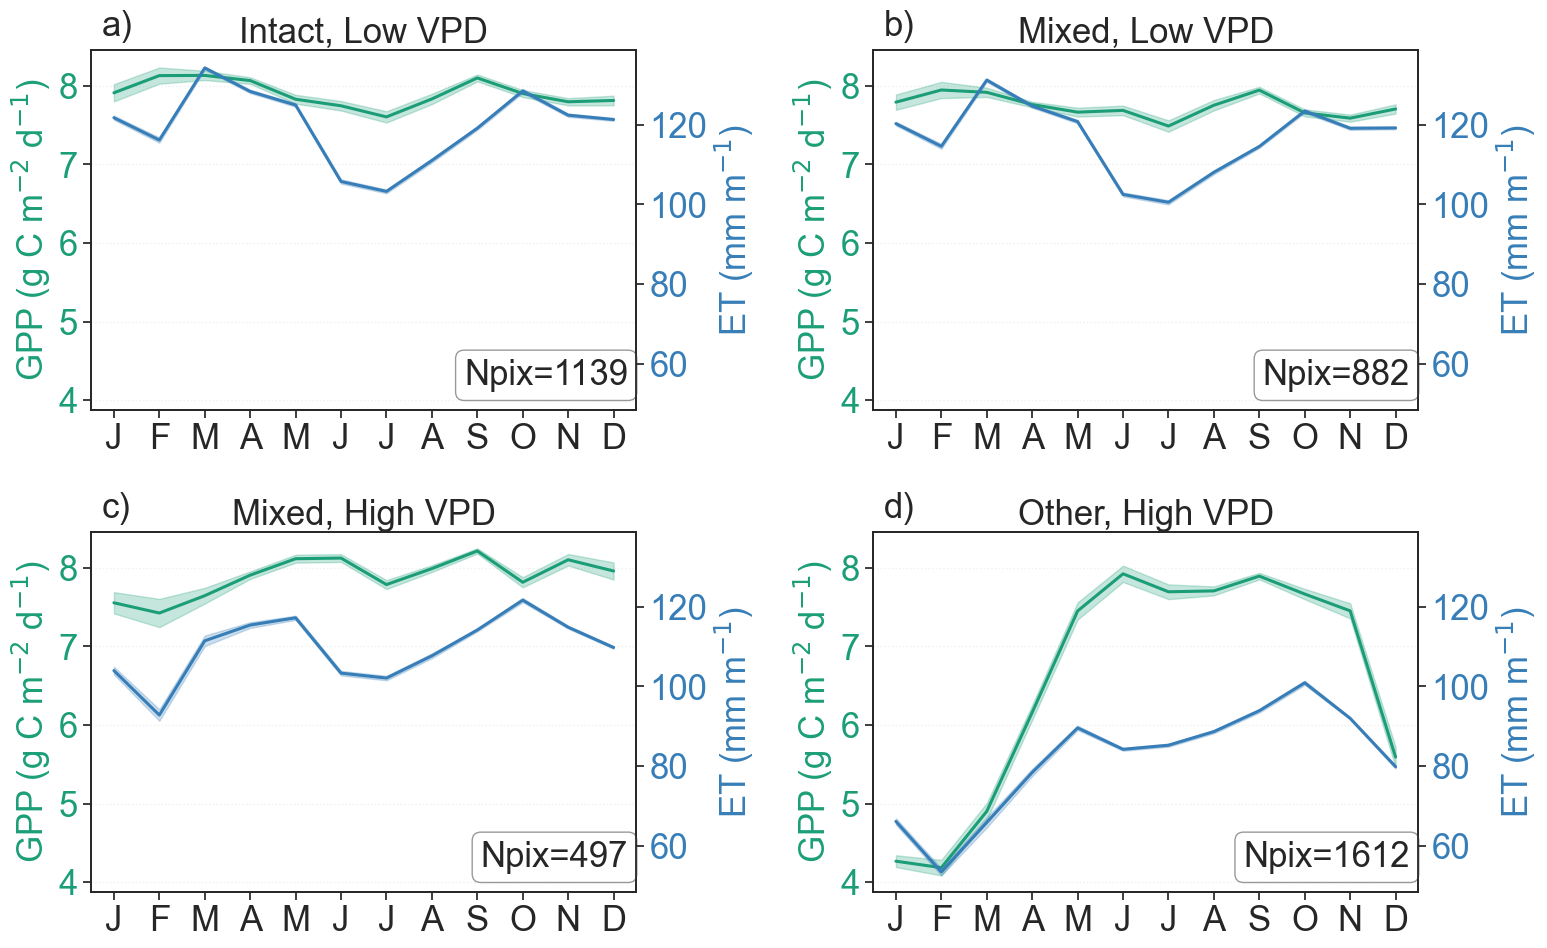

In [22]:
OUTPNG = "/Users/sworden/Documents/EqAfricaGPPETResults/JRCDisturbanceSeasonality_4regions.png"
VPD_THR_LINE = 5.51 

MONTH_NAMES = ["J","F","M","A","M","J","J","A","S","O","N","D"]
FONTS = {"title": 25, "axis_label": 25, "tick": 25, "npix": 25}
LINEW = 2.2
FILL_ALPHA = 0.25
GPP_COLOR = "#1b9e77"
ET_COLOR  = "#377eb8"

VPD_da = VPDFin
B_da   = JRC_static          # 0 Intact, 1 Disturbed, 2 Other, 3 Mixed
GPP_da = GPPNew
ET_da  = AET

# Congo domain
LAT1, LAT2 = -5, 8
LON1, LON2 = 8, 30

def monthly_clim_and_sem_over_years_areaweighted(da, mask_2d):
    """
    da: (time, lat, lon)
    mask_2d: (lat, lon) boolean
    Returns (mean_12, sem_12) over years for each month (area-weighted).
    """
    if "time" not in da.dims:
        raise ValueError("DataArray must have a 'time' dimension.")

    # apply mask
    da_m = da.where(mask_2d)

    # area weights ~ cos(lat)
    w = np.cos(np.deg2rad(da_m["lat"]))
    w = w.broadcast_like(da_m)

    # spatial mean time series
    ts = da_m.weighted(w).mean(dim=("lat", "lon"))

    # monthly climatology + SEM across time (years)
    grp = ts.groupby("time.month")
    m = grp.mean("time", skipna=True)
    s = grp.std("time", skipna=True)
    n = grp.count("time")
    se = s / np.sqrt(n)

    # ensure months 1..12 present/order
    m  = m.reindex(month=np.arange(1, 13))
    se = se.reindex(month=np.arange(1, 13))

    return m.values.astype(float), se.values.astype(float)

def plot_season_panel(ax, region_label, npix, gpp_mean, gpp_sem, et_mean, et_sem,
                      gpp_color=GPP_COLOR, et_color=ET_COLOR):
    x = np.arange(12)

    ax.set_title(f"{region_label}", fontsize=FONTS["title"], pad=4)
    ax.set_xlim(-0.5, 11.5)
    ax.set_xticks(x)
    ax.set_xticklabels(MONTH_NAMES, fontsize=FONTS["tick"])
    ax.grid(True, axis='y', linestyle=':', alpha=0.3, zorder=0)

    # GPP
    ax.plot(x, gpp_mean, color=gpp_color, lw=LINEW, zorder=5)
    ax.fill_between(x, gpp_mean - gpp_sem, gpp_mean + gpp_sem,
                    color=gpp_color, alpha=FILL_ALPHA, zorder=5)
    ax.set_ylabel(r'GPP (g C m$^{-2}$ d$^{-1}$)', color=gpp_color, fontsize=FONTS["axis_label"])
    ax.tick_params(axis='y', labelcolor=gpp_color, labelsize=FONTS["tick"])

    #ET (right)
    ax2 = ax.twinx()
    ax2.plot(x, et_mean, color=et_color, lw=LINEW, zorder=4)
    ax2.fill_between(x, et_mean - et_sem, et_mean + et_sem,
                     color=et_color, alpha=FILL_ALPHA, zorder=4)
    ax2.set_ylabel(r'ET (mm m$^{-1}$)', color=et_color, fontsize=FONTS["axis_label"])
    ax2.tick_params(axis='y', labelcolor=et_color, labelsize=FONTS["tick"])

    # Npix
    ax.text(
        0.985, 0.05, f"Npix={npix}",
        transform=ax.transAxes, ha='right', va='bottom',
        fontsize=FONTS["npix"],
        bbox=dict(facecolor='white', alpha=0.8, edgecolor='0.5', boxstyle='round,pad=0.25')
    )
    return ax, ax2

VPD_da = _ensure_latlon(VPD_da).sel(lat=slice(LAT1, LAT2), lon=slice(LON1, LON2))
B_da   = _ensure_latlon(B_da).sel(lat=slice(LAT1, LAT2), lon=slice(LON1, LON2))
GPP_da = _ensure_latlon(GPP_da).sel(lat=slice(LAT1, LAT2), lon=slice(LON1, LON2))
ET_da  = _ensure_latlon(ET_da).sel(lat=slice(LAT1, LAT2), lon=slice(LON1, LON2))

# make bucket & VPD spatial-only 
VPD_sp = _drop_time_if_present(VPD_da)
B_sp   = _drop_time_if_present(B_da)

# align all on common lat/lon
GPP2, ET2, VPD2, B2 = xr.align(GPP_da, ET_da, VPD_sp, B_sp, join="inner")

# DEFINE THE 4 REGION MASKS 
valid_sp = np.isfinite(VPD2) & np.isfinite(B2)

is_intact = (B2 == 0)
is_mixed  = (B2 == 3)
is_other  = (B2 == 2)

lowV  = (VPD2 <  VPD_THR_LINE)
highV = (VPD2 >= VPD_THR_LINE)

region_masks = {
    "Intact, Low VPD":      (is_intact & lowV  & valid_sp),
    "Mixed, Low VPD":       (is_mixed  & lowV  & valid_sp),
    "Mixed, High VPD":      (is_mixed  & highV & valid_sp),
    "Other, High VPD":      (is_other  & highV & valid_sp),
}

region_order = ["Intact, Low VPD", "Mixed, Low VPD", "Mixed, High VPD", "Other, High VPD"]

results = {}
gpp_min, gpp_max = np.inf, -np.inf
et_min,  et_max  = np.inf, -np.inf

for name in region_order:
    msk = region_masks[name].fillna(False)
    npix = int(msk.sum().item())

    gpp_mean, gpp_sem = monthly_clim_and_sem_over_years_areaweighted(GPP2, msk)
    et_mean,  et_sem  = monthly_clim_and_sem_over_years_areaweighted(ET2,  msk)

    results[name] = dict(npix=npix, gpp_mean=gpp_mean, gpp_sem=gpp_sem, et_mean=et_mean, et_sem=et_sem)

    if np.isfinite(gpp_mean).any():
        gpp_min = min(gpp_min, np.nanmin(gpp_mean - gpp_sem))
        gpp_max = max(gpp_max, np.nanmax(gpp_mean + gpp_sem))
    if np.isfinite(et_mean).any():
        et_min  = min(et_min,  np.nanmin(et_mean  - et_sem))
        et_max  = max(et_max,  np.nanmax(et_mean  + et_sem))

gpp_pad = 0.05 * (gpp_max - gpp_min) if np.isfinite(gpp_max - gpp_min) else 0.0
et_pad  = 0.05 * (et_max  - et_min)  if np.isfinite(et_max  - et_min)  else 0.0

# PLOT: 2x2 (a–d)
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.ravel()
letters = list(string.ascii_lowercase)

gpp_axes, et_axes = [], []

for i, name in enumerate(region_order):
    ax = axes[i]
    r = results[name]

    axL, axR = plot_season_panel(
        ax, name, r["npix"],
        r["gpp_mean"], r["gpp_sem"],
        r["et_mean"],  r["et_sem"],
    )

    axL.text(0.02, 1.02, f"{letters[i]})", transform=axL.transAxes,
             fontsize=FONTS["title"], va="bottom", ha="left")

    gpp_axes.append(axL)
    et_axes.append(axR)

# shared y-lims across all 4 panels
for axL in gpp_axes:
    if np.isfinite(gpp_min) and np.isfinite(gpp_max):
        axL.set_ylim(gpp_min - gpp_pad, gpp_max + gpp_pad)
for axR in et_axes:
    if np.isfinite(et_min) and np.isfinite(et_max):
        axR.set_ylim(et_min - et_pad, et_max + et_pad)

plt.tight_layout()
plt.savefig("/Users/sworden/Documents/EqAfricaGPPETResults/JRCDisturbanceSeasonality_4regions.png", dpi=300, bbox_inches="tight")
plt.show()


### Supplementary Figure 6

In [23]:
file='/Users/sworden/Downloads/AfricaDEM.tif'

tif=gdal.Open(file)
lats, lons = gdal_latlon(tif)
# --- 2) Read the raster into a 2D NumPy array ---
# if multi‐band, pick band 1; here SRTM is single‐band
band = tif.GetRasterBand(1)
arr  = band.ReadAsArray()   # shape = (ny, nx)

# --- 3) Wrap into an xarray.DataArray ---
dem = xr.DataArray(
    arr,
    dims=('lat','lon'),
    coords={
        'lat': lats,
        'lon': lons
    },
    name='elevation',
    attrs={
        'units': 'm',
        'crs': tif.GetProjection()
    }
)

demNew=dem.interp(lat=VPDArr.lat,lon=VPDArr.lon)
demNew=demNew.where(demNew>=0)


In [24]:
# ET in kg m-2 s-1 for conductance calculation
AET_G = AET.sel(lat=slice(-15, 10), lon=slice(0, 35))
seconds_per_month = AET_G.time.dt.days_in_month * 24 * 3600
AET_si = AET_G / seconds_per_month
AET_si.name = "et_kg_m2_s"
AET_si.attrs["units"] = "kg m-2 s-1"

ETsi_R1 = AET_si.sel(lat=slice(3.5, 7), lon=slice(8, 30)).where(TrendArr > 0)
ETsi_R2 = AET_si.sel(lat=slice(-8, 0), lon=slice(15, 30)).where(TrendArr > 0)
ETsi_R3 = AET_si.sel(lat=slice(-5, 5), lon=slice(8, 30)).where(TrendArr <= 0)


In [25]:
TArrFin=TArr.sel(lat=slice(-15,10), lon=slice(0, 35))
TR1=TArrFin.sel(lat=slice(3.5,7),lon=slice(8, 30)).where(TrendArr>0)
TR2=TArrFin.sel(lat=slice(-8,0),lon=slice(15,30)).where(TrendArr>0)
TR3=TArrFin.sel(lat=slice(-5,5),lon=slice(8,30)).where(TrendArr<=0)
VPDArrFin=VPDArr.sel(lat=slice(-15,10), lon=slice(0, 35))*0.1 #Convert from hPa to kPa
VPDR1=VPDArrFin.sel(lat=slice(3.5,7),lon=slice(8, 30)).where(TrendArr>0)
VPDR2=VPDArrFin.sel(lat=slice(-8,0),lon=slice(15,30)).where(TrendArr>0)
VPDR3=VPDArrFin.sel(lat=slice(-5,5),lon=slice(8,30)).where(TrendArr<=0)
demNewFin=demNew.sel(lat=slice(-15,10),lon=slice(0,35))
demR1=demNewFin.sel(lat=slice(3.5,7),lon=slice(8, 30)).where(TrendArr>0)
demR2=demNewFin.sel(lat=slice(-8,0),lon=slice(15,30)).where(TrendArr>0)
demR3=demNewFin.sel(lat=slice(-5,5),lon=slice(8,30)).where(TrendArr<=0)

In [26]:
P1 = (115.8+0.4236*np.array(TArrFin))*AET_si/(np.array(VPDArrFin))

In [27]:
n=44.6
T0=273
P2=T0/(T0+np.array(TArrFin))
P3=np.exp(-.00012*np.array(demNewFin))

In [28]:
G=P1*n*P2*P3
GR1=G.sel(lat=slice(3.5,7),lon=slice(8, 30)).where(TrendArr>0)
GR2=G.sel(lat=slice(-8,0),lon=slice(15,30)).where(TrendArr>0)
GR3=G.sel(lat=slice(-5,5),lon=slice(8,30)).where(TrendArr<=0)




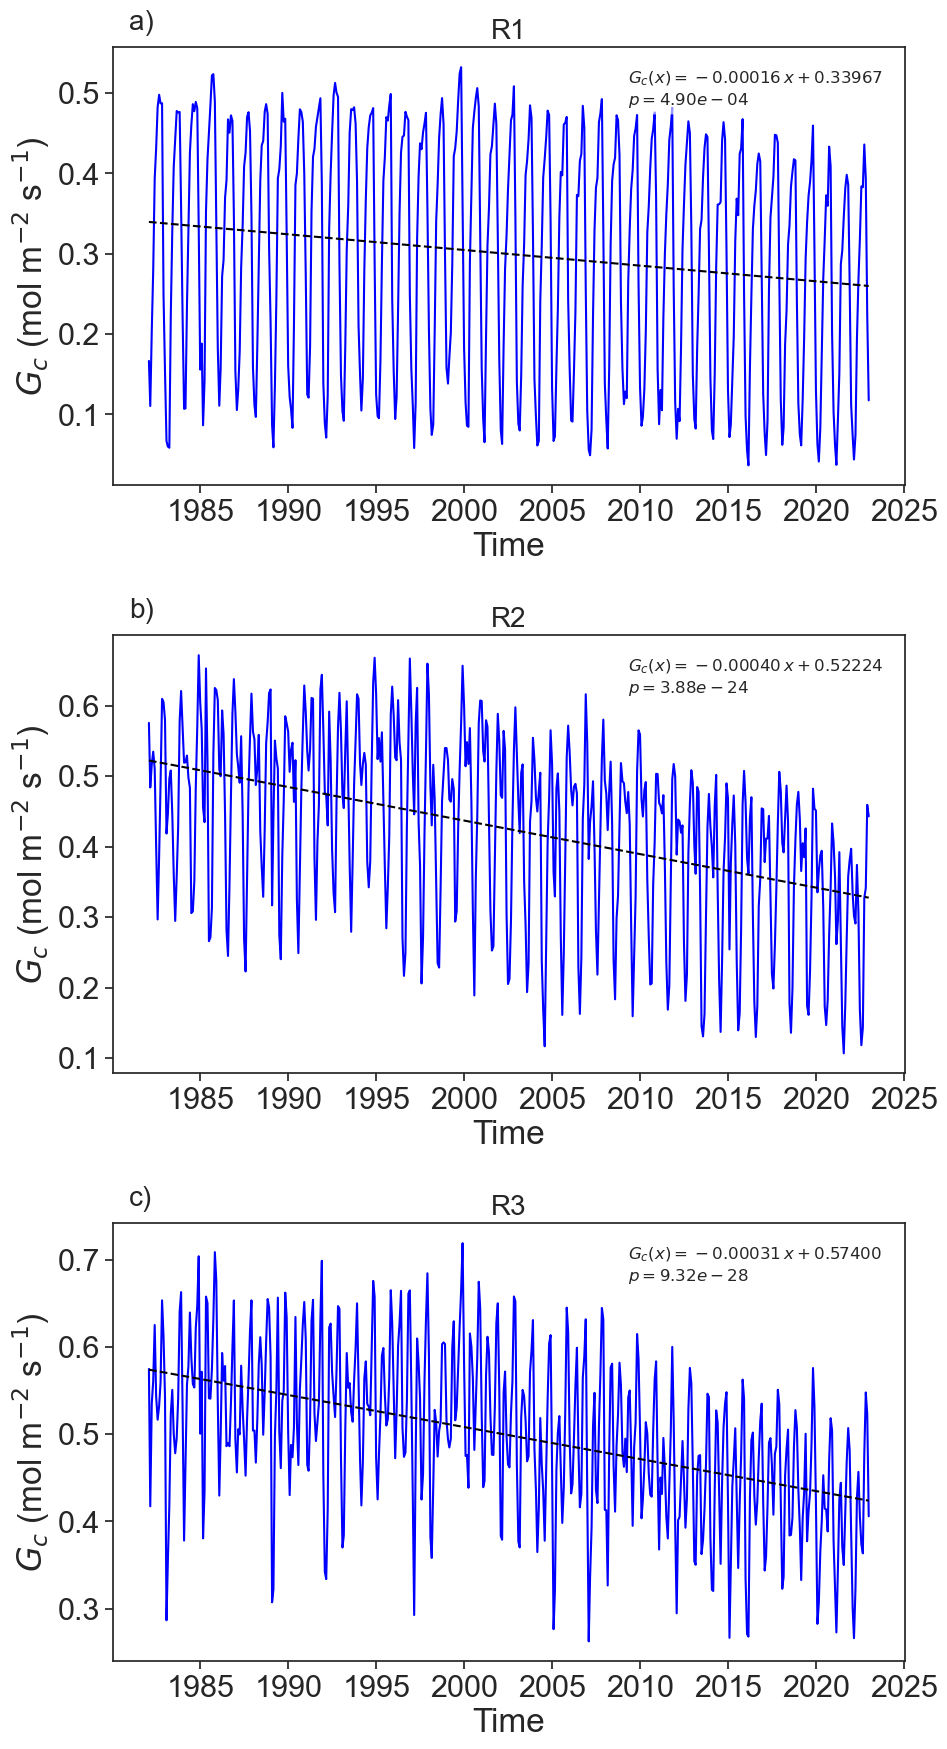

In [29]:


fig, axes = plt.subplots(3, 1, figsize=(10, 18))
regions = [
    (GR1, 'R1', 'a)'),
    (GR2,   'R2',   'b)'),
    (GR3,     'R3',     'c)')
]

# Custom positions for each panel’s equation box (axes fraction)
eqn_positions = [
    (0.65, 0.95),  # panel a
    (0.65, 0.95),  # panel b
    (0.65, 0.95),  # panel c
]

for (ax, (data, title, letter), (xp, yp)) in zip(axes, regions, eqn_positions):
    ts = data.mean(axis=(1,2)).values
    times = data.time.values

    # fit trend
    x = np.arange(len(ts))
    slope, intercept, r, pval, se = linregress(x, ts)
    trend = intercept + slope * x

    # plot data + trend
    ax.plot(times, ts, color='blue')
    ax.plot(times, trend, '--', color='black', label='Trend')

    # build equation string
    eqn = (
        rf"$G_c (x) = {slope:.5f}\,x {'+' if intercept>=0 else '-'} {abs(intercept):.5f}$"
        "\n" rf"$p = {pval:.2e}$"
    )

    # place text with semi‐opaque white fill, no edge
    ax.text(
        xp, yp, eqn,
        transform=ax.transAxes,
        fontsize=12,
        va='top', ha='left',
        bbox=dict(
            boxstyle="round,pad=0.3",
            facecolor=(1,1,1,0.6),
            edgecolor='none'
        )
    )

    # styling
    ax.set_title(title, loc='center', fontsize=20)
    ax.set_ylabel(r'$G_c$ (mol m$^{-2}$ s$^{-1}$)')
    ax.set_xlabel('Time')
    ax.text(
        0.02, 1.04, letter,
        transform=ax.transAxes,
        fontsize=20
    )

plt.tight_layout()
plt.savefig(
    '/Users/sworden/Documents/EqAfricaGPPETResults/G_3_Regions_with_equations9.9.png',
    bbox_inches='tight'
)
plt.show()


### Supplementary Figures 7-9

In [30]:
#helpers
def _as_month_start(da: xr.DataArray) -> xr.DataArray:
    ts = pd.to_datetime(da.time.values).to_period("M").to_timestamp(how="start")
    return da.assign_coords(time=ts).sortby("time")

def _spatial_mean(da: xr.DataArray) -> xr.DataArray:
    dims = [d for d in ("lat","lon","y","x","latitude","longitude") if d in da.dims]
    return da.mean(dim=dims, skipna=True) if dims else da

def detrend_keep_mean_1d(da: xr.DataArray) -> xr.DataArray:
    """Detrend a 1D (time) series, keep mean."""
    y = da.values.astype(float)
    m = np.isfinite(y)
    if m.sum() < 3:
        return da * np.nan

    # numeric time in years 
    dti = pd.DatetimeIndex(pd.to_datetime(da.time.values))
    days = (dti.asi8 // 86_400_000_000_000).astype(float)  # ns -> days
    days -= days[0]
    t = days / 365.25

    A = np.vstack([t[m], np.ones(m.sum())]).T
    a, b = np.linalg.lstsq(A, y[m], rcond=None)[0]
    trend = a * t + b
    y_detr = y - trend + np.nanmean(y[m])

    return xr.DataArray(y_detr, coords=da.coords, dims=da.dims, name=(da.name or "detrended"))

def G_from_inputs(ET_si, VPD_kPa, T_C, DEM, n=44.6, T0=273.0, eps=1e-6):
    """
    Pixelwise canopy conductance-like quantity:
      ET [kg m-2 s-1], VPD [kPa], T [°C], DEM [m]
    """
    # month-start + strict alignment (label-based)
    ET_si   = _as_month_start(ET_si)
    VPD_kPa = _as_month_start(VPD_kPa)
    T_C     = _as_month_start(T_C)

    ET_si, VPD_kPa, T_C = xr.align(ET_si, VPD_kPa, T_C, join="inner")

    # DEM: broadcast to (time,lat,lon)
    if "time" in DEM.dims:
        DEM = DEM.sel(time=ET_si.time)
    else:
        DEM = DEM.broadcast_like(ET_si)

    # guard VPD
    VPD_kPa = xr.where(VPD_kPa > eps, VPD_kPa, np.nan)

    P1 = (115.8 + 0.4236 * T_C) * ET_si / VPD_kPa
    P2 = T0 / (T0 + T_C)
    P3 = np.exp(-0.00012 * DEM)

    return (P1 * n * P2 * P3).rename("G")

def _plot_one_driver(ax_left, ax_right, time, drv_orig, drv_detr, G_base, G_cf, driver_label, vlines=None):
    ax_left.plot(time, drv_orig, lw=1.8, label="original")
    ax_left.plot(time, drv_detr, lw=1.8, label="detrended")
    ax_left.grid(True, ls=":", alpha=0.4)

    ax_right.plot(time, G_base, lw=1.8, label="original")
    ax_right.plot(time, G_cf, lw=1.8, label=f"detrended {driver_label}")
    ax_right.grid(True, ls=":", alpha=0.4)

    for v in (vlines or []):
        ax_left.axvline(np.datetime64(v), ls=":", lw=1, color="k", alpha=0.7)
        ax_right.axvline(np.datetime64(v), ls=":", lw=1, color="k", alpha=0.7)

#main
def plot_driver_and_G_with_detrend_pixelwise(
    ET_field, VPD_field, T_field, DEM_field,
    region_title="",
    vlines=("1998-01-01","2005-01-01","2015-01-01"),
):
    """
    Baseline: compute G pixelwise then spatial-mean.
    Counterfactuals: detrend the *spatial-mean* driver, then apply that
    detrended signal back to the full field and recompute pixelwise G.
    """
    # month-start + align all three
    ET_field  = _as_month_start(ET_field)
    VPD_field = _as_month_start(VPD_field)
    T_field   = _as_month_start(T_field)

    ET_field, VPD_field, T_field = xr.align(ET_field, VPD_field, T_field, join="inner")
    if ET_field.sizes.get("time", 0) == 0:
        raise ValueError("Empty time overlap after alignment. Check ET/VPD/T time coords.")

    # baseline G pixelwise -> spatial mean
    G_map = G_from_inputs(ET_field, VPD_field, T_field, DEM_field, T0=273.0)
    G0 = _spatial_mean(G_map)

    # spatial-mean drivers (for detrending signal)
    ETs  = _spatial_mean(ET_field)
    VPDs = _spatial_mean(VPD_field)
    Ts   = _spatial_mean(T_field)

    # detrend 1D time series
    ET_d  = detrend_keep_mean_1d(ETs)
    VPD_d = detrend_keep_mean_1d(VPDs)
    T_d   = detrend_keep_mean_1d(Ts)

    # apply detrended signals back to full fields
    # ET, VPD: multiplicative scaling (preserves spatial pattern)
    ET_ratio  = (ET_d / ETs).broadcast_like(ET_field)
    VPD_ratio = (VPD_d / VPDs).broadcast_like(VPD_field)

    ET_cf  = ET_field * ET_ratio
    VPD_cf = VPD_field * VPD_ratio

    # T: additive offset (preserves spatial anomalies)
    T_offset = (T_d - Ts).broadcast_like(T_field)
    T_cf = T_field + T_offset

    # recompute G pixelwise for each counterfactual -> spatial mean
    G_VPDd = _spatial_mean(G_from_inputs(ET_field, VPD_cf, T_field, DEM_field, T0=273.0))
    G_ETd  = _spatial_mean(G_from_inputs(ET_cf,  VPD_field, T_field, DEM_field, T0=273.0))
    G_Td   = _spatial_mean(G_from_inputs(ET_field, VPD_field, T_cf,  DEM_field, T0=273.0))

    time = G0.time.values

    # plot
    fig, axes = plt.subplots(3, 2, figsize=(14, 11), sharex=True)
    (ax_vpd_L, ax_vpd_R), (ax_et_L, ax_et_R), (ax_t_L, ax_t_R) = axes

    _plot_one_driver(ax_vpd_L, ax_vpd_R, time, VPDs.values, VPD_d.values, G0.values, G_VPDd.values, "VPD", vlines=vlines)
    ax_vpd_L.set_ylabel("VPD (kPa)")
    ax_vpd_R.set_ylabel("G")

    _plot_one_driver(ax_et_L, ax_et_R, time, ETs.values, ET_d.values, G0.values, G_ETd.values, "ET", vlines=vlines)
    ax_et_L.set_ylabel("ET (kg m$^{-2}$ s$^{-1}$)")
    ax_et_R.set_ylabel("G")

    _plot_one_driver(ax_t_L, ax_t_R, time, Ts.values, T_d.values, G0.values, G_Td.values, "T", vlines=vlines)
    ax_t_L.set_ylabel("T (°C)")
    ax_t_R.set_ylabel("G")

    # labels
    labels = ['a)', 'b)', 'c)', 'd)', 'e)', 'f)']
    for lab, ax in zip(labels, axes.flatten()):
        ax.text(0.01, 0.85, lab, transform=ax.transAxes, fontsize=20, fontweight='normal')

    # legends
    handles, lbls = ax_vpd_L.get_legend_handles_labels()
    fig.legend(handles, lbls, loc="upper center", bbox_to_anchor=(0.28, 0.95), ncol=2, frameon=False)

    handles, lbls = ax_vpd_R.get_legend_handles_labels()
    fig.legend(handles, lbls, loc="upper center", bbox_to_anchor=(0.74, 0.95), ncol=2, frameon=False)

    # x tick rotation
    for ax in axes[-1, :]:
        ax.set_xlabel("time")
        ax.tick_params(axis='x', labelrotation=45)
        for lbl in ax.get_xticklabels():
            lbl.set_ha('right')

    fig.suptitle(region_title, y=0.995, fontsize=20)
    fig.tight_layout(rect=[0, 0, 1, 0.97])

    print(f"\n[{region_title}] Mean ΔG from detrending (spatial-mean signal applied to field):")
    print(f"  VPD detrended: {float(np.nanmean(G_VPDd - G0)):+.4g}")
    print(f"  ET  detrended: {float(np.nanmean(G_ETd  - G0)):+.4g}")
    print(f"  T   detrended: {float(np.nanmean(G_Td   - G0)):+.4g}")

    return fig, dict(G_baseline=G0, G_VPD_detr=G_VPDd, G_ET_detr=G_ETd, G_T_detr=G_Td)





[R1] Mean ΔG from detrending (spatial-mean signal applied to field):
  VPD detrended: -7.844e-05
  ET  detrended: -0.0002805
  T   detrended: -3.59e-08


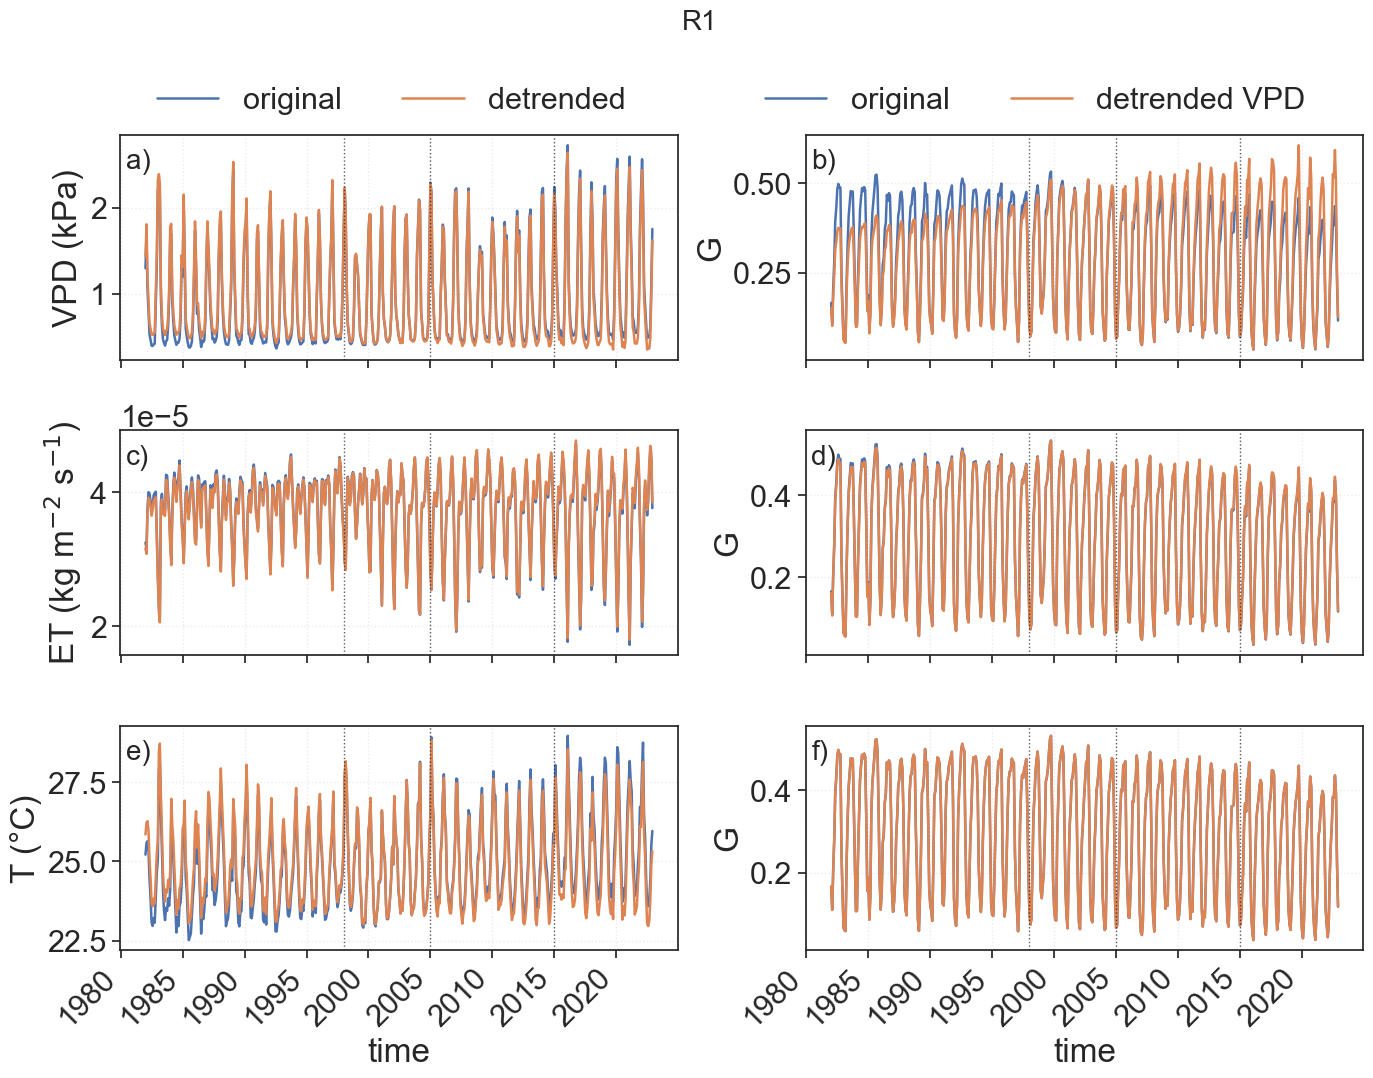


[R2] Mean ΔG from detrending (spatial-mean signal applied to field):
  VPD detrended: -0.004903
  ET  detrended: -0.0007372
  T   detrended: -9.767e-08


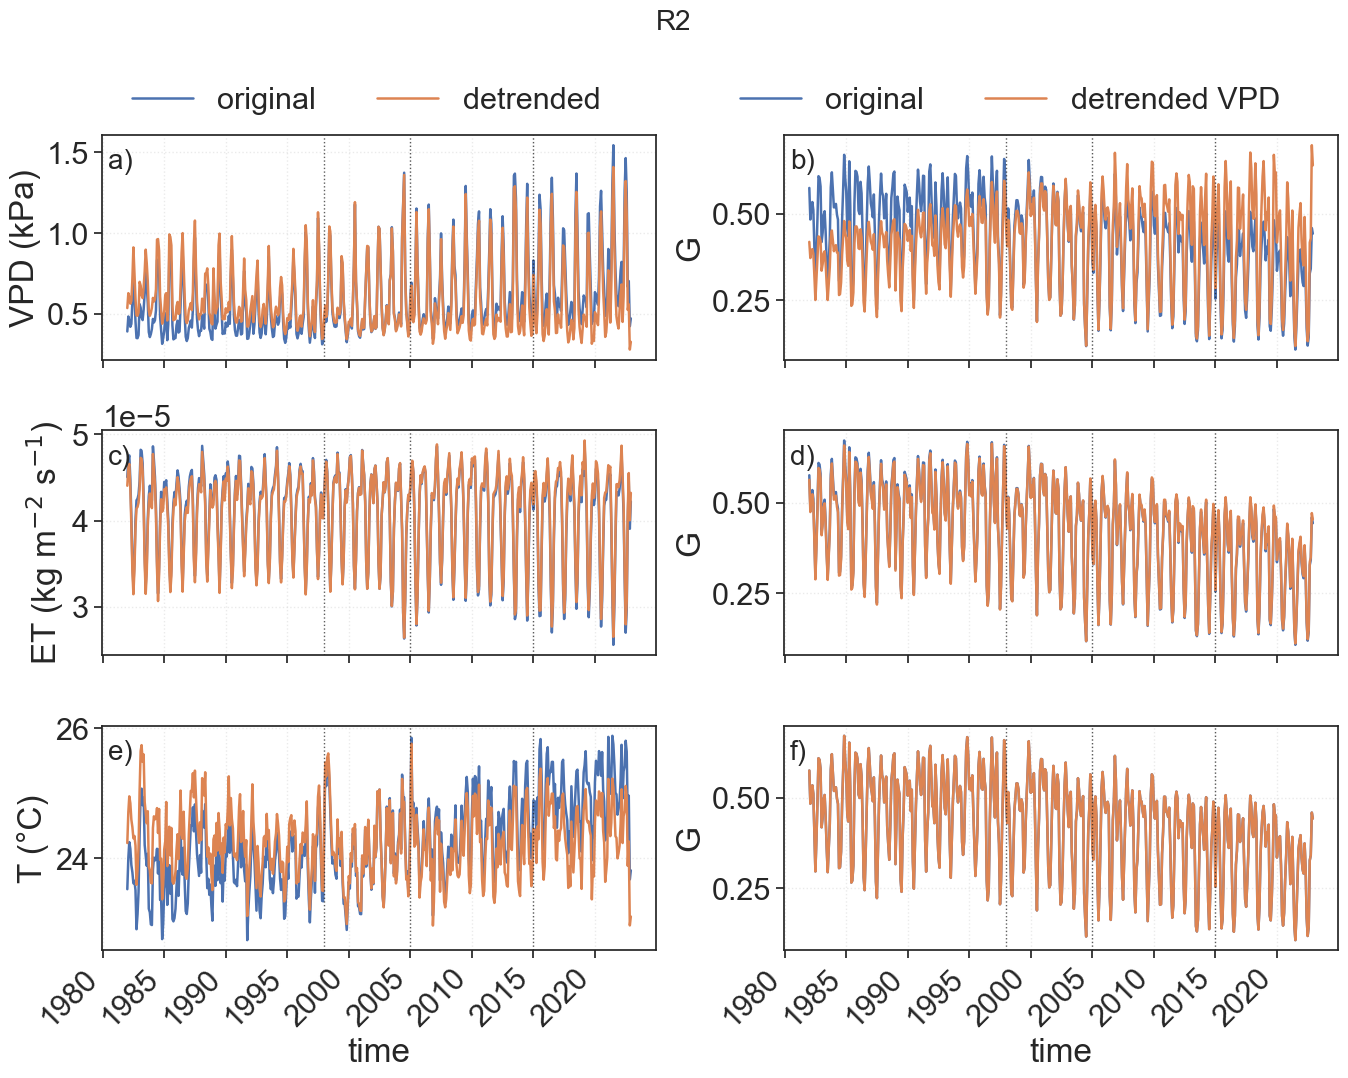


[R3] Mean ΔG from detrending (spatial-mean signal applied to field):
  VPD detrended: -0.003768
  ET  detrended: +1.388e-05
  T   detrended: -7.001e-08


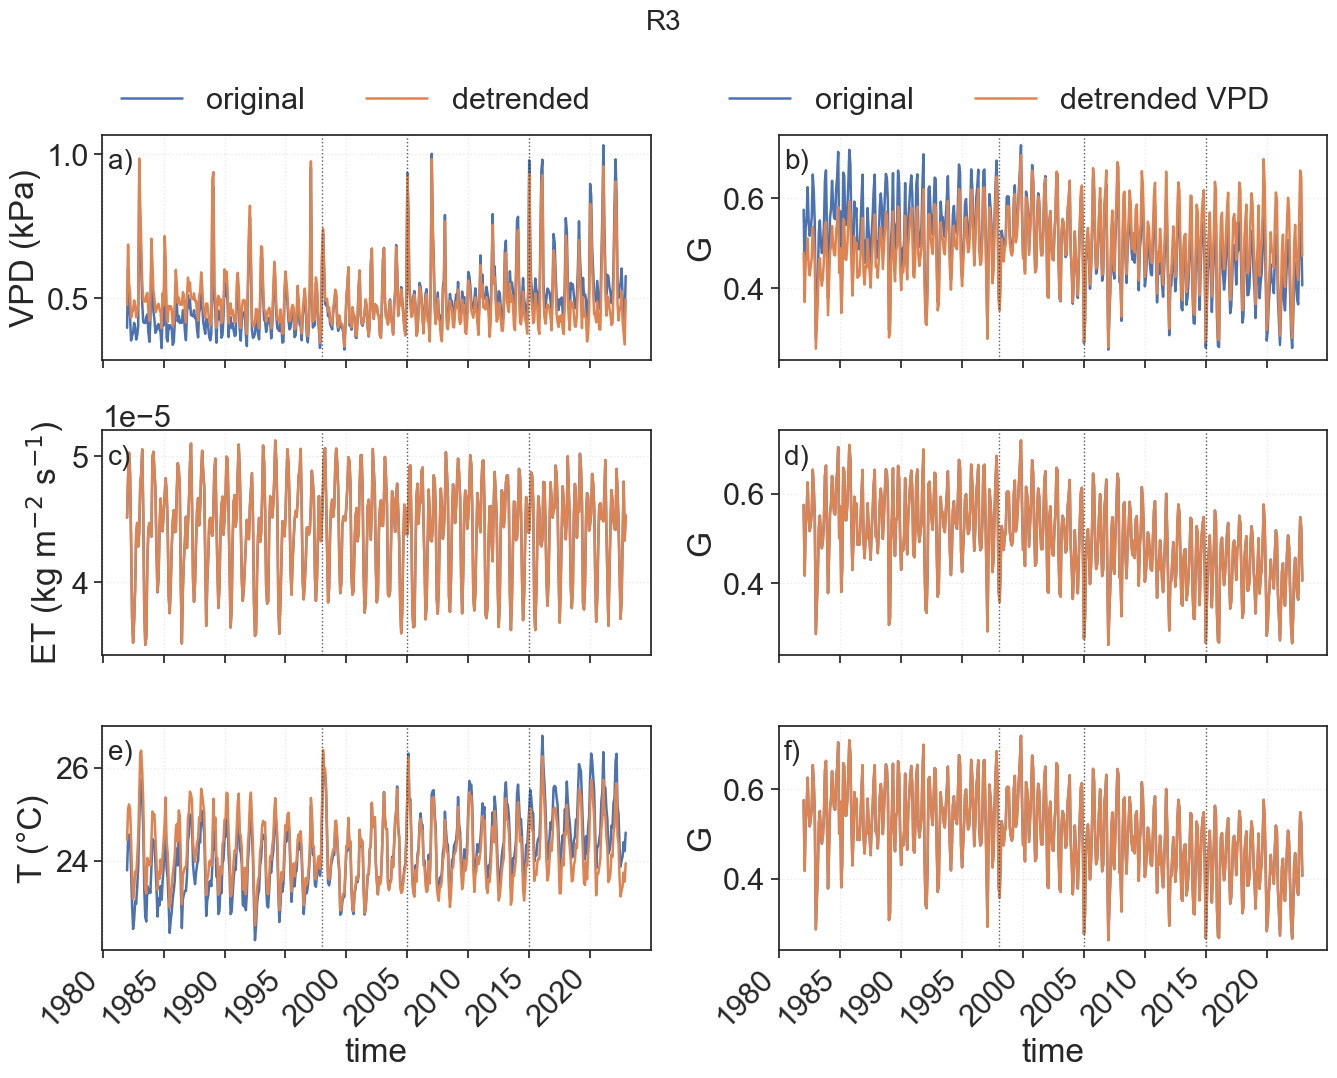

In [31]:
for region, ET_reg, VPD_reg, T_reg, DEM_reg in [
    ("R1", ETsi_R1, VPDR1, TR1, demR1),
    ("R2", ETsi_R2, VPDR2, TR2, demR2),
    ("R3", ETsi_R3, VPDR3, TR3, demR3),
]:
    fig, out = plot_driver_and_G_with_detrend_pixelwise(
        ET_reg, VPD_reg, T_reg, DEM_reg, region_title=region
    )
    fig.savefig(
        f"/Users/sworden/Documents/EqAfricaGPPETResults/G_detrend_{region}.png",
        dpi=300, bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)


### Supplementary Figure 10

In [33]:
## Madani GPP before interpolating to ET grid
GPPMad = GPPFinArr.copy()

In [34]:
## Bi et al. (2020) GPP
directory = '/Users/sworden/Documents/BiSunShadeGPP/'
file_paths = [os.path.join(directory, file) for file in os.listdir(directory) if file.endswith('.tif') and file.startswith('GPP')]
def extract_month_year2(file_path):
    # Extract the year and month from the file name
    parts = file_path.split('_')
    year = int(parts[-2])
    month = int(parts[-1].split('.')[0])
    return year, month

tiff_files = sorted(file_paths, key=extract_month_year2)

## get lat/lon info from the tiffiles
tif=gdal.Open(tiff_files[0])
lats, lons = gdal_latlon(tif)

latTest = lats[(lats>-15) & (lats<10)]
lonTest = lons[(lons>0) & (lons<35)]

time=pd.date_range('1992-01-01','2020-12-01',freq='MS')
arrays =np.zeros((len(time),len(latTest),len(lonTest)))
x=0
##open and append files into list of arrays
for file in tiff_files:
    tif = gdal.Open(file)
    arr = tif.ReadAsArray()
    arr = arr[(lats>-15) & (lats<10),:]
    arr = arr[:,(lons>0) & (lons<35)]
    arrays[x,:,:]=arr*0.1
    x+=1

BiGPP=xr.DataArray(arrays,coords=[time,latTest,lonTest],dims=['time','lat','lon'])[:,::-1,:]
days_in_month = BiGPP.time.dt.days_in_month
##convert to per day to be same units at Madani GPP
BiGPP=BiGPP/days_in_month 
BiGPP=BiGPP.where(BiGPP>0)


In [35]:
test=xr.open_dataset('/Users/sworden/Documents/VODGPP/VODCA2GPP_v1.nc')
GPP_VOD=test.GPP.sel(lat=slice(-15, 10),lon=slice(0,35))

In [36]:
def align_three_gpp(GPP_VOD, Bi_GPP, GPPMad, method="linear"):
    """
    Make 3 GPP DataArrays comparable:
      1) rename latitude/longitude -> lat/lon (if needed)
      2) resample all to monthly means at month-start (MS)
      3) keep only the common overlapping time stamps
      4) regrid VOD + Bi to GPPMad's lat/lon grid (lat sorted ascending)

    Returns: (GPP_VOD_aligned, Bi_GPP_aligned, GPPMad_aligned)
    """


    def _prep(da):
        # rename coords if needed
        rename = {}
        if "latitude"  in da.dims: rename["latitude"]  = "lat"
        if "longitude" in da.dims: rename["longitude"] = "lon"
        if rename:
            da = da.rename(rename)

        # monthly at month-start
        if "time" in da.dims:
            da = da.resample(time="MS").mean("time").sortby("time")

        # sort lat ascending for stable interp / consistent grids
        if "lat" in da.dims and np.any(np.diff(da.lat.values) < 0):
            da = da.sortby("lat")

        return da

    vod_m = _prep(GPP_VOD)
    bi_m  = _prep(Bi_GPP)
    mad_m = _prep(GPPMad)

    # common time intersection
    common_time = vod_m.time.to_index().intersection(bi_m.time.to_index()).intersection(mad_m.time.to_index())
    common_time = common_time.sort_values()

    vod_c = vod_m.sel(time=common_time)
    bi_c  = bi_m.sel(time=common_time)
    mad_c = mad_m.sel(time=common_time)

    # regrid to MAD grid
    template = mad_c
    vod_rg = vod_c.interp(lat=template.lat, lon=template.lon, method=method)
    bi_rg  = bi_c.interp(lat=template.lat, lon=template.lon, method=method)

    return vod_rg, bi_rg, mad_c


In [37]:
GPP_VOD_aligned, BiGPP_aligned, GPPMad_aligned = align_three_gpp(
    GPP_VOD,
    BiGPP,
    GPPMad,
)

aligned_GPP = [GPP_VOD_aligned, BiGPP_aligned, GPPMad_aligned]


In [38]:
def extended_triple_collocation(y):
    """
    Extended Triple Collocation (ETC) estimates the variance of noise errors (errVar_ETC) and
    the squared correlation coefficients (rho2_ETC) of three measurement systems.
    
    Parameters:
    - y (numpy.ndarray): N x 3 matrix where columns are observations from three systems.
                         N is the number of observations, and it must not contain NaNs.
    
    Returns:
    - errVar_ETC (numpy.ndarray): 3 x 1 vector of error variances.
    - rho2_ETC (numpy.ndarray): 3 x 1 vector of squared correlation coefficients.
    """
    if y.shape[1] != 3:
        raise ValueError("Input data y must be an N x 3 matrix.")
    if np.isnan(y).any():
        raise ValueError("Input data y must not contain NaNs.")
    if any(np.var(y[:, i]) == 0 for i in range(3)):
        raise ValueError("Sample variance of each column must be non-zero.")
    
    # Estimate covariance matrix
    Q_hat = np.cov(y, rowvar=False)
    
    # Compute correlation coefficients
    rho_ETC = np.array([
        np.sqrt(Q_hat[0, 1] * Q_hat[0, 2] / (Q_hat[0, 0] * Q_hat[1, 2])),
        np.sign(Q_hat[0, 2] * Q_hat[1, 2]) * np.sqrt(Q_hat[0, 1] * Q_hat[1, 2] / (Q_hat[1, 1] * Q_hat[0, 2])),
        np.sign(Q_hat[0, 1] * Q_hat[1, 2]) * np.sqrt(Q_hat[0, 2] * Q_hat[1, 2] / (Q_hat[2, 2] * Q_hat[0, 1]))
    ])
    rho2_ETC = rho_ETC**2
    
    # Compute error variances
    errVar_ETC = np.array([
        Q_hat[0, 0] - Q_hat[0, 1] * Q_hat[0, 2] / Q_hat[1, 2],
        Q_hat[1, 1] - Q_hat[0, 1] * Q_hat[1, 2] / Q_hat[0, 2],
        Q_hat[2, 2] - Q_hat[0, 2] * Q_hat[1, 2] / Q_hat[0, 1]
    ])
    
    
    return errVar_ETC, rho2_ETC

In [39]:
## This code performs the TC method on the 3 different GPP datsets averaged over the entire South American domain
da1 = aligned_GPP[0]# VOD GPP
da2 = aligned_GPP[1]# Bi et al. (2022) GPP
da3 = aligned_GPP[2]# Madani et al. (2020) GPP 

# Align the DataArrays and stack for ETC analysis
da1_flat = da1.stack(points=("time", "lat", "lon")).values
da2_flat = da2.stack(points=("time", "lat", "lon")).values
da3_flat = da3.stack(points=("time", "lat", "lon")).values

# Remove NaNs
mask = ~np.isnan(da1_flat) & ~np.isnan(da2_flat) & ~np.isnan(da3_flat)
y_matrix = np.column_stack((da1_flat[mask], da2_flat[mask], da3_flat[mask]))

# Apply ETC function
errVar_ETC, rho2_ETC = extended_triple_collocation(y_matrix)

# Print Results
print("The error variance and squared correlation coefficients across the Congo domain are:")
print("Error Variance (ETC):", np.sqrt(errVar_ETC))
print("Squared Correlation Coefficients (ETC):", rho2_ETC)

The error variance and squared correlation coefficients across the Congo domain are:
Error Variance (ETC): [1.63352179 1.83272103 1.26307112]
Squared Correlation Coefficients (ETC): [0.52766264 0.67946938 0.70092553]


In [40]:
#   1) Intact  + Low VPD
#   2) Mixed   + Low VPD
#   3) Mixed   + High VPD
#   4) Other   + High VPD

# Helpers

# Build the 4 group masks ONCE (lat, lon)
# Bucket4 map: 0 Intact, 1 Disturbed, 2 Other, 3 Mixed
B_da = _drop_time_if_present(_ensure_latlon(bucket4))

VPD_map = _drop_time_if_present(_ensure_latlon(VPDFin))

# Align on the same lat/lon grid
B2, VPD2 = xr.align(B_da, VPD_map, join="inner")

# Low/high masks from VPD_star
lowV  = (VPD2 <  VPD_star)
highV = (VPD2 >= VPD_star)

# Veg masks
is_intact = (B2 == 0)
is_mixed  = (B2 == 3)
is_other  = (B2 == 2)

group_masks = {
    "Intact_LowVPD":  (is_intact & lowV),
    "Mixed_LowVPD":   (is_mixed  & lowV),
    "Mixed_HighVPD":  (is_mixed  & highV),
    "Other_HighVPD":  (is_other  & highV),
}

# Run ETC for each group
def run_etc_for_groups(da1, da2, da3,
                       group_masks,
                       product_names=("GPP_VOD", "BiGPP", "GPPMad")):
    """
    da1, da2, da3 : xr.DataArray
        GPP products (time, lat, lon), already aligned or alignable.
    group_masks : dict[str -> xr.DataArray]
        Each mask is boolean (lat, lon).
    """

    da1 = _ensure_latlon(da1)
    da2 = _ensure_latlon(da2)
    da3 = _ensure_latlon(da3)

    # Align products once (time, lat, lon)
    da1a, da2a, da3a = xr.align(da1, da2, da3, join="inner")

    for gname, m_ll in group_masks.items():
        # Align mask to product grid (lat, lon)
        m2, _ = xr.align(m_ll, da1a.isel(time=0, drop=True), join="inner")

        # Apply mask (broadcasts over time)
        x1 = da1a.where(m2)
        x2 = da2a.where(m2)
        x3 = da3a.where(m2)

        # Flatten to 1D points
        a1 = x1.stack(points=("time", "lat", "lon")).values
        a2 = x2.stack(points=("time", "lat", "lon")).values
        a3 = x3.stack(points=("time", "lat", "lon")).values

        # Joint finite mask across the 3 products
        mask = np.isfinite(a1) & np.isfinite(a2) & np.isfinite(a3)

        if mask.sum() == 0:
            print(f"\nGroup: {gname} — no valid points after masking")
            continue

        # Means over the same valid points
        means = np.array([a1[mask].mean(), a2[mask].mean(), a3[mask].mean()])

        # ETC
        y_matrix = np.column_stack((a1[mask], a2[mask], a3[mask]))
        Y = y_matrix - np.mean(y_matrix, axis=0)

        errVar_ETC, rho2_ETC = extended_triple_collocation(Y)
        
        print("  errVar_ETC (raw)      :", errVar_ETC)
        print("  rho2_ETC  (raw)       :", rho2_ETC)
        
        C = np.cov(Y.T, bias=False)
        R = np.corrcoef(Y.T)
        print("  cov matrix:\n", C)
        print("  corr matrix:\n", R)
        print("  cov12, cov13, cov23   :", C[0,1], C[0,2], C[1,2])
        errVar_ETC, rho2_ETC = extended_triple_collocation(y_matrix)
        rmse_ETC = np.sqrt(errVar_ETC)

        print(f"\nGroup: {gname}")
        print("  Products (order):", product_names)
        print("  N points              :", int(mask.sum()))
        print("  Mean GPP              :", means)
        print("  RMSE (sqrt err var)   :", rmse_ETC)
        print("  R^2 (ETC)             :", rho2_ETC)

run_etc_for_groups(
    GPP_VOD_aligned,
    BiGPP_aligned,
    GPPMad_aligned,
    group_masks,
    product_names=("GPP_VOD", "BiGPP", "GPPMad"),
)


  errVar_ETC (raw)      : [ 0.17107864  0.94169182 -1.35285444]
  rho2_ETC  (raw)       : [0.00799554 0.02455669 2.05147942]
  cov matrix:
 [[ 0.17245753 -0.00571746 -0.06032866]
 [-0.00571746  0.96539881  0.25014797]
 [-0.06032866  0.25014797  1.28662   ]]
  corr matrix:
 [[ 1.         -0.01401228 -0.12807295]
 [-0.01401228  1.          0.2244494 ]
 [-0.12807295  0.2244494   1.        ]]
  cov12, cov13, cov23   : -0.005717460429518952 -0.060328655031761075 0.2501479713050615

Group: Intact_LowVPD
  Products (order): ('GPP_VOD', 'BiGPP', 'GPPMad')
  N points              : 374695
  Mean GPP              : [8.21340479 9.16680896 8.01237583]
  RMSE (sqrt err var)   : [0.41361654 0.97040807        nan]
  R^2 (ETC)             : [0.00799554 0.02455669 2.05147942]


C:\Users\sworden\AppData\Local\Temp\ipykernel_46324\2971065904.py:90: RuntimeWarning: invalid value encountered in sqrt
  rmse_ETC = np.sqrt(errVar_ETC)
C:\Users\sworden\AppData\Local\Temp\ipykernel_46324\3892417256.py:26: RuntimeWarning: invalid value encountered in sqrt
  np.sqrt(Q_hat[0, 1] * Q_hat[0, 2] / (Q_hat[0, 0] * Q_hat[1, 2])),
C:\Users\sworden\AppData\Local\Temp\ipykernel_46324\3892417256.py:27: RuntimeWarning: invalid value encountered in sqrt
  np.sign(Q_hat[0, 2] * Q_hat[1, 2]) * np.sqrt(Q_hat[0, 1] * Q_hat[1, 2] / (Q_hat[1, 1] * Q_hat[0, 2])),
C:\Users\sworden\AppData\Local\Temp\ipykernel_46324\3892417256.py:28: RuntimeWarning: invalid value encountered in sqrt
  np.sign(Q_hat[0, 1] * Q_hat[1, 2]) * np.sqrt(Q_hat[0, 2] * Q_hat[1, 2] / (Q_hat[2, 2] * Q_hat[0, 1]))


  errVar_ETC (raw)      : [0.3752292  2.38331787 1.98085306]
  rho2_ETC  (raw)       : [nan nan nan]
  cov matrix:
 [[ 0.37279997  0.03890181 -0.03105428]
 [ 0.03890181  1.76034125  0.49730568]
 [-0.03105428  0.49730568  1.58386714]]
  corr matrix:
 [[ 1.          0.04802125 -0.04041329]
 [ 0.04802125  1.          0.29782806]
 [-0.04041329  0.29782806  1.        ]]
  cov12, cov13, cov23   : 0.03890181283169611 -0.03105428376336647 0.49730568338001296

Group: Mixed_LowVPD
  Products (order): ('GPP_VOD', 'BiGPP', 'GPPMad')
  N points              : 258070
  Mean GPP              : [8.32951122 8.98901261 7.90614796]
  RMSE (sqrt err var)   : [0.61255955 1.54379981 1.40742782]
  R^2 (ETC)             : [nan nan nan]
  errVar_ETC (raw)      : [0.5476806  0.45125788 1.74246829]
  rho2_ETC  (raw)       : [0.06525763 0.82932344 0.25977093]
  cov matrix:
 [[0.58591609 0.28954816 0.15290723]
 [0.28954816 2.6439359  1.1579294 ]
 [0.15290723 1.1579294  2.3539582 ]]
  corr matrix:
 [[1.         0.2

In [41]:
# ETC on REGIONAL-MEAN TIME SERIES (per group)
#   For each of the 4 veg×VPD masks:
#     1) compute area-mean GPP time series for each product
#     2) run ETC across TIME only (N = # timesteps)

# Helpers

def area_mean_ts_minpix(da, mask_ll, min_pix=10):
    """
    da: (time, lat, lon)
    mask_ll: (lat, lon) boolean
    returns: 1D numpy array (time,) area-mean over masked pixels,
             with months where valid pixel count < min_pix set to NaN.
    """
    da = _ensure_latlon(da)
    mask_ll = _ensure_latlon(mask_ll)
    if "time" in mask_ll.dims:
        mask_ll = mask_ll.isel(time=0, drop=True)

    # align mask to da grid
    mask2, _ = xr.align(mask_ll, da.isel(time=0, drop=True), join="inner")
    da2 = da.where(mask2)

    # count valid pixels per time (after masking)
    n_valid = da2.notnull().sum(("lat", "lon"))

    # area mean per time
    ts = da2.mean(("lat", "lon"), skipna=True)

    # require at least min_pix pixels for that time step
    ts = ts.where(n_valid >= min_pix)

    return ts.values.astype(float)

# ETC runner on regional-mean time series
def run_etc_for_groups_timeseries(da1, da2, da3, group_masks,
                                  product_names=("GPP_VOD", "BiGPP", "GPPMad"),
                                  min_pix=50,  # minimum valid pixels per timestep in region
                                  min_t=12):   # minimum timesteps required to run ETC
    """
    da1, da2, da3: DataArrays (time, lat, lon)
    group_masks: dict of boolean masks (lat, lon)
    """

    da1 = _ensure_latlon(da1)
    da2 = _ensure_latlon(da2)
    da3 = _ensure_latlon(da3)

    # Align products in time/space once
    da1a, da2a, da3a = xr.align(da1, da2, da3, join="inner")

    for gname, m_ll in group_masks.items():

        # build regional mean time series for each product
        ts1 = area_mean_ts_minpix(da1a, m_ll, min_pix=min_pix)
        ts2 = area_mean_ts_minpix(da2a, m_ll, min_pix=min_pix)
        ts3 = area_mean_ts_minpix(da3a, m_ll, min_pix=min_pix)

        # joint finite mask over time
        mt = np.isfinite(ts1) & np.isfinite(ts2) & np.isfinite(ts3)

        if mt.sum() < min_t:
            print(f"\nGroup: {gname} — insufficient timesteps (N={int(mt.sum())}) after min_pix filter")
            continue

        y_matrix = np.column_stack([ts1[mt], ts2[mt], ts3[mt]])

        # optional: demean (often improves numerical stability)
        Y = y_matrix - np.mean(y_matrix, axis=0)

        errVar_ETC, rho2_ETC = extended_triple_collocation(Y)
        errVar_ETC = np.asarray(errVar_ETC, float)
        rho2_ETC   = np.asarray(rho2_ETC, float)

        # RMSE; negative variances -> nan
        rmse_ETC = np.sqrt(np.where(errVar_ETC >= 0, errVar_ETC, np.nan))

        # summary means over matched timesteps
        means = np.array([np.nanmean(ts1[mt]), np.nanmean(ts2[mt]), np.nanmean(ts3[mt])])

        print(f"\nGroup: {gname}")
        print("  Products (order):", product_names)
        print("  N timesteps used        :", int(mt.sum()))
        print("  Mean GPP (matched times):", means)
        print("  errVar_ETC (raw)        :", errVar_ETC)
        print("  RMSE (sqrt err var)     :", rmse_ETC)
        print("  R^2 (ETC)               :", rho2_ETC)

run_etc_for_groups_timeseries(
    GPP_VOD_aligned,
    BiGPP_aligned,
    GPPMad_aligned,
    group_masks,
    product_names=("GPP_VOD", "BiGPP", "GPPMad"),
    min_pix=50,
    min_t=12
)


C:\Users\sworden\AppData\Local\Temp\ipykernel_46324\3892417256.py:26: RuntimeWarning: invalid value encountered in sqrt
  np.sqrt(Q_hat[0, 1] * Q_hat[0, 2] / (Q_hat[0, 0] * Q_hat[1, 2])),
C:\Users\sworden\AppData\Local\Temp\ipykernel_46324\3892417256.py:27: RuntimeWarning: invalid value encountered in sqrt
  np.sign(Q_hat[0, 2] * Q_hat[1, 2]) * np.sqrt(Q_hat[0, 1] * Q_hat[1, 2] / (Q_hat[1, 1] * Q_hat[0, 2])),
C:\Users\sworden\AppData\Local\Temp\ipykernel_46324\3892417256.py:28: RuntimeWarning: invalid value encountered in sqrt
  np.sign(Q_hat[0, 1] * Q_hat[1, 2]) * np.sqrt(Q_hat[0, 2] * Q_hat[1, 2] / (Q_hat[2, 2] * Q_hat[0, 1]))



Group: Intact_LowVPD
  Products (order): ('GPP_VOD', 'BiGPP', 'GPPMad')
  N timesteps used        : 342
  Mean GPP (matched times): [8.21464624 9.12785765 7.95010082]
  errVar_ETC (raw)        : [0.03560749 0.16647786 0.21310839]
  RMSE (sqrt err var)     : [0.18869947 0.40801699 0.46163665]
  R^2 (ETC)               : [nan nan nan]

Group: Mixed_LowVPD
  Products (order): ('GPP_VOD', 'BiGPP', 'GPPMad')
  N timesteps used        : 342
  Mean GPP (matched times): [8.31314958 8.83910855 7.75391801]
  errVar_ETC (raw)        : [0.02338295 0.11196309 0.15298471]
  RMSE (sqrt err var)     : [0.15291483 0.33460887 0.3911326 ]
  R^2 (ETC)               : [0.04426754 0.07172201 0.09809781]

Group: Mixed_HighVPD
  Products (order): ('GPP_VOD', 'BiGPP', 'GPPMad')
  N timesteps used        : 342
  Mean GPP (matched times): [8.29739052 8.30716341 7.81125922]
  errVar_ETC (raw)        : [0.04323802 0.09203958 0.25246555]
  RMSE (sqrt err var)     : [0.20793755 0.30338026 0.5024595 ]
  R^2 (ETC)   

In [42]:
def extended_triple_collocation_map(da1, da2, da3):
    """
    Extended Triple Collocation (ETC) over the time dimension for each lat/lon grid point.

    Parameters:
    - da1, da2, da3: xarray DataArrays with dimensions (time, lat, lon)
                     Corresponding to observations from three systems.

    Returns:
    - errVar_map: xarray DataArray of shape (3, lat, lon) representing error variances.
    - rho2_map: xarray DataArray of shape (3, lat, lon) representing squared correlation coefficients.
    """
    # Get spatial dimensions
    lat = da1.lat
    lon = da1.lon

    # Initialize arrays to store results
    errVar_results = np.full((3, len(lat), len(lon)), np.nan)
    rho2_results = np.full((3, len(lat), len(lon)), np.nan)

    # Loop over lat/lon grid points
    for i, lat_val in enumerate(lat.values):
        for j, lon_val in enumerate(lon.values):
            # Extract time series at the current grid point
            y1 = da1[:, i, j].values
            y2 = da2[:, i, j].values
            y3 = da3[:, i, j].values
            # Check for NaNs and skip if time series contains NaNs
            mask = ~np.isnan(y1) & ~np.isnan(y2) & ~np.isnan(y3)

            if np.sum(mask) > 3:  # Need at least 3 points for covariance

                y_matrix = np.column_stack((y1[mask], y2[mask], y3[mask]))


                if (len(np.unique(y1[mask]))>1) & (len(np.unique(y2[mask]))>1) & (len(np.unique(y3[mask]))>1):

                    errVar, rho2 = extended_triple_collocation(y_matrix)
                    found_negative = False
                    for val in errVar:
                        if val < 0:
                            found_negative = True
                            break  # Exit the loop when a negative value is found
                    
                    if not found_negative:  # Only store results if no negative values were found
                        errVar_results[:, i, j] = errVar
                        rho2_results[:, i, j] = rho2

                else:
                    continue
    # Convert results to xarray DataArrays
    errVar_map = xr.DataArray(errVar_results, coords=[np.array([1,2,3]), lat, lon],
                              dims=['system', 'lat', 'lon'], name="errVar_ETC")
    rho2_map = xr.DataArray(rho2_results, coords=[np.array([1,2,3]), lat, lon],
                            dims=['system', 'lat', 'lon'], name="rho2_ETC")

    return errVar_map, rho2_map

In [43]:
err,r2=extended_triple_collocation_map(da1, da2, da3)

C:\Users\sworden\AppData\Local\Temp\ipykernel_46324\3892417256.py:26: RuntimeWarning: invalid value encountered in sqrt
  np.sqrt(Q_hat[0, 1] * Q_hat[0, 2] / (Q_hat[0, 0] * Q_hat[1, 2])),
C:\Users\sworden\AppData\Local\Temp\ipykernel_46324\3892417256.py:27: RuntimeWarning: invalid value encountered in sqrt
  np.sign(Q_hat[0, 2] * Q_hat[1, 2]) * np.sqrt(Q_hat[0, 1] * Q_hat[1, 2] / (Q_hat[1, 1] * Q_hat[0, 2])),
C:\Users\sworden\AppData\Local\Temp\ipykernel_46324\3892417256.py:28: RuntimeWarning: invalid value encountered in sqrt
  np.sign(Q_hat[0, 1] * Q_hat[1, 2]) * np.sqrt(Q_hat[0, 2] * Q_hat[1, 2] / (Q_hat[2, 2] * Q_hat[0, 1]))


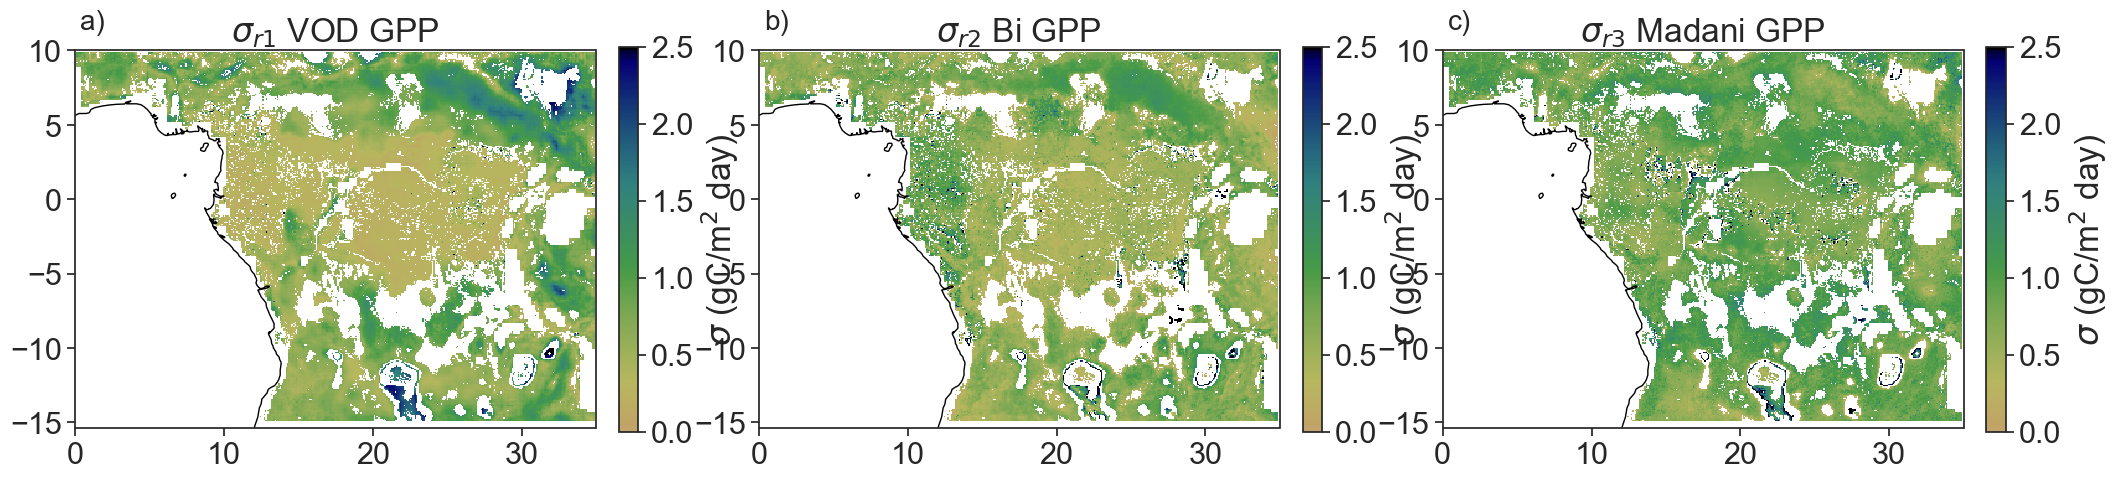

In [44]:
# Define colormap starting at light brown
original_cmap = plt.get_cmap('gist_earth_r')
start, stop = 0.2, 1.0  # Select the portion of the colormap to use (light brown to white)
colors = original_cmap(np.linspace(start, stop, 256))  # Crop the colormap
custom_cmap = mcolors.LinearSegmentedColormap.from_list("custom_gist_earth_r", colors)

# Plot titles and data limits for each subplot
titles = [r'$\sigma_{r1}$ VOD GPP', r'$\sigma_{r2}$ Bi GPP', r'$\sigma_{r3}$ Madani GPP']
data_limits = [(0, 2.5), (0, 2.5), (0, 2.5)]  # vmin and vmax for each plot
labels = ['a)', 'b)', 'c)']  # Subplot labels

# Create the figure and subplots
fig, axes = plt.subplots(
    1, 3,
    figsize=(25, 5),
    subplot_kw={'projection': ccrs.PlateCarree()},
)

# Plot each subplot
for i, ax in enumerate(axes):
    im = ax.pcolormesh(
        err.lon, err.lat, np.sqrt(err[i, :, :]),
        transform=ccrs.PlateCarree(),
        cmap=custom_cmap,
        vmin=data_limits[i][0],
        vmax=data_limits[i][1]
    )

    ax.coastlines()
    ax.set_title(titles[i], loc='center')

    # Subplot label
    ax.text(
        0.01, 1.04, labels[i],
        fontsize=20,
        transform=ax.transAxes,
        ha='left', va='bottom'
    )
    ax.set_extent([0, 35, -15, 10])
    ax.set_xticks([ 0, 10, 20, 30], crs=ccrs.PlateCarree())
    ax.set_yticks([-15, -10,-5, 0, 5, 10], crs=ccrs.PlateCarree())
    # Colorbar attached to this axis 
    cb = fig.colorbar(
        im, ax=ax,
        orientation='vertical',
        fraction=0.046,  # width of colorbar w.r.t. axes
        pad=0.04         # space between axes and colorbar
    )
    cb.set_label(r'$\sigma$ (gC/m$^2$ day)')

plt.savefig(
    '/Users/sworden/Documents/EqAfricaGPPETResults/TripleCollocationMap_Subplots.png',
    format='png', bbox_inches='tight'
)
plt.show()


### Table S3

In [45]:
GLDAS_GLOB = os.path.join(filepath, "GLDASLongTermET", "*")
gldas_files = sorted(glob.glob(GLDAS_GLOB))
RUN_TABLE_S3 = bool(gldas_files)

if RUN_TABLE_S3:
    dsGLDAS = xr.open_mfdataset(
        gldas_files, concat_dim="time", combine="nested",
        compat="override", coords="all"
    ).sel(lat=slice(-20, 15), lon=slice(0, 50))
    GLDASET = dsGLDAS.Evap_tavg
else:
    warnings.warn(
        f"Table S3 skipped: no GLDAS files found at {GLDAS_GLOB}. "
        "Update GLDAS_GLOB to the correct location."
    )


C:\Users\sworden\AppData\Local\Temp\ipykernel_46324\1194061856.py:12: UserWarning: Table S3 skipped: no GLDAS files found at /Users/sworden/Documents\GLDASLongTermET\*. Update GLDAS_GLOB to the correct location.
  warnings.warn(


In [46]:
if RUN_TABLE_S3:
    def _monthly_mean_start(da: xr.DataArray) -> xr.DataArray:
        """
        Coerce to month-start timestamps and collapse duplicates by monthly mean.
        This works for strictly-monthly data as well as sub-monthly (e.g. 8-day).
        """
        # Ensure time is a pandas-compatible datetime64
        da2 = da.copy()
        da2 = da2.assign_coords(time=pd.to_datetime(da2['time'].values))

        # Resample to month-start ('MS' = Month Start)
        da2 = da2.resample(time='MS').mean(keep_attrs=True)

        # Make sure time is sorted 
        da2 = da2.sortby('time')

        return da2

    def regrid_to_template(da: xr.DataArray, template: xr.DataArray) -> xr.DataArray:
        """Bilinear interp da to template's lat/lon grid (keeps all other coords)."""
        da = _ensure_latlon(da)
        tmpl = _ensure_latlon(template)
        same_grid = (
            {'lat','lon'}.issubset(da.dims)
            and {'lat','lon'}.issubset(tmpl.dims)
            and np.array_equal(da['lat'], tmpl['lat'])
            and np.array_equal(da['lon'], tmpl['lon'])
        )
        return da if same_grid else da.interp(lat=tmpl['lat'], lon=tmpl['lon'], method='linear')

    def align_all_time_inner(*arrays: xr.DataArray):
        """Coerce ALL to month-start and take inner join across ALL inputs."""
        arrays_ms = [_monthly_mean_start(a) for a in arrays]
        return list(xr.align(*arrays_ms, join='inner'))

    # Use the Congo-domain AET grid explicitly (previously this depended on AET being overwritten earlier)
    AET_TC = AET.sel(lat=slice(-15, 10), lon=slice(0, 35))
    GLDASET = _ensure_latlon(dsGLDAS['Evap_tavg'])

    Bi_GPP_rg  = regrid_to_template(BiGPP, AET_TC)
    VOD_GPP_rg = regrid_to_template(GPP_VOD, AET_TC)
    GPPNew_rg  = regrid_to_template(GPPNew, AET_TC)
    GLDASET_rg = regrid_to_template(GLDASET, AET_TC)

    AET_ms, GLD_ms, Bi_ms, VOD_ms, New_ms = align_all_time_inner(
        AET_TC, GLDASET_rg, Bi_GPP_rg, VOD_GPP_rg, GPPNew_rg
    )


In [47]:
if RUN_TABLE_S3:
    warnings.filterwarnings("ignore")
    try:
        VPD_THR_BAR = VPD_star if np.isfinite(VPD_star) else VPD_THR_LINE
    except NameError:
        VPD_THR_BAR = VPD_THR_LINE

    VPD_da = VPDArr.mean(dim='time')
    B_da   = JRC_static  # 0 Intact, 1 Disturbed, 2 Other, 3 Mixed

    pairs = [
        ("Bi–AET",        Bi_ms,     AET_ms),
        ("GPPNew–AET",    New_ms,     AET_ms),
        ("VOD–AET",       VOD_ms,    AET_ms),

        ("Bi–GLDAS",      Bi_ms,     GLD_ms),
        ("GPPNew–GLDAS",  New_ms,     GLD_ms),
        ("VOD–GLDAS",     VOD_ms,    GLD_ms),
    ]

    def _align_pair(GPPi, ETi, VPD_da, B_da):
        """
        Align GPP, ET, VPD in time/lat/lon (inner join), and align bucket (lat/lon).
        Returns: GPP2(time,lat,lon), ET2(time,lat,lon), VPD2(time,lat,lon), B2(lat,lon)
        """
        GPPi = _ensure_latlon(GPPi)
        ETi  = _ensure_latlon(ETi)
        VPD  = _ensure_latlon(VPD_da)
        B    = _drop_time_if_present(_ensure_latlon(B_da))

        # align time + space among time-varying fields
        GPP2, ET2, VPD2 = xr.align(GPPi, ETi, VPD, join="inner")

        # align bucket to that grid (lat/lon only)
        B2, _ = xr.align(B, GPP2.isel(time=0, drop=True), join="inner")

        return GPP2, ET2, VPD2, B2

    def _corr_per_pixel_over_time(x, y):
        """
        Vectorized Pearson r per pixel for x,y shaped (ntime, npix),
        handling NaNs with pairwise validity.
        """
        x = np.asarray(x, float)
        y = np.asarray(y, float)

        m = np.isfinite(x) & np.isfinite(y)          # (ntime, npix)
        n = m.sum(axis=0).astype(float)              # (npix,)

        # mask invalid as 0 for sums
        x0 = np.where(m, x, 0.0)
        y0 = np.where(m, y, 0.0)

        # sums
        sumx  = x0.sum(axis=0)
        sumy  = y0.sum(axis=0)
        sumxx = (x0 * x0).sum(axis=0)
        sumyy = (y0 * y0).sum(axis=0)
        sumxy = (x0 * y0).sum(axis=0)

        # means (avoid div by 0)
        mx = np.where(n > 0, sumx / n, np.nan)
        my = np.where(n > 0, sumy / n, np.nan)

        # covariance/variance (population form; correlation is the same)
        cov  = np.where(n > 0, (sumxy / n) - mx * my, np.nan)
        varx = np.where(n > 0, (sumxx / n) - mx * mx, np.nan)
        vary = np.where(n > 0, (sumyy / n) - my * my, np.nan)

        den = np.sqrt(varx * vary)
        r   = cov / den

        # validity: at least 3 points and nonzero variance
        bad = (n < 3) | (~np.isfinite(r)) | (den <= 0)
        r[bad] = np.nan
        return r

    # MAIN: compute 4-category summaries for each pair
    rows_cgo = []
    print("\n=== Pixel-wise R over full period, summarized as mean±std — Congo (4 categories only) ===")

    for label, GPPi, ETi in pairs:

        # 1) Align everything on common time/lat/lon
        GPP2, ET2, VPD2, B2 = _align_pair(GPPi, ETi, VPD_da, B_da)

        # 2) Make a *static* VPD per pixel
        #    Here: mean over the overlapping time of this pair
        VPD_static = VPD2

        # 3) Build the four category masks (lat, lon)
        is_intact = (B2 == 0)
        is_mixed  = (B2 == 3)
        is_other  = (B2 == 2)

        lowV  = (VPD_static <  VPD_THR_BAR)
        highV = (VPD_static >= VPD_THR_BAR)

        groups = [
            ("Intact Low VPD",  is_intact & lowV),
            ("Mixed  Low VPD",  is_mixed  & lowV),
            ("Mixed  High VPD", is_mixed  & highV),
            ("Other  High VPD", is_other  & highV),
        ]

        # 4) Compute pixel-wise R over time for each group
        for group_name, mask_ll in groups:

            gpp_reg = GPP2.where(mask_ll)
            et_reg  = ET2.where(mask_ll)

            gpp_st = gpp_reg.stack(pixel=("lat", "lon"))
            et_st  = et_reg.stack(pixel=("lat", "lon"))

            x = gpp_st.values  # (ntime, npix)
            y = et_st.values   # (ntime, npix)

            if x.size == 0 or y.size == 0:
                mean_R, std_R, Npix = np.nan, np.nan, 0
            else:
                Rpix  = _corr_per_pixel_over_time(x, y)
                valid = np.isfinite(Rpix)

                if valid.sum() > 0:
                    mean_R = float(np.nanmean(Rpix[valid]))
                    std_R  = float(np.nanstd(Rpix[valid]))
                    Npix   = int(valid.sum())
                else:
                    mean_R, std_R, Npix = np.nan, np.nan, 0

            print(f"{group_name} — {label}:  R_mean={mean_R:.3f}   R_std={std_R:.3f}   Npix={Npix}")

            rows_cgo.append({
                "Group(Congo)": group_name,
                "Pair":         label,
                "Mean R":       mean_R,
                "Std R":        std_R,
                "N pixels":     Npix,
            })

    df_cgo = pd.DataFrame(rows_cgo)

    summary_R_cgo   = df_cgo.pivot(index="Group(Congo)", columns="Pair", values="Mean R")
    summary_std_cgo = df_cgo.pivot(index="Group(Congo)", columns="Pair", values="Std R")
    summary_N_cgo   = df_cgo.pivot(index="Group(Congo)", columns="Pair", values="N pixels")

    print("\n--- Mean R (Congo; 4 categories) ---")
    print(summary_R_cgo)

    print("\n--- Std(R) across pixels (Congo; 4 categories) ---")
    print(summary_std_cgo)

    print("\n--- N pixels (Congo; 4 categories) ---")
    print(summary_N_cgo)
